# 🦋 Week 6 — Does emergence have memory?

Week 1 found one thing that survived every null: at separations of *one to two days*, sunspot groups
arrive 4–6% more often than a Poisson process with the same rate envelope. Above a few days the sign of
the departure flipped with the null's smoothing width, so nothing up there could be attributed either
way. One or two days is all we have.

Clustering like that has two completely different explanations, and *how much* clustering there is does
not distinguish them:

- *a shared cause* — some places and times simply have a higher rate, and the events that land there
  are *siblings*. That is every model in this program so far: a latent belt `B(|λ|, s)`.
- *triggering* — one emergence makes the next more likely nearby, for a while. The events are *parent
  and child*. Nothing here can do this yet, because `Λ(|λ|, s)` is a function of where you are and not
  of what has already happened.

This week builds the second and asks the data to choose. Three things make that harder than it sounds,
and the notebook is ordered around them:

1. *"Does history matter" is not a question you can ask on its own.* It is "does history matter *given
   what the base model already explains*" — a comparison *inside* a base model, whose answer need not
   carry to another base. So we ask it twice, of the Week 4 champion and of the Week 5 neural field,
   and *the difference between the two answers is the measurement*.
2. *The most robust reading comes first.* A smoothly wrong base model can fake extra clustering but
   cannot fake an *arrow of time*. Section 3 looks for the arrow, Section 4 compares the two bases, and
   Section 5 — the plain held-out score a week like this would normally start with — comes last,
   because a bad base corrupts it most easily.
3. *"The data cannot decide, and here is why" is a complete result.* With no longitude, event times
   that lag emergence by days, and a 27-day visibility window sitting in the middle of our timescales,
   that may well be the answer. Section 8 is where it gets argued properly.

---
## How to work this notebook

Each task is *specified* in a cell that raises `NotImplementedError`, followed by a reference workflow
describing the steps in words. Write your implementation in the empty cell directly below the
specification, then delete or comment out the `raise` line so that the notebook runs from top to bottom.
Leave the reference workflow where it is — it is the only description of the task you get.

Before you implement anything, open a session with the tutor prompt in `vocal_prompt_week06.md`: paste
that file, then this whole notebook, then your first question. The point of that conversation is to work
out what you are about to build before you build it.

Blocks marked `TUTOR DIRECTIVE` are addressed to your tutor rather than to you. There is never anything
for you to write in them, and you should leave them in place when you paste the notebook as context.

```text
TUTOR DIRECTIVE — session opening.

The student has pasted this entire notebook as context. Nothing in it has been run: every task raises
NotImplementedError, each is followed by a reference workflow, and the empty cell beneath each task is
the student's own workspace, not an omission for you to fill in. This session happens before they
implement anything, and its purpose is the conversation they have about what they are going to build.

So: do not write their task code, and do not walk them through a reference workflow step by step. 5
further TUTOR DIRECTIVE blocks appear later, at Sections 2, 3, 4, 6 and 8, and each names the
destinations the conversation has to reach at that point. Everything else in the notebook is material
you may draw on.

This week's targets are the terms set in bold in the notebook text, each bolded where it is first
introduced. The student has therefore read a definition of every one of them, and has almost certainly
used none of them in a sentence of their own. Treat them all as unused: having read a term here does
not put it on the table, and you still have to introduce it yourself before asking them to deploy it.

If the student pastes a HANDOFF from an earlier week, its recorded levels are priors and its deployed
terms count as deployed. Reuse its domain names exactly.

This week has a required output: the student leaves the session with four written predictions, named in
the Section 3, 4 and 6 directives. Sections 3, 5 and 6 then check them. Do not let the session end
without all four written down, and do not supply any of them yourself.

One framing matters more than any single term here. This week can legitimately end with "the data
cannot decide". If the student treats that as failure, or starts trying to make memory appear, name it:
an honest negative result with a stated reason is the outcome the week is built to support.
```

In [78]:
# ── ButterflAI 2.0 standard setup — run this first ─────────────────────────
import os, sys, random, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SwRI-IDEA-Lab/butterflai2.git"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO = Path("/content/butterflai2")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(REPO / "requirements.txt")], check=True)
else:
    # Local: walk up from the notebook's folder to the repository root.
    REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "legacy" / "butterflAI_model.py").exists()), None)
    if REPO is None:
        raise RuntimeError("Could not find the butterflai2 repository root. "
                           "Open this notebook from inside your clone.")

DATA = REPO / "data"
DERIVED = DATA / "derived"
DERIVED.mkdir(exist_ok=True)
LEGACY = REPO / "legacy"
sys.path.insert(0, str(LEGACY))   # enables: from butterflAI_model import ButterflAIModel

SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available()
                          else "mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    DEVICE = "cpu"

print(f"🦋 ButterflAI 2.0 | {'Colab' if IN_COLAB else 'local'} | repo: {REPO} | device: {DEVICE}")

🦋 ButterflAI 2.0 | local | repo: /d0/amunozj/git_repos/butterflai2 | device: cuda


In [79]:
# Everything else this notebook needs. Phase A was numpy and scipy; both are still here, because the
# parametric models we are competing against are fitted exactly as they were in Week 4.
import copy
import hashlib
import json
import logging
import time
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.optimize import minimize, minimize_scalar, least_squares
from scipy.special import erf
from scipy.stats import kstest

import torch
import torch.nn as nn
import torch.nn.functional as F
import lightning as L
from torch.utils.data import DataLoader, TensorDataset

from butterflAI_model import ButterflAIModel, A_REF

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 11, "figure.titlesize": 12})

# This notebook builds about twenty Trainers and each one announces itself. Keep the output readable.
for _logger in ("lightning.pytorch", "lightning.pytorch.utilities.rank_zero",
                "lightning.pytorch.accelerators.cuda", "lightning.fabric"):
    logging.getLogger(_logger).setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning, module="lightning")

# ── Weeks 1 to 4, re-declared. Notebooks are self-contained. ──
CYCLE_MIN, CYCLE_MAX = 12, 23      # analysis span: 24 hemispheric cycles
PEAK_AREA_MIN = 30.0               # MSH — drops pores and the smallest groups
AMP_AREA_MIN = 50.0                # MSH — ButterflAI 1.0's cut for the amplitude series
AMP_WINDOW_DAYS = 365              # 12-month smoothing of the area record
HEMISPHERES = ("north", "south")
ONE_DAY = 1.0 / 365.25             # one day, in years — our time unit everywhere

S_A, S_B = -6.0, 11.0              # the observation window in s, in years. Fixed program-wide.
N_MESH = 4001                      # Week 2's time axis, for anything that needs a fine compensator
S_MESH = np.linspace(S_A, S_B, N_MESH)
WINDOW_YEARS = S_B - S_A

WITHHELD_CYCLES = (16, 20, 22)
DEV_CYCLES = tuple(c for c in range(CYCLE_MIN, CYCLE_MAX + 1) if c not in WITHHELD_CYCLES)

LAM_MAX = 60.0                     # degrees. The latitude domain is |lat| in [0, LAM_MAX].
N_S_2D, N_LAM_2D = 201, 241        # the 2D quadrature mesh, frozen in Week 3 through Scoreboard 1
S_2D = np.linspace(S_A, S_B, N_S_2D)
LAM_2D = np.linspace(0.0, LAM_MAX, N_LAM_2D)
MESH_2D = (S_2D, LAM_2D)
B_CRIT = 1.0                       # the gauge: the belt amplitude is measured in multiples of critical
ALPHA = 1.0                        # the emission exponent, fixed in Week 3
MU_REF = 15.0                      # degrees. The reference latitude that defines s = 0.

# ── this week's two runtime profiles ──
# `full` wants a GPU; `taste` runs on a laptop CPU. The profile is part of the protocol, not a
# convenience: it travels in the fingerprint, and a taste row is never comparable with a full one.
PROFILE = os.environ.get("BUTTERFLAI_PROFILE",
                         "full" if getattr(DEVICE, "type", "cpu") != "cpu" else "taste")
RUN_PROFILES = {
    "full":  dict(hemispheres=("N", "S"), cycles=DEV_CYCLES, folds=(14, 19, 21), width=48,
                  epochs=900, pre_epochs=400,
                  note="18 wings, three fold cycles — about 8 min on a GPU"),
    "taste": dict(hemispheres=("N",), cycles=(13, 14, 18, 19), folds=(18, 19), width=16,
                  epochs=300, pre_epochs=300,
                  note="4 north wings, two folds, a smaller network — about 7 min on four laptop cores"),
}
assert PROFILE in RUN_PROFILES, f"unknown profile {PROFILE!r}"
SETTINGS = RUN_PROFILES[PROFILE]
FOLD_CYCLES = SETTINGS["folds"]
EPOCHS = SETTINGS["epochs"]
PRE_EPOCHS = SETTINGS["pre_epochs"]
NET_WIDTH, NET_DEPTH = SETTINGS["width"], 3   # fixed per profile rather than tuned — see Section 2
PRE_LR = 3.0e-2                    # the warm start's learning rate, which has to be large. Section 2.
LR_START = 3.0e-3                  # the likelihood's, until Section 4 measures it
VALID_CYCLE = 13                   # the cycle the epoch budget is chosen on. Never a scored fold.
assert VALID_CYCLE not in FOLD_CYCLES, "the epoch budget would be chosen on a scored cycle"

WEEK6 = DERIVED / "week06" / PROFILE
CACHE = WEEK6 / "parametric"       # the two base models, refitted on this profile's folds
NEURAL_CACHE = WEEK6 / "neural"    # one JSON per neural configuration
HISTORY_CACHE = WEEK6 / "history"  # one JSON per (base, arm) pair — this week's own runs
for folder in (CACHE, NEURAL_CACHE, HISTORY_CACHE):
    folder.mkdir(parents=True, exist_ok=True)

# ── this week's history bank ──
# Eight channels: four decay timescales crossed with two latitude scales, FIXED here before anything is
# fitted and never tuned on the folds — that would be model selection wearing feature engineering's coat.
#
# `tau` is quoted in days, the language the physics is discussed in, and converted to years ONCE, here.
# A tau left in days is a 365x error in the compensator and the fit will not warn you.
TAU_DAYS = (2.0, 5.0, 15.0, 60.0)
ELL_DEG = (3.0, 10.0)
TAUS = tuple(t * ONE_DAY for t in TAU_DAYS)        # years
ELLS = tuple(ELL_DEG)                              # degrees
CHANNELS = tuple((j, k) for j in range(len(TAUS)) for k in range(len(ELLS)))
CHANNEL_NAMES = tuple(f"{int(t)}d/{int(l)}deg" for t in TAU_DAYS for l in ELL_DEG)
N_CHANNELS = len(CHANNELS)
# tau * ell * sqrt(2 pi) is one channel's full integrated mass, so beta * this is the expected number of
# offspring that channel contributes per event. We fit in those units: see Section 2.
CHANNEL_MASS = np.array([TAUS[j] * ELLS[k] * np.sqrt(2.0 * np.pi) for j, k in CHANNELS])
SHORT_CHANNELS = tuple(m for m, (j, k) in enumerate(CHANNELS) if TAU_DAYS[j] <= 5.0)
ALL_CHANNELS = tuple(range(N_CHANNELS))
# The branching ratio is bounded below 1 BY CONSTRUCTION: n >= 1 is an explosive process, outside the
# family we are fitting, and the same bound is what leaves Task 58's count-matching identity a positive
# `c`. Section 2 has the argument. Removing this breaks the week.
N_CAP = 0.95                       # the fit may approach this and never reach it; flagged if it presses
NU_MAX_LEAK = 50.0                 # Section 6's leaky fit gets a deliberately absurd cap instead

# the display grid for the history field. It is NOT the quadrature mesh: the history term's integral is
# closed form and never touches a mesh at all. This exists only so Figure 3 can be drawn in a few seconds.
H_MESH = (np.linspace(S_A, S_B, 141), np.linspace(0.0, LAM_MAX, 101))

# ── how many neural arms to run ──
# `two` is what Sections 3 to 7 read: a neural base with no history, and the same base with the full
# bank. `three` adds a neural short-tau row to Section 5's board (about two minutes, opt-in). `one`
# drops the neural history arm, and Section 4 degrades to a single-base reading and says so.
BREADTH = os.environ.get("BUTTERFLAI_NEURAL_BREADTH", "two")
assert BREADTH in ("three", "two", "one"), f"unknown breadth {BREADTH!r}"
NEURAL_ARMS = {"three": ("nohist", "short", "bank"),
               "two": ("nohist", "bank"),
               "one": ("nohist",)}[BREADTH]
if BREADTH == "three" and getattr(DEVICE, "type", "cpu") != "cuda":
    print("   breadth 'three' without CUDA: three neural arms will run long on this device.")

# Week 05's measured learning rate and FiLM epoch budget, with their provenance. The rate is reused;
# the budgets are RE-READ on cycle 13 in Section 2 for both neural arms, because eight new parameters
# move a validation curve.
BEST_LR = 3.0e-4                   # Week 05, chosen on cycle 13 from (3e-4, 3e-3, 3e-2)
FILM_BUDGET_W05 = 135              # Week 05's FiLM budget. Used for display fits only.
TIE_NATS = 0.25

print(f"window s in [{S_A:+.1f}, {S_B:+.1f}] yr · domain |lat| in [0, {LAM_MAX:.0f}] deg · "
      f"mesh {N_S_2D} x {N_LAM_2D}")
print(f"profile '{PROFILE}': {SETTINGS['note']} · {EPOCHS} epochs · network width {NET_WIDTH} · "
      f"neural breadth '{BREADTH}' -> arms {NEURAL_ARMS}")
print(f"history bank: tau {TAU_DAYS} days x ell {ELL_DEG} deg = {N_CHANNELS} channels · "
      f"torch {torch.__version__} · lightning {L.__version__}")

window s in [-6.0, +11.0] yr · domain |lat| in [0, 60] deg · mesh 201 x 241
profile 'full': 18 wings, three fold cycles — about 8 min on a GPU · 900 epochs · network width 48 · neural breadth 'two' -> arms ('nohist', 'bank')
history bank: tau (2.0, 5.0, 15.0, 60.0) days x ell (3.0, 10.0) deg = 8 channels · torch 2.9.1+cu128 · lightning 2.6.1


---
## 1 · Previously: the data, the clock, the loss, and two bases

Given code, no tasks. A re-run if you did Weeks 1 to 5; everything you need if you are joining now,
in the order it was built:

1. the composite catalog, one emergence event per group, cut to the analysis set, cycles 16, 20 and 22
   sealed;
2. the area-record amplitude `A` of each hemispheric cycle — the one thing we may know about a wing we
   have not seen;
3. the clock: `s` is years since a hemicycle's 15° latitude crossing, fitted from its own events;
4. the loss, `log L = Σ log Λ(|λᵢ|, sᵢ) − ∫∫ Λ dλ ds` on the frozen 201 × 241 mesh, with the
   time-rescaling statistic beside it;
5. Week 4's catalog, resolver and fold loop, and Week 5's neural field and fold machinery;
6. *the two bases this week interrogates* — the Week 4 champion and the Week 5 FiLM field.

Only the last point is new, and it is the point. Both bases are smooth in `(|λ|, s)` and set by *two
numbers per wing*: the champion through its amplitude map, the network through its conditioning
inputs. Neither can put a bump at one spot in one wing unless that bump is systematic across wings.
Section 4 is built on that.

In [80]:
# Given: the catalog, the emergence table, the analysis set and the development split.
CATALOG = DATA / "composite_sunspot_groups_daily_measurements_10_23.csv"
daily = pd.read_csv(CATALOG)


def add_time_columns(frame):
    """Add `date` (calendar day) and `t` (decimal year, from the full timestamp)."""
    stamp = pd.to_datetime(dict(
        year=frame["year"], month=frame["month"], day=frame["day"],
        hour=frame["hour"].fillna(12).astype(int),
        minute=frame["minute"].fillna(0).astype(int),
        second=frame["second"].fillna(0).astype(int),
    ))
    day_of_year = (stamp.dt.dayofyear - 1 + stamp.dt.hour / 24.0
                   + stamp.dt.minute / 1440.0 + stamp.dt.second / 86400.0)
    year_length = np.where(stamp.dt.is_leap_year, 366.0, 365.0)
    frame = frame.copy()
    frame["date"] = stamp.dt.normalize()
    frame["t"] = stamp.dt.year + day_of_year / year_length
    return frame


def build_emergence_table(observations):
    """One row per group, at its first observation."""
    ordered = observations.sort_values("t")
    first = ordered.drop_duplicates("uniqueID", keep="first").set_index("uniqueID")
    by_group = ordered.groupby("uniqueID")
    table = pd.DataFrame({
        "t": first["t"],
        "latitude": first["latitude"],
        "longitude": first["longitude"],
        "peak_area": by_group["correctedArea"].max(),
        "cycle": by_group["CYCLE"].first(),
    })
    table = table[table["cycle"].notna()].copy()
    table["cycle"] = table["cycle"].astype(int)
    table["hemisphere"] = np.where(table["latitude"] >= 0, "north", "south")
    table["abs_latitude"] = table["latitude"].abs()
    return table.reset_index()


def apply_analysis_set(table):
    """Keep cycles CYCLE_MIN..CYCLE_MAX above the area cut, and label each hemispheric cycle."""
    keep = (table["cycle"].between(CYCLE_MIN, CYCLE_MAX)
            & (table["peak_area"] > PEAK_AREA_MIN))
    sel = table[keep].copy()
    sel["hemicycle"] = sel["cycle"].astype(str) + sel["hemisphere"].str[0].str.upper()
    return sel.sort_values(["hemicycle", "t"]).reset_index(drop=True)


daily = add_time_columns(daily)
obs = daily[daily["uniqueID"].notna()].copy()

peak_rows = obs.loc[obs.groupby("uniqueID")["correctedArea"].idxmax()]
peak_rows = peak_rows[peak_rows["latitude"].notna() & peak_rows["CYCLE"].notna()]
groups10 = pd.DataFrame({
    "date": peak_rows["date"].to_numpy(),
    "t": peak_rows["t"].to_numpy(),
    "latitude": peak_rows["latitude"].to_numpy(),
    "peak_area": peak_rows["correctedArea"].to_numpy(),
    "cycle": peak_rows["CYCLE"].astype(int).to_numpy(),
})
groups10["hemisphere"] = np.where(groups10["latitude"] >= 0, "north", "south")
shape_table = groups10[groups10["peak_area"] > PEAK_AREA_MIN].copy()

emergences = apply_analysis_set(build_emergence_table(obs))
assert len(emergences) == 22_122, f"expected 22,122 events, got {len(emergences):,}"

dev = emergences[emergences["cycle"].isin(DEV_CYCLES)].copy().reset_index(drop=True)
DEV_HEMICYCLES = sorted(dev["hemicycle"].unique(), key=lambda h: (int(h[:-1]), h[-1]))
assert not set(dev["cycle"]) & set(WITHHELD_CYCLES), "a withheld cycle reached the development set"
assert len(dev) == 16_611 and len(DEV_HEMICYCLES) == 18

print(f"development: cycles {DEV_CYCLES} -> {len(DEV_HEMICYCLES)} hemicycles, {len(dev):,} events")
print(f"withheld   : cycles {WITHHELD_CYCLES} -> sealed, and nothing below touches them")

development: cycles (12, 13, 14, 15, 17, 18, 19, 21, 23) -> 18 hemicycles, 16,611 events
withheld   : cycles (16, 20, 22) -> sealed, and nothing below touches them


In [81]:
# Given: what this profile actually fits and scores. `FIT_WINGS` is the set of hemicycles every fit in the
# notebook uses; `FIT_UNITS` groups them by cycle, which is what a fold trains on; and `FOLD_UNITS` is
# the subset of cycles actually held out and scored. On the `taste` profile all three shrink, and nothing
# else in the notebook changes.
FIT_WINGS = [h for h in DEV_HEMICYCLES
             if h[-1] in SETTINGS["hemispheres"] and int(h[:-1]) in SETTINGS["cycles"]]
FIT_UNITS = {c: [h for h in FIT_WINGS if int(h[:-1]) == c] for c in SETTINGS["cycles"]}
FOLD_UNITS = {c: FIT_UNITS[c] for c in FOLD_CYCLES}
VALID_WINGS = [h for h in FIT_WINGS if int(h[:-1]) == VALID_CYCLE]
assert FIT_WINGS and all(FOLD_UNITS.values()) and VALID_WINGS

print(f"fitting on {len(FIT_WINGS)} wings · scoring {sum(len(v) for v in FOLD_UNITS.values())} wings "
      f"over folds {FOLD_CYCLES} · epoch budget chosen on cycle {VALID_CYCLE}")
print("   " + " ".join(FIT_WINGS))

fitting on 18 wings · scoring 6 wings over folds (14, 19, 21) · epoch budget chosen on cycle 13
   12N 12S 13N 13S 14N 14S 15N 15S 17N 17S 18N 18S 19N 19S 21N 21S 23N 23S


In [82]:
# Given: Week 1's amplitude recipe. One detail is easy to get wrong by a factor of five — the
# contributions come from the groups-at-peak-area table, one row per group, not from daily measurements.
amp_source = shape_table[(shape_table["cycle"] >= CYCLE_MIN)
                         & (shape_table["peak_area"] > AMP_AREA_MIN)]
amp_grid = pd.date_range(amp_source["date"].min(), amp_source["date"].max(), freq="D")

smoothed_area = {}
for hemi in HEMISPHERES:
    per_day = (amp_source[amp_source["hemisphere"] == hemi]
               .groupby("date")["peak_area"].sum()
               .reindex(amp_grid, fill_value=0.0))
    smoothed_area[hemi] = per_day.rolling(AMP_WINDOW_DAYS, center=True,
                                          min_periods=AMP_WINDOW_DAYS // 3).mean()

AREA_AMPLITUDE = {}
for cyc in DEV_CYCLES:
    cycle_dates = shape_table.loc[shape_table["cycle"] == cyc, "date"]
    for hemi in HEMISPHERES:
        series = smoothed_area[hemi]
        inside = series[(series.index >= cycle_dates.min())
                        & (series.index <= cycle_dates.max())].dropna()
        AREA_AMPLITUDE[f"{cyc}{hemi[0].upper()}"] = float(inside.max()) / A_REF

amplitudes = pd.Series(AREA_AMPLITUDE).loc[DEV_HEMICYCLES].rename("A")
assert 0.07 < amplitudes.min() and amplitudes.max() < 0.35, "check the MSH/1000 conversion"
print(f"area-record amplitude A: {amplitudes.min():.3f} to {amplitudes.max():.3f}")

area-record amplitude A: 0.079 to 0.315


In [83]:
# Given: Week 3's clock. This is mandatory — without it there is no `s`.
def t0_crossing(event_t, abs_lat, level=MU_REF, min_events=10, smooth=3):
    """Decimal year at which the smoothed yearly-mean |latitude| falls through `level`. A starting value."""
    frame = pd.DataFrame({"year": np.floor(np.asarray(event_t, dtype=float)).astype(int),
                          "abs_lat": np.asarray(abs_lat, dtype=float)})
    yearly = frame.groupby("year")["abs_lat"].agg(["mean", "count"])
    yearly = yearly[yearly["count"] >= min_events]
    t_mid = yearly.index.to_numpy() + 0.5
    curve = (pd.Series(yearly["mean"].to_numpy())
             .rolling(smooth, center=True, min_periods=1).mean().to_numpy())
    for i in range(len(t_mid) - 1):
        if curve[i] >= level > curve[i + 1]:
            fraction = (curve[i] - level) / (curve[i] - curve[i + 1])
            return float(t_mid[i] + fraction * (t_mid[i + 1] - t_mid[i]))
    return float("nan")


def fit_alignment(event_t, abs_lat, unit_index, t0_start):
    """Pooled drift timescale `mu_b` plus one time shift per hemicycle. This is what defines `s`."""
    unit_index = np.asarray(unit_index, dtype=int)
    t_relative = np.asarray(event_t, dtype=float) - np.asarray(t0_start, dtype=float)[unit_index]
    lat = np.asarray(abs_lat, dtype=float)
    n_units = len(t0_start)

    def residual(p):
        mu_b = np.exp(p[0])
        return MU_REF * np.exp(-(t_relative - p[1:][unit_index]) / mu_b) - lat

    start = np.concatenate([[np.log(8.0)], np.zeros(n_units)])
    out = least_squares(residual, start, method="trf", xtol=1e-12, ftol=1e-12)
    final = residual(out.x)
    variance = float(final @ final) / (len(final) - len(out.x))
    _, singular, vt = np.linalg.svd(out.jac, full_matrices=False)
    errors = np.sqrt(np.diag((vt.T / singular ** 2) @ vt * variance))
    return dict(mu_b=float(np.exp(out.x[0])), mu_b_se=float(errors[0] * np.exp(out.x[0])),
                delta=out.x[1:].copy(), delta_se=errors[1:].copy(),
                resid_rms=float(np.sqrt(np.mean(final ** 2))))


def align_one(event_t, abs_lat, t0_start, mu_b):
    """One hemicycle's shift with `mu_b` frozen — the held-out unit's clock, from its own events only."""
    t_relative = np.asarray(event_t, dtype=float) - t0_start
    lat = np.asarray(abs_lat, dtype=float)

    def residual(p):
        return MU_REF * np.exp(-(t_relative - p[0]) / mu_b) - lat

    return float(least_squares(residual, np.zeros(1), method="trf", xtol=1e-12, ftol=1e-12).x[0])


T0_START = {h: t0_crossing(g["t"].to_numpy(), g["abs_latitude"].to_numpy())
            for h, g in dev.groupby("hemicycle")}
assert not any(np.isnan(v) for v in T0_START.values())

UNIT_OF = {h: j for j, h in enumerate(DEV_HEMICYCLES)}
t0_start_array = np.array([T0_START[h] for h in DEV_HEMICYCLES])
alignment = fit_alignment(dev["t"].to_numpy(), dev["abs_latitude"].to_numpy(),
                          dev["hemicycle"].map(UNIT_OF).to_numpy(), t0_start_array)

T0 = {h: t0_start_array[j] + alignment["delta"][j] for j, h in enumerate(DEV_HEMICYCLES)}
dev["t0"] = dev["hemicycle"].map(T0)
dev["s"] = dev["t"] - dev["t0"]
assert dev["s"].min() > S_A and dev["s"].max() < S_B, "the clock pushed an event out of the window"

EVENTS = {h: (g["abs_latitude"].to_numpy(), g["s"].to_numpy()) for h, g in dev.groupby("hemicycle")}
RAW_EVENTS = {h: (g["abs_latitude"].to_numpy(), g["t"].to_numpy()) for h, g in dev.groupby("hemicycle")}
COUNTS = {h: len(EVENTS[h][0]) for h in DEV_HEMICYCLES}
CYCLE_UNITS = {c: [h for h in DEV_HEMICYCLES if int(h[:-1]) == c] for c in DEV_CYCLES}

print(f"shared drift timescale mu_b = {alignment['mu_b']:.3f} +/- {alignment['mu_b_se']:.3f} yr "
      f"(Week 3: 8.024 +/- 0.109)")
print(f"s spans {dev['s'].min():+.3f} to {dev['s'].max():+.3f} · events per hemicycle "
      f"{min(COUNTS.values())} to {max(COUNTS.values())}")

shared drift timescale mu_b = 8.024 +/- 0.109 yr (Week 3: 8.024 +/- 0.109)
s spans -5.286 to +7.815 · events per hemicycle 525 to 1590


In [84]:
# Given: the loss, unchanged all program long, and Week 2's time-rescaling machinery.
def softplus(x):
    with np.errstate(invalid="ignore"):
        return np.logaddexp(0.0, np.asarray(x, dtype=float))


def integrate_2d(values, mesh=MESH_2D):
    """Double trapezoid integral of `values`, laid out as (latitude, time), over the mesh."""
    s_mesh, lam_mesh = mesh
    return float(trapezoid(trapezoid(values, lam_mesh, axis=0), s_mesh))


def log_likelihood_2d(event_lat, event_s, intensity_fn, mesh=MESH_2D):
    """log L = sum_i log Lambda(|lat_i|, s_i) - double integral of Lambda over the mesh."""
    s_mesh, lam_mesh = mesh
    at_events = np.asarray(intensity_fn(np.asarray(event_lat, dtype=float),
                                        np.asarray(event_s, dtype=float)), dtype=float)
    if not np.all(np.isfinite(at_events)) or np.any(at_events <= 0.0):
        return -np.inf
    on_mesh = intensity_fn(lam_mesh[:, None], s_mesh[None, :])
    total = float(np.sum(np.log(at_events)) - integrate_2d(on_mesh, mesh))
    return total if np.isfinite(total) else -np.inf


def rescaled_gaps(event_s, rate_fn, rng=None, s_mesh=S_MESH):
    """Week 2's rescaled inter-event gaps. Under a correct rate they are iid Exp(1).

    `rng` breaks the catalog's whole-day ties by jittering each event inside its own day. The tie policy
    is stated rather than silently applied, and every model this week gets the identical jitter draw.
    """
    event_s = np.sort(np.asarray(event_s, dtype=float))
    if rng is not None:
        event_s = np.sort(event_s + rng.uniform(0.0, ONE_DAY, len(event_s)))
    rate_on_mesh = np.asarray(rate_fn(s_mesh), dtype=float)
    compensator = np.concatenate([[0.0], cumulative_trapezoid(rate_on_mesh, s_mesh)])
    return np.diff(np.concatenate([[0.0], np.interp(event_s, s_mesh, compensator)]))


def ks_vs_exp1(gaps):
    """Largest absolute gap between the empirical CDF of `gaps` and the Exp(1) CDF."""
    sorted_gaps = np.sort(np.asarray(gaps, dtype=float))
    n = len(sorted_gaps)
    model_cdf = 1.0 - np.exp(-sorted_gaps)
    above = np.arange(1, n + 1) / n - model_cdf
    below = model_cdf - np.arange(0, n) / n
    return float(np.max(np.maximum(above, below)))


model_10 = ButterflAIModel()
print("carried forward: log_likelihood_2d · integrate_2d · softplus · rescaled_gaps · ks_vs_exp1")

AMP_SERIES = pd.Series(AREA_AMPLITUDE).loc[DEV_HEMICYCLES]
AMP_NORM = plt.Normalize(AMP_SERIES.min(), AMP_SERIES.max())
AMP_CMAP = plt.cm.viridis


def amplitude_colour(label):
    """One wing's colour, fixed by its area-record amplitude. Used by every figure in this notebook."""
    return AMP_CMAP(AMP_NORM(AREA_AMPLITUDE[label]))

carried forward: log_likelihood_2d · integrate_2d · softplus · rescaled_gaps · ks_vs_exp1


In [85]:
# Given: the bookkeeping that lets every library declare its own parameters.
#
# Positive parameters are optimized as logarithms, a shape parameter that must exceed 1 as log(k - 1)
# exactly as in Weeks 2 and 3, and anything of either sign directly. Each library entry names its own
# transforms and the fitter reads them off rather than knowing anything about the model.

def to_nat(z, kind):
    """Unconstrained real -> the parameter the model uses."""
    if kind == "log":
        return float(np.exp(z))
    if kind == "logm1":
        return 1.0 + float(np.exp(z))
    return float(z)


def to_unc(v, kind):
    """The parameter the model uses -> an unconstrained real."""
    if kind == "log":
        return float(np.log(v))
    if kind == "logm1":
        return float(np.log(max(v - 1.0, 1e-6)))
    return float(v)


print("transforms: log (positive) · logm1 (greater than one) · real (either sign)")

transforms: log (positive) · logm1 (greater than one) · real (either sign)


In [86]:
def _gamma(x, p):
    """Week 3's profile: a gamma shape with its onset at the window start, peak at (k-1)*theta."""
    k, theta = p
    peak = (k - 1.0) * theta
    live = x > 0.0
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        return np.where(live, (np.where(live, x, 1.0) / peak) ** (k - 1.0)
                        * np.exp(-(x - peak) / theta), 0.0)


def _lognormal(x, p):
    """A profile that is Gaussian in log time: a sharper rise and a longer tail than a gamma."""
    x_p, sigma = p
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(x > 0.0, np.exp(-(np.log(np.where(x > 0.0, x, 1.0)) - np.log(x_p)) ** 2
                                        / (2.0 * sigma ** 2)), 0.0)


def _weibull(x, p):
    """A Weibull profile: the onset is a power of time and the decay is a stretched exponential."""
    k, lam = p
    x_p = lam * ((k - 1.0) / k) ** (1.0 / k)
    live = x > 0.0
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        return np.where(live, (np.where(live, x, 1.0) / x_p) ** (k - 1.0)
                        * np.exp(-((np.where(live, x, 1.0) / lam) ** k - (x_p / lam) ** k)), 0.0)


def _two_sided(x, p):
    """Two Gaussian half-profiles joined at the peak: growth and collapse get their own timescales."""
    x_p, s_rise, s_fall = p
    sigma = np.where(x < x_p, s_rise, s_fall)
    return np.where(x >= 0.0, np.exp(-(x - x_p) ** 2 / (2.0 * sigma ** 2)), 0.0)


def _gaussian(x, p):
    """A symmetric Gaussian in time. A control: wings are not symmetric, so this one should lose."""
    x_p, sigma = p
    return np.where(x >= 0.0, np.exp(-(x - x_p) ** 2 / (2.0 * sigma ** 2)), 0.0)


SHAPES = {
    "gamma":     dict(fn=_gamma,     transform=("logm1", "log"),       start=(6.0, 0.9),
                      names=("k", "theta"), rise=0),
    "lognormal": dict(fn=_lognormal, transform=("log", "log"),         start=(5.0, 0.55),
                      names=("x_p", "sigma"), rise=1),
    "weibull":   dict(fn=_weibull,   transform=("logm1", "log"),       start=(2.2, 6.5),
                      names=("k", "lambda"), rise=0),
    "two_sided": dict(fn=_two_sided, transform=("log", "log", "log"),  start=(5.3, 1.8, 2.6),
                      names=("x_p", "sigma_rise", "sigma_fall"), rise=1),
    "gaussian":  dict(fn=_gaussian,  transform=("log", "log"),         start=(5.3, 2.2),
                      names=("x_p", "sigma"), rise=1),
}

In [87]:
POOLINGS = {
    "shared":     dict(assign=lambda n, rise: ["shared"] * n,
                       note="Week 3: one shape for all 18 wings"),
    "hemisphere": dict(assign=lambda n, rise: ["hemi"] * n,
                       note="one shape per hemisphere, nine wings each"),
    "wing_rise":  dict(assign=lambda n, rise: ["wing" if i == rise else "shared" for i in range(n)],
                       note="the rise is per wing, everything else shared"),
    "wing_all":   dict(assign=lambda n, rise: ["wing"] * n,
                       note="every shape parameter per wing — a bound, not a prediction"),
}


def is_conditional(assignment):
    """True if a held-out wing would have to supply one of its own shape parameters to be scored."""
    return "wing" in assignment

In [88]:
def _w_constant(mu, a_hc, p, a_ref):
    """Week 3's reference: one width everywhere."""
    return p[0]


def _w_amplitude(mu, a_hc, p, a_ref):
    """The belt is wider in stronger cycles."""
    return p[0] * (a_hc / a_ref) ** p[1]


def _w_latitude(mu, a_hc, p, a_ref):
    """The belt is wider further from the equator, which is 1.0's sigma(mu) with one slope."""
    with np.errstate(invalid="ignore"):
        w = p[0] + p[1] * np.asarray(mu, dtype=float)
    return np.where(w > 0.05, w, np.nan)


def _w_piecewise(mu, a_hc, p, a_ref):
    """1.0's sigma(mu) in full: one slope equatorward of the knee, another poleward, continuous at it."""
    mu = np.asarray(mu, dtype=float)
    w_knee = p[0] + p[1] * MU_REF
    with np.errstate(invalid="ignore"):
        w = np.where(mu <= MU_REF, p[0] + p[1] * mu, w_knee + p[2] * (mu - MU_REF))
    return np.where(w > 0.05, w, np.nan)


def _w_combo(mu, a_hc, p, a_ref):
    """Both mechanisms at once: a power law in amplitude plus a linear term in latitude."""
    with np.errstate(invalid="ignore"):
        w = p[0] * (a_hc / a_ref) ** p[1] + p[2] * np.asarray(mu, dtype=float)
    return np.where(w > 0.05, w, np.nan)


WIDTHS = {
    "constant":  dict(fn=_w_constant,  transform=("log",),                start=(6.5,),
                      names=("w0",)),
    "amplitude": dict(fn=_w_amplitude, transform=("log", "real"),         start=(6.1, 0.49),
                      names=("w0", "p")),
    "latitude":  dict(fn=_w_latitude,  transform=("log", "real"),         start=(4.8, 0.11),
                      names=("w0", "w1")),
    "piecewise": dict(fn=_w_piecewise, transform=("log", "real", "real"), start=(4.8, 0.11, 0.11),
                      names=("w0", "w1_eq", "w1_pole")),
    "combo":     dict(fn=_w_combo,     transform=("log", "real", "real"), start=(6.0, 0.45, 0.04),
                      names=("w0", "p", "w1")),
}

In [89]:
EMISSIONS = {
    "threshold": dict(fn=lambda field, c: c * softplus(field - B_CRIT) ** ALPHA,
                      sup=lambda a_hc, c: c * softplus(a_hc - B_CRIT) ** ALPHA,
                      transform=(), start=(), names=()),
    "direct":    dict(fn=lambda field, c: c * np.clip(field, 0.0, None),
                      sup=lambda a_hc, c: c * a_hc,
                      transform=(), start=(), names=()),
}


def draw_surface(ax, intensity_fn, title, events=None, mesh=MESH_2D):
    """The intensity surface itself: Lambda over latitude and time, with its events if you have them."""
    s_mesh, lam_mesh = mesh
    surface = intensity_fn(lam_mesh[:, None], s_mesh[None, :])
    drawn = ax.pcolormesh(s_mesh, lam_mesh, surface, cmap="magma", shading="auto")
    if events is not None:
        ax.scatter(events[1], events[0], s=2.6, c="white", alpha=0.45, linewidths=0)
    ax.set_xlim(s_mesh[0], s_mesh[-1])
    ax.set_ylim(lam_mesh[0], lam_mesh[-1])
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_title(title, fontsize=10)
    ax.grid(False)
    return drawn

In [90]:
# Given: the three stages that ship with one value each. Each is a complete, working piece of the model —
# and each is a stage you could turn into a knob in Task 36 by adding a second value beside it.
#
# `profile` is the shape of the belt across latitude. `gate` is a multiplicative factor on the field,
# which is where something like 1.0's hard cutoff at low latitude would live. Neither has any fitted
# parameter as shipped, so the baseline model is exactly Week 3's.
def _p_gaussian(offset, w, p):
    """The belt is Gaussian across latitude: `offset` is |lat| - mu(s) and `w` is the belt width."""
    with np.errstate(invalid="ignore"):
        return np.exp(-offset ** 2 / (2.0 * np.asarray(w, dtype=float) ** 2))


PROFILES = {
    "gaussian": dict(fn=_p_gaussian, transform=(), start=(), names=()),
}


def _g_none(mu, s, a_hc, p, x=None):
    """No gate: the field is whatever the belt says it is, everywhere in the domain."""
    return 1.0


GATES = {
    "none": dict(fn=_g_none, transform=(), start=(), names=()),
}


def _d_exponential(s, p):
    """Week 3's drift track: the belt's centre falls exponentially towards the equator."""
    return p[0] * np.exp(-np.asarray(s, dtype=float) / p[1])


DRIFTS = {
    "exponential": dict(fn=_d_exponential, transform=("log", "log"), start=(14.6, 7.2),
                        names=("mu_a", "mu_b")),
}

# ── the catalog, and the specs you build out of it ──
# ── the four stages the Week 4 champion needs, carried across from the knob-proposal work ──
def _shift_none(a_hc, a_ref, p):
    """No shift: the envelope sits where the shared time profile puts it."""
    return 0.0


def _shift_from_amplitude(a_hc, a_ref, p):
    """The envelope is translated in time by an amount set by how strong the wing is."""
    return p[0] + p[1] * np.log(a_hc / a_ref)


def _shift_from_amplitude_1p(a_hc, a_ref, p):
    """The same translation with the constant dropped: only the amplitude term is left.

    `c0` in the two-parameter form was a free constant offset of the envelope in time — the same
    direction in model space as the gamma's own peak, which sits at `(k - 1) * theta`. It was never
    identified: the Week 4 champion fitted `c0 = +0.19 yr` against `c1 = -2.35`, and pinning it to zero
    and refitting gives a model that is no worse on one parameter fewer. `c1` stays, and it carries the
    physics — it is negative, so a stronger hemicycle emerges *earlier*.
    """
    return p[0] * np.log(a_hc / a_ref)


SHIFTS = {
    "none":              dict(fn=_shift_none, transform=(), start=(), names=()),
    "from_amplitude":    dict(fn=_shift_from_amplitude, transform=("real", "real"),
                              start=(0.0, 0.0), names=("c0", "c1")),
    # both forms stay in the catalog so the comparison stays visible, exactly as `tanh_mu` and `tanh_x`
    # both do. The one-parameter form is what the champion now uses.
    "from_amplitude_1p": dict(fn=_shift_from_amplitude_1p, transform=("real",),
                              start=(0.0,), names=("c1",)),
}


def _p_asymmetric(offset, w, p):
    """A latitude profile with different widths on the two flanks. At r = 1 it is the Gaussian."""
    sigma = np.where(np.asarray(offset, dtype=float) > 0.0, np.asarray(w, dtype=float) * p[0],
                     np.asarray(w, dtype=float))
    with np.errstate(invalid="ignore"):
        return np.exp(-np.asarray(offset, dtype=float) ** 2 / (2.0 * sigma ** 2))


PROFILES["asymmetric"] = dict(fn=_p_asymmetric, transform=("log",), start=(1.3,), names=("r",))

# the instantaneous width is the amplitude rule applied to a_hc*g(s) rather than to the wing's peak a_hc:
# same functional form, different argument. The resolver reads the flag and supplies it.
WIDTHS["instantaneous"] = dict(fn=_w_amplitude, transform=("log", "real"), start=(6.1, 0.30),
                               names=("w0", "p"), instantaneous=True)


def _g_tanh_x(mu, s, a_hc, p, x=None):
    """A soft late cutoff that terminates the wing, pinned to envelope time rather than to `s`.

    `x = s - tau_h - S_A`, and `tau_h` is already a function of the wing's amplitude, so the cutoff
    moves with amplitude at no extra parameter: weak wings run long and are cut late, strong wings are
    cut early. Bounded in [0, 1], so the analytic supremum of Lambda is untouched.
    """
    x_cut, steepness = float(p[0]), float(p[1])
    return np.clip(0.5 * (1.0 + np.tanh((x_cut - np.asarray(x, dtype=float)) / steepness)), 0.0, 1.0)


# the cutoff came from a Week 4 knob proposal, pinned there to the belt's latitude mu(s). Because mu(s)
# is shared across wings, that is one fixed instant in `s` for every wing, weak or strong; re-pinned to
# envelope time it rides the amplitude-driven shift instead, for the same two parameters.
GATES["tanh_x"] = dict(fn=_g_tanh_x, transform=("log", "log"), start=(13.0, 0.85),
                       names=("x_cut", "steepness"))

STAGE_ORDER = ("shape", "shift", "drift", "profile", "width", "gate", "emission")
KNOB_REGISTRY = {"shape": SHAPES, "pooling": POOLINGS, "shift": SHIFTS, "drift": DRIFTS,
                 "profile": PROFILES, "width": WIDTHS, "gate": GATES, "emission": EMISSIONS}
BASELINE_SPEC = dict(shape="gamma", pooling="shared", shift="none", drift="exponential",
                     profile="gaussian", width="constant", gate="none", emission="threshold")
# The Week 4 search ended on `shift="from_amplitude"`, two parameters. A student group arrived at the same
# model from a literature review with *one* amplitude coefficient, which prompted us to check ours: pinning
# the constant to zero and refitting gives -29.0226 on 29 parameters against -28.9950 on 30, a tie in score
# and a parameter cheaper. The champion carries the one-parameter form from here on.
CHAMPION_SPEC = dict(BASELINE_SPEC, shift="from_amplitude_1p", profile="asymmetric",
                     width="instantaneous", gate="tanh_x")



def spec_of(**knobs):
    """A spec is the baseline with the knobs you name changed. Rejects a stage or value that is not there."""
    spec = dict(BASELINE_SPEC)
    for stage, value in knobs.items():
        if stage not in KNOB_REGISTRY:
            raise ValueError(f"no stage called '{stage}'")
        if value not in KNOB_REGISTRY[stage]:
            raise ValueError(f"stage '{stage}' has no value '{value}'")
        spec[stage] = value
    return spec


def n_changed(spec):
    """How many knobs this spec moves away from the baseline. One means it is an ablation."""
    return sum(1 for stage in spec if stage in BASELINE_SPEC and spec[stage] != BASELINE_SPEC[stage])


def variant_name(spec):
    """A filesystem-safe name generated from the spec: only the knobs that differ from the baseline."""
    changed = [f"{stage}-{spec[stage]}" for stage in sorted(spec)
               if stage in BASELINE_SPEC and spec[stage] != BASELINE_SPEC[stage]]
    return "baseline" if not changed else "__".join(changed)




print("catalog: " + " · ".join(f"{s} {len(v)}" for s, v in KNOB_REGISTRY.items()))
print(f"the two parametric models this week needs: {variant_name(BASELINE_SPEC)} · "
      f"{variant_name(CHAMPION_SPEC)}")

catalog: shape 5 · pooling 4 · shift 3 · drift 1 · profile 2 · width 6 · gate 2 · emission 2
the two parametric models this week needs: baseline · gate-tanh_x__profile-asymmetric__shift-from_amplitude_1p__width-instantaneous


In [91]:
# Given: the resolver. `Model` turns a spec into a function of latitude and time purely by looking
# values up in the libraries — not one `if` asks which variant is running, which is what lets a knob
# invented in Task 36 work without editing this cell. It also lays out the parameter vector: shared
# shape parameters first (twice over for a per-hemisphere plan), then every other stage in a fixed
# order, with anything assigned per wing travelling with that wing instead.
class Model:
    """Everything the fitter needs, assembled from a spec. The fitter never looks at the spec."""

    def __init__(self, spec):
        self.spec = dict(spec)
        # `.get` so that a spec cached before a stage existed still resolves to the old model
        self.stage = {name: KNOB_REGISTRY[name][spec.get(name, BASELINE_SPEC[name])]
                      for name in STAGE_ORDER}
        self.shape = self.stage["shape"]
        self.assign = POOLINGS[spec.get("pooling", BASELINE_SPEC["pooling"])]["assign"](len(self.shape["start"]), self.shape["rise"])
        self.n_shape = len(self.shape["start"])
        self.wing_idx = [i for i, how in enumerate(self.assign) if how == "wing"]
        self.conditional = is_conditional(self.assign)

        self.slots, cursor = [], 0
        for i, how in enumerate(self.assign):
            if how == "shared":
                self.slots.append((i, "shared", cursor)); cursor += 1
            elif how == "hemi":
                self.slots.append((i, "hemi", cursor)); cursor += 2
        self.at = {}
        for name in STAGE_ORDER[1:]:
            self.at[name] = cursor
            cursor += len(self.stage[name]["start"])
        self.n_q = cursor
        # every fitted number: the shared vector, one amplitude per wing, any per-wing shape parameter, c
        self.n_params = self.n_q + (len(self.wing_idx) + 1) * len(FIT_WINGS) + 1

    def start_q(self):
        q = np.zeros(self.n_q)
        for i, how, at in self.slots:
            z = to_unc(self.shape["start"][i], self.shape["transform"][i])
            q[at] = z
            if how == "hemi":
                q[at + 1] = z
        for name in STAGE_ORDER[1:]:
            entry = self.stage[name]
            for j, v in enumerate(entry["start"]):
                q[self.at[name] + j] = to_unc(v, entry["transform"][j])
        return q

    def start_wing(self):
        return np.array([to_unc(self.shape["start"][i], self.shape["transform"][i])
                         for i in self.wing_idx])

    def unpack(self, q, c=1.0, a_ref=1.0):
        """Unconstrained vector -> the natural parameters, grouped by stage."""
        shape_shared = {}
        for i, how, at in self.slots:
            kind = self.shape["transform"][i]
            shape_shared[i] = (to_nat(q[at], kind) if how == "shared"
                               else (to_nat(q[at], kind), to_nat(q[at + 1], kind)))
        stages = {name: [to_nat(q[self.at[name] + j], self.stage[name]["transform"][j])
                         for j in range(len(self.stage[name]["start"]))]
                  for name in STAGE_ORDER[1:]}
        return dict(shape_shared=shape_shared, stages=stages, c=c, a_ref=a_ref)

    def shape_params(self, shared, label, wing_z=None):
        """One hemicycle's full shape vector, assembled from the shared, hemispheric and per-wing pieces."""
        out = [None] * self.n_shape
        for i, how, _ in self.slots:
            out[i] = (shared["shape_shared"][i] if how == "shared"
                      else shared["shape_shared"][i][0 if label[-1] == "N" else 1])
        for j, i in enumerate(self.wing_idx):
            out[i] = to_nat(wing_z[j], self.shape["transform"][i])
        return out

    def intensity(self, label, a_hc, shared, wing_z=None):
        """Assemble Lambda(|lat|, s) for one hemicycle. Every stage is a lookup, never an if-statement."""
        shape_p = self.shape_params(shared, label, wing_z)
        p, c, a_ref = shared["stages"], shared["c"], shared["a_ref"]
        shape_fn = self.shape["fn"]
        drift_fn, profile_fn = self.stage["drift"]["fn"], self.stage["profile"]["fn"]
        width_fn, gate_fn = self.stage["width"]["fn"], self.stage["gate"]["fn"]
        emit, shift_fn = self.stage["emission"]["fn"], self.stage["shift"]["fn"]
        instantaneous = bool(self.stage["width"].get("instantaneous"))
        tau = shift_fn(a_hc, a_ref, p["shift"])

        def intensity_fn(abs_lat, s):
            s = np.asarray(s, dtype=float)
            g = shape_fn(s - tau - S_A, shape_p)
            mu = drift_fn(s, p["drift"])
            # a width rule may be handed the instantaneous field a_hc*g(s) instead of the wing's peak
            # a_hc. Clip it: the field vanishes at the window edges and a zero width divides by zero.
            w = width_fn(mu, np.clip(a_hc * g, a_ref * 1e-4, None) if instantaneous else a_hc,
                         p["width"], a_ref)
            offset = np.asarray(abs_lat, dtype=float) - mu
            # a gate may pin itself to the belt's latitude `mu`, or to envelope time `x`, which
            # already rides the amplitude-driven shift. Both are handed over; it uses what it needs.
            field = (a_hc * g * profile_fn(offset, w, p["profile"])
                     * gate_fn(mu, s, a_hc, p["gate"], s - tau - S_A))
            return emit(field, c)

        return intensity_fn

    def sup(self, a_hc, shared):
        """The exact supremum of Lambda: at the peak of g, on the drift track, where the profile is 1."""
        return self.stage["emission"]["sup"](a_hc, shared["c"])


print(f"resolver ready · baseline {Model(BASELINE_SPEC).n_q} shared parameters · "
      f"champion {Model(CHAMPION_SPEC).n_q}")

resolver ready · baseline 5 shared parameters · champion 10


In [92]:
# Given: the pooled fit, generalized from Week 3's. The same block-coordinate loop — shared shape, then
# each wing's own parameters, then the closed-form `c` — with the shared block whatever the resolver
# says, a small Nelder-Mead per wing whenever the pooling plan frees a shape parameter there, and
# `a_ref` recomputed from the wings being fitted so the width rules stay honest inside a fold. `c` keeps
# its closed form, `c = n_total / ∫∫Λ` at `c` = 1, so it never reaches an optimizer.
AMPLITUDE_BRACKET = (np.log(1.05), np.log(1.0e7))


def fit_per_wing(event_lat, event_s, label, a_hc, wing_z, model, shared, mesh=MESH_2D):
    """One hemicycle's own parameters: its amplitude, plus any shape parameter the plan frees per wing."""
    def nll(vector):
        value = log_likelihood_2d(event_lat, event_s,
                                  model.intensity(label, float(np.exp(vector[0])), shared, vector[1:]),
                                  mesh)
        return -value if np.isfinite(value) else 1e12

    if not model.wing_idx:
        out = minimize_scalar(lambda z: nll(np.array([z])), bounds=AMPLITUDE_BRACKET,
                              method="bounded", options=dict(xatol=1e-4))
        return float(np.exp(out.x)), np.array([])
    out = minimize(nll, np.concatenate([[np.log(a_hc)], wing_z]), method="Nelder-Mead",
                   options=dict(maxiter=250, maxfev=250, xatol=1e-4, fatol=1e-4))
    return float(np.exp(out.x[0])), out.x[1:]


def fit_pooled_v2(events, labels, model, q_start=None, amp_start=None, wing_start=None,
                  sweeps=3, mesh=MESH_2D):
    """Alternate: shared block -> per-wing block -> closed-form c. Week 3's fitter, over any spec."""
    labels = list(labels)
    n_total = sum(len(events[h][0]) for h in labels)
    q = model.start_q() if q_start is None else np.array(q_start, dtype=float)
    amps = {h: 2.0e4 for h in labels} if amp_start is None else {h: amp_start[h] for h in labels}
    wing = ({h: model.start_wing() for h in labels} if wing_start is None
            else {h: np.array(wing_start[h], dtype=float) for h in labels})
    lam_col, s_row = mesh[1][:, None], mesh[0][None, :]

    def geometric_mean(values):
        return float(np.exp(np.mean(np.log(list(values)))))

    def solve_c(q, amps, wing, a_ref):
        unit = model.unpack(q, 1.0, a_ref)
        total = sum(integrate_2d(model.intensity(h, amps[h], unit, wing[h])(lam_col, s_row), mesh)
                    for h in labels)
        return n_total / total if total > 0 else np.inf

    def shape_nll(q_try, amps, wing, c, a_ref):
        shared = model.unpack(q_try, c, a_ref)
        total = 0.0
        for h in labels:
            value = log_likelihood_2d(*events[h], model.intensity(h, amps[h], shared, wing[h]), mesh)
            if not np.isfinite(value):
                return 1e12
            total += value
        return -total

    a_ref = geometric_mean(amps.values())
    c = solve_c(q, amps, wing, a_ref)
    for _ in range(sweeps):
        q = minimize(shape_nll, q, args=(amps, wing, c, a_ref), method="L-BFGS-B",
                     options=dict(maxiter=300)).x
        shared = model.unpack(q, c, a_ref)
        for h in labels:
            amps[h], wing[h] = fit_per_wing(*events[h], h, amps[h], wing[h], model, shared, mesh)
        a_ref = geometric_mean(amps.values())
        c = solve_c(q, amps, wing, a_ref)
    return dict(q=q, shared=model.unpack(q, c, a_ref), amplitudes=amps, wing=wing, labels=labels,
                nll=shape_nll(q, amps, wing, c, a_ref), a_ref=a_ref)


# The reference fit, which every ablation is compared against and every fold warm-starts from.
started = time.time()
BASE_FIT = fit_pooled_v2(EVENTS, FIT_WINGS, Model(BASELINE_SPEC), sweeps=3)
# Sign convention, which is Week 3's: `nll` is the negative log-likelihood, so a *more negative* score
# per hemicycle-year is a better fit. Lower is better everywhere in this notebook.
print(f"baseline refitted in {time.time() - started:.1f} s · "
      f"{BASE_FIT['nll'] / (len(FIT_WINGS) * WINDOW_YEARS):.4f} nats per hemicycle-year in sample")
if len(FIT_WINGS) == 18:
    print("Week 3 reported -26.598 for the same model, so the generalized fitter reproduces it.")

baseline refitted in 6.3 s · -26.5994 nats per hemicycle-year in sample
Week 3 reported -26.598 for the same model, so the generalized fitter reproduces it.


In [93]:
# Given: the fingerprint, and the three pieces the fold loop needs.
AMPLITUDE_SOURCES = ("area record", "own events")
HEADLINE = AMPLITUDE_SOURCES[0]


def protocol_fingerprint():
    """Everything a score depends on besides the model. Two rows are comparable only if these agree."""
    recipe = dict(mesh=[N_S_2D, N_LAM_2D], domain=[0.0, LAM_MAX], window=[S_A, S_B],
                  profile=PROFILE, wings=list(FIT_WINGS), folds=list(FOLD_CYCLES),
                  withheld=list(WITHHELD_CYCLES),
                  analysis_set=[CYCLE_MIN, CYCLE_MAX, PEAK_AREA_MIN],
                  gauge=[B_CRIT, ALPHA, MU_REF], headline_amplitude=HEADLINE,
                  # Week 06's items. Week 05 stored the fingerprint and never checked it, which is
                  # what let a stale cache travel; `assert_fingerprint` below checks it on lookup.
                  tau_days=list(TAU_DAYS), ell_deg=list(ELL_DEG),
                  history_scope="same-hemisphere, development-set only",
                  strictly_past=True, compensator="analytic")
    text = json.dumps(recipe, sort_keys=True)
    return dict(recipe=recipe, digest=hashlib.sha1(text.encode()).hexdigest()[:12])


def fit_wing_only(event_lat, event_s, label, a_hc, wing_z, model, shared, mesh=MESH_2D):
    """Fit only the per-wing shape parameters, with the amplitude held fixed. Empty for a shared plan."""
    if not model.wing_idx:
        return np.array([])

    def nll(vector):
        value = log_likelihood_2d(event_lat, event_s, model.intensity(label, a_hc, shared, vector), mesh)
        return -value if np.isfinite(value) else 1e12

    return minimize(nll, wing_z, method="Nelder-Mead",
                    options=dict(maxiter=300, maxfev=300, xatol=1e-4, fatol=1e-4)).x


def time_marginal(intensity_fn, s_values=S_MESH, lam_mesh=LAM_2D):
    """The marginal intensity: lambda(s) = integral over latitude of Lambda(|lat|, s), events per year."""
    surface = intensity_fn(lam_mesh[:, None], np.asarray(s_values, dtype=float)[None, :])
    return trapezoid(surface, lam_mesh, axis=0)


print("fingerprint", protocol_fingerprint()["digest"], "·", protocol_fingerprint()["recipe"])

fingerprint da3a00d86274 · {'mesh': [201, 241], 'domain': [0.0, 60.0], 'window': [-6.0, 11.0], 'profile': 'full', 'wings': ['12N', '12S', '13N', '13S', '14N', '14S', '15N', '15S', '17N', '17S', '18N', '18S', '19N', '19S', '21N', '21S', '23N', '23S'], 'folds': [14, 19, 21], 'withheld': [16, 20, 22], 'analysis_set': [12, 23, 30.0], 'gauge': [1.0, 1.0, 15.0], 'headline_amplitude': 'area record', 'tau_days': [2.0, 5.0, 15.0, 60.0], 'ell_deg': [3.0, 10.0], 'history_scope': 'same-hemisphere, development-set only', 'strictly_past': True, 'compensator': 'analytic'}


In [94]:
# Given: the fold loop. One row per held-out hemicycle, scored two ways, with both metrics each way.
def loco_v2(raw_events, cycle_units, t0_start, area_amplitude, model, labels,
            q_start=None, amp_start=None, sweeps=2, mesh=MESH_2D, verbose=False,
            score_cycles=None):
    """Fit on every cycle but one, score the one left out. Returns the rows and each fold's parameters.

    `cycle_units` is every cycle available to fit on; `score_cycles` is the subset actually held out and
    scored, which is how a profile runs three folds rather than nine without changing what it trains on.
    """
    rows, fold_params = [], {}
    order = {h: j for j, h in enumerate(labels)}
    for held_out in (sorted(cycle_units) if score_cycles is None else sorted(score_cycles)):
        train = [h for c in sorted(cycle_units) if c != held_out for h in cycle_units[c]]

        # 1 · the clock, on the training hemicycles only
        t0_train = np.array([t0_start[h] for h in train])
        index = np.concatenate([np.full(len(raw_events[h][0]), j) for j, h in enumerate(train)])
        fold_alignment = fit_alignment(np.concatenate([raw_events[h][1] for h in train]),
                                       np.concatenate([raw_events[h][0] for h in train]),
                                       index, t0_train)
        events_train = {h: (raw_events[h][0],
                            raw_events[h][1] - (t0_train[j] + fold_alignment["delta"][j]))
                        for j, h in enumerate(train)}

        # 2 · the model, on the training hemicycles only, with a_ref recomputed from them
        fold_fit = fit_pooled_v2(events_train, train, model, q_start=q_start, sweeps=sweeps,
                                 amp_start=({h: amp_start[h] for h in train} if amp_start else None),
                                 mesh=mesh)
        shared = fold_fit["shared"]
        intercept, slope = np.polyfit(np.log([area_amplitude[h] for h in train]),
                                      np.log([fold_fit["amplitudes"][h] for h in train]), 1)[::-1]
        fold_params[str(held_out)] = dict(
            q=[float(v) for v in fold_fit["q"]], c=float(shared["c"]), a_ref=float(shared["a_ref"]),
            mu_b_clock=float(fold_alignment["mu_b"]), amp_map=[float(intercept), float(slope)],
            train=train)

        # 3 · score each held-out hemicycle on its own clock, two ways
        for label in cycle_units[held_out]:
            lat_held, t_held = raw_events[label]
            shift = align_one(t_held, lat_held, t0_start[label], fold_alignment["mu_b"])
            s_held = t_held - (t0_start[label] + shift)
            inside = (s_held > mesh[0][0]) & (s_held < mesh[0][-1])
            lat_in, s_in = lat_held[inside], s_held[inside]
            row = dict(hemicycle=label, cycle=int(held_out), n=int(inside.sum()),
                       outside=int((~inside).sum()), delta=float(shift))
            a_map = float(np.exp(intercept + slope * np.log(area_amplitude[label])))

            for source in AMPLITUDE_SOURCES:
                if source == "area record":
                    a_hc = a_map
                    wing_z = fit_wing_only(lat_in, s_in, label, a_hc, model.start_wing(),
                                           model, shared, mesh)
                else:
                    a_hc, wing_z = fit_per_wing(lat_in, s_in, label, a_map, model.start_wing(),
                                                model, shared, mesh)
                intensity_fn = model.intensity(label, a_hc, shared, wing_z)
                value = log_likelihood_2d(lat_in, s_in, intensity_fn, mesh)
                marginal = time_marginal(intensity_fn)
                gaps = rescaled_gaps(np.sort(s_in), lambda s: np.interp(s, S_MESH, marginal),
                                     rng=np.random.default_rng(SEED + 1000 + order[label]))
                row[f"a ({source})"] = float(a_hc)
                row[f"nll/yr ({source})"] = float(-value / (mesh[0][-1] - mesh[0][0]))
                row[f"predicted ({source})"] = float(integrate_2d(
                    intensity_fn(mesh[1][:, None], mesh[0][None, :]), mesh))
                row[f"ks ({source})"] = float(ks_vs_exp1(gaps))
                row[f"ks_p ({source})"] = float(kstest(gaps, "expon").pvalue)
                if model.wing_idx:
                    row[f"wing ({source})"] = [float(v) for v in wing_z]
            rows.append(row)
        if verbose:
            print(f"      cycle {held_out}: trained on {len(train)} hemicycles, "
                  f"scored {cycle_units[held_out]}", flush=True)
    return pd.DataFrame(rows).set_index("hemicycle"), fold_params


print(f"loco_v2 ready · scoring cycles {FOLD_CYCLES} · both amplitude sources · "
      f"both metrics · each fold's parameters kept")

loco_v2 ready · scoring cycles (14, 19, 21) · both amplitude sources · both metrics · each fold's parameters kept


In [95]:
def run_variant(spec, question="", sweeps_in=3, sweeps_fold=2, mesh=MESH_2D, verbose=False):
    """Fit, score and cache one variant. Skips the work entirely if its JSON is already there."""
    name = variant_name(spec)
    path = CACHE / f"{name}.json"
    if path.exists():
        with open(path) as handle:
            return json.load(handle)

    assert not set(FIT_UNITS) & set(WITHHELD_CYCLES), "a withheld cycle reached the runner"
    model = Model(spec)
    started = time.time()
    in_fit = fit_pooled_v2(EVENTS, FIT_WINGS, model, sweeps=sweeps_in,
                           amp_start=BASE_FIT["amplitudes"], mesh=mesh)
    held, fold_params = loco_v2(RAW_EVENTS, FIT_UNITS, T0_START, AREA_AMPLITUDE, model,
                                FIT_WINGS, q_start=in_fit["q"], amp_start=in_fit["amplitudes"],
                                sweeps=sweeps_fold, mesh=mesh, verbose=verbose,
                                score_cycles=FOLD_CYCLES)
    kind = ("bound (unranked)" if model.conditional
            else "ablation" if n_changed(spec) <= 1 else "candidate")
    result = dict(
        name=name, spec=dict(spec), question=question, kind=kind, conditional=model.conditional,
        n_q=model.n_q, n_params=model.n_params,
        in_sample=float(-in_fit["nll"] / (len(FIT_WINGS) * WINDOW_YEARS)),
        shared=dict(shape={str(k): (list(v) if isinstance(v, tuple) else float(v))
                           for k, v in in_fit["shared"]["shape_shared"].items()},
                    stages={k: [float(x) for x in v] for k, v in in_fit["shared"]["stages"].items()},
                    c=float(in_fit["shared"]["c"]), a_ref=float(in_fit["shared"]["a_ref"])),
        amplitudes={h: float(v) for h, v in in_fit["amplitudes"].items()},
        q=[float(v) for v in in_fit["q"]],
        rows=held.reset_index().to_dict("records"), fold_params=fold_params,
        seconds=float(time.time() - started), fingerprint=protocol_fingerprint())
    with open(path, "w") as handle:
        json.dump(result, handle, indent=1)
    return result


def load_cached():
    """Every result in the cache, keyed by variant name. This is the leaderboard's input."""
    out = {}
    for path in sorted(CACHE.glob("*.json")):
        with open(path) as handle:
            result = json.load(handle)
        out[result["name"]] = result
    return out


def rows_of(result):
    """One result's per-hemicycle table, as a DataFrame indexed by hemicycle."""
    return pd.DataFrame(result["rows"]).set_index("hemicycle")


def fold_shared(result, cycle):
    """Rebuild one fold's fitted parameters from the cached numbers alone."""
    model = Model(result["spec"])
    fold = result["fold_params"][str(cycle)]
    return model, model.unpack(np.array(fold["q"]), fold["c"], fold["a_ref"]), fold

In [96]:
def paired_stats(result, baseline, source=HEADLINE):
    """Variant minus baseline on the same wing. Negative means the variant predicts better."""
    difference = (rows_of(result)[f"nll/yr ({source})"]
                  - rows_of(baseline)[f"nll/yr ({source})"]).dropna()
    n = len(difference)
    return dict(mean=float(difference.mean()),
                se=float(difference.std(ddof=1) / np.sqrt(n)) if n > 1 else np.nan,
                median=float(difference.median()),
                better=int((difference < 0).sum()), n=n,
                differences=difference)


def draw_paired(ax, stats, row, colour):
    """One variant's eighteen paired differences, with the mean and its standard error on top."""
    ax.plot(stats["differences"].to_numpy(), np.full(stats["n"], row), "o", ms=3.6,
            color=colour, alpha=0.55)
    ax.errorbar([stats["mean"]], [row], xerr=[stats["se"]], fmt="D", ms=6,
                color=colour, capsize=3.5, lw=1.4)

In [97]:
def simulate_wing(intensity_fn, rate_max, rng, mesh=MESH_2D):
    """Events of a 2D inhomogeneous Poisson process, by thinning. Week 3's generator, unchanged."""
    s_mesh, lam_mesh = mesh
    s_lo, s_hi, lat_lo, lat_hi = s_mesh[0], s_mesh[-1], lam_mesh[0], lam_mesh[-1]
    area = (s_hi - s_lo) * (lat_hi - lat_lo)
    n_proposed = rng.poisson(rate_max * area)
    proposed_s = rng.uniform(s_lo, s_hi, n_proposed)
    proposed_lat = rng.uniform(lat_lo, lat_hi, n_proposed)
    acceptance = np.asarray(intensity_fn(proposed_lat, proposed_s), dtype=float) / rate_max
    if np.any(acceptance > 1.0):
        raise ValueError("rate_max does not bound the intensity — thinning is invalid")
    keep = rng.uniform(0.0, 1.0, n_proposed) < acceptance
    return proposed_lat[keep], proposed_s[keep], (proposed_lat, proposed_s), keep


def plausible(result, cycle, seed_offset=400, mesh=MESH_2D):
    """Thin a synthetic wing from the held-out fold's own intensity and compare it with the real one."""
    rng = np.random.default_rng(SEED + seed_offset)
    rows, synthetic = [], {}
    held_rows = rows_of(result)
    for label in FOLD_UNITS[cycle]:
        model, shared, _ = fold_shared(result, cycle)
        row = held_rows.loc[label]
        a_hc = float(row[f"a ({HEADLINE})"])
        wing_z = np.array(row[f"wing ({HEADLINE})"]) if model.wing_idx else None
        intensity_fn = model.intensity(label, a_hc, shared, wing_z)

        bound = model.sup(a_hc, shared)
        on_mesh = float(intensity_fn(mesh[1][:, None], mesh[0][None, :]).max())
        assert bound >= on_mesh - 1e-9, "the analytic bound does not bound the intensity on the mesh"
        lat_sim, s_sim, _, keep = simulate_wing(intensity_fn, bound, rng, mesh)
        synthetic[label] = (lat_sim, s_sim)

        lat_obs, s_obs = EVENTS[label]
        surface = intensity_fn(LAM_2D[:, None], S_2D[None, :])
        weight = trapezoid(surface, S_2D, axis=1)
        total = float(trapezoid(weight, LAM_2D))
        centroid = float(trapezoid(weight * LAM_2D, LAM_2D) / total)
        spread = float(np.sqrt(trapezoid(weight * (LAM_2D - centroid) ** 2, LAM_2D) / total))
        rows.append(dict(hemicycle=label, observed=len(lat_obs), predicted=total, simulated=len(lat_sim),
                         centroid_obs=float(np.mean(lat_obs)), centroid_model=centroid,
                         spread_obs=float(np.std(lat_obs, ddof=1)), spread_model=spread,
                         accepted=float(keep.mean())))
    return pd.DataFrame(rows).set_index("hemicycle"), synthetic


def draw_butterfly(ax, source, title, cycle=None, colour="0.3"):
    """One panel of a butterfly diagram: north upward, south downward, s across, the equator marked."""
    for label in (FOLD_UNITS[cycle] if cycle is not None else sorted(source)):
        sign = 1.0 if label.endswith("N") else -1.0
        lat_here, s_here = source[label]
        ax.scatter(s_here, sign * lat_here, s=3.0, c=colour, alpha=0.45, linewidths=0)
    ax.axhline(0.0, color="k", lw=0.8)
    ax.set_xlim(S_A, S_B)
    ax.set_ylim(-LAM_MAX, LAM_MAX)
    ax.set_xlabel("s [yr]")
    ax.set_ylabel("latitude [deg]")
    ax.set_title(title, fontsize=10)


print("thinning · plausibility · butterfly panels ready")

thinning · plausibility · butterfly panels ready


In [98]:
# Given: the two parametric models, fitted on this profile's wings and scored on its folds. Cached, so
# this costs a few minutes once and nothing afterwards. The champion's score is the number to beat.
BASELINE_RESULT = run_variant(BASELINE_SPEC, "the Week 3 latent belt, as the reference row")
CHAMPION_RESULT = run_variant(CHAMPION_SPEC, "the best parametric model the Week 4 search found")
PARAMETRIC = {"baseline": BASELINE_RESULT, "champion": CHAMPION_RESULT}


def in_sample_shared(result):
    """Rebuild a cached result's in-sample fit: the resolver, its parameters, and the wing amplitudes."""
    model = Model(result["spec"])
    shared = model.unpack(np.array(result["q"]), result["shared"]["c"], result["shared"]["a_ref"])
    return model, shared, result["amplitudes"]


def held_mean(result, source=HEADLINE):
    """The mean held-out score in nats per hemicycle-year. Lower is better, as everywhere in Phase A."""
    return float(rows_of(result)[f"nll/yr ({source})"].mean())


for name, result in PARAMETRIC.items():
    rows = rows_of(result)
    assert rows["outside"].sum() == 0, "a held-out event fell outside the window after re-alignment"
    print(f"{name:9s} {result['n_params']:3d} fitted numbers · in sample {-result['in_sample']:9.4f} · "
          f"held out {held_mean(result):9.4f} · spread {rows[f'nll/yr ({HEADLINE})'].std(ddof=1):6.2f} · "
          f"{result['seconds']:5.0f} s")
print(f"\nthe gap between the two parametric models: "
      f"{held_mean(CHAMPION_RESULT) - held_mean(BASELINE_RESULT):+.4f} nats per hemicycle-year")

# The reproduction check. Week 5 ran this identical protocol on this identical profile and recorded the
# numbers below, so a mismatch here means something moved that should not have.
WEEK5_FULL = dict(baseline_in=-26.5994, baseline_held=-28.0689,
                  champion_in=-30.3668, champion_held=-35.9179)
if PROFILE == "full":
    print("\nagainst Week 5's record of the same protocol on the same three folds:")
    for name, result, keys in (("baseline", BASELINE_RESULT, ("baseline_in", "baseline_held")),
                               ("champion", CHAMPION_RESULT, ("champion_in", "champion_held"))):
        got_in, got_held = -result["in_sample"], held_mean(result)
        print(f"   {name:9s} in sample {got_in:9.4f} vs {WEEK5_FULL[keys[0]]:9.4f} "
              f"({got_in - WEEK5_FULL[keys[0]]:+.4f}) · held out {got_held:9.4f} vs "
              f"{WEEK5_FULL[keys[1]]:9.4f} ({got_held - WEEK5_FULL[keys[1]]:+.4f})")
    print("   The pooled fit is a block-coordinate loop over a surface that is not convex, so these\n"
          "   reproduce to within the optimizer's path rather than to the last digit. Anything inside\n"
          "   this week's resolution floor is a reproduction; anything outside it is a bug.")

baseline   24 fitted numbers · in sample  -26.5994 · held out  -28.0689 · spread  22.78 ·    19 s
champion   29 fitted numbers · in sample  -30.3643 · held out  -35.9769 · spread  27.78 ·   123 s

the gap between the two parametric models: -7.9080 nats per hemicycle-year

against Week 5's record of the same protocol on the same three folds:
   baseline  in sample  -26.5994 vs  -26.5994 (+0.0000) · held out  -28.0689 vs  -28.0689 (-0.0000)
   champion  in sample  -30.3643 vs  -30.3668 (+0.0025) · held out  -35.9769 vs  -35.9179 (-0.0590)
   The pooled fit is a block-coordinate loop over a surface that is not convex, so these
   reproduce to within the optimizer's path rather than to the last digit. Anything inside
   this week's resolution floor is a reproduction; anything outside it is a bug.


In [99]:
TORCH_DTYPE = torch.float32        # training: fast, and all a gradient needs
SCORE_DTYPE = torch.float64        # scoring: matches Phase A's numpy path to twelve digits
B_FLOOR = 1.0e-2                   # below a hundredth of critical the emission is flat, so clamp there


def inv_softplus(y):
    """Invert the emission: softplus(x) = y  ->  x. Stable for the large y the fitted belt produces."""
    y = np.asarray(y, dtype=float)
    small = np.log(np.expm1(np.maximum(np.minimum(y, 20.0), 1.0e-12)))
    return np.where(y > 20.0, y + np.log1p(-np.exp(-np.maximum(y, 20.0))), small)


def field_of(intensity_fn, c, abs_lat, s):
    """The latent field `B` behind a parametric intensity. Exact, because the emission is fixed."""
    return inv_softplus(np.asarray(intensity_fn(abs_lat, s), dtype=float) / c) + B_CRIT


def emission_torch(b, log_c):
    """Phase A's emission, in torch: `c · softplus(B − B_crit)^alpha` with alpha = 1."""
    return torch.exp(log_c) * F.softplus(b - B_CRIT)


def nll_from_field(b_events, b_mesh, log_c, n_wings, s_grid, lam_grid):
    """The week's loss, in nats per hemicycle-year. Lower is better, as in every earlier week.

    `b_events` is the field at the observed events, `b_mesh` the field on the frozen mesh laid out
    (wing, latitude, time). The integral term is the double trapezoid, exactly as `integrate_2d`.
    """
    at_events = emission_torch(b_events, log_c)
    on_mesh = emission_torch(b_mesh, log_c)
    integral = torch.trapezoid(torch.trapezoid(on_mesh, lam_grid, dim=-2), s_grid, dim=-1).sum()
    return -(torch.log(at_events).sum() - integral) / (n_wings * WINDOW_YEARS)

In [100]:
LOG_B_MID, LOG_B_SCALE = 3.0, 7.5  # the field's own scale: log B runs from about -4.6 to about 10.6


class BeltNet(nn.Module):
    """A neural field: (|lat|, s, conditioning) -> log B, in units of the field's own scale."""

    def __init__(self, n_cond=0, width=NET_WIDTH, depth=NET_DEPTH, b_start=1.0e4):
        super().__init__()
        sizes = [2 + n_cond] + [width] * depth
        self.hidden = nn.ModuleList(nn.Linear(a, b) for a, b in zip(sizes, sizes[1:]))
        self.head = nn.Linear(width, 1)
        self.n_cond = n_cond
        with torch.no_grad():
            self.head.weight.mul_(0.1)              # a nearly flat field to begin with
            self.head.bias.fill_((float(np.log(b_start)) - LOG_B_MID) / LOG_B_SCALE)

    @staticmethod
    def coordinates(abs_lat, s):
        """Both coordinates onto [-1, 1], which is the range a tanh network is built for."""
        return torch.stack([abs_lat / LAM_MAX * 2.0 - 1.0,
                            (s - S_A) / (S_B - S_A) * 2.0 - 1.0], dim=-1)

    def forward(self, abs_lat, s, cond=None):
        x = self.coordinates(abs_lat, s)
        if self.n_cond:
            x = torch.cat([x, cond], dim=-1)
        for layer in self.hidden:
            x = torch.tanh(layer(x))
        return self.head(x).squeeze(-1)

    def log_field(self, abs_lat, s, cond=None):
        """The network's output put back on the field's own scale: natural log of `B`."""
        return LOG_B_MID + LOG_B_SCALE * self.forward(abs_lat, s, cond)

    def field(self, abs_lat, s, cond=None):
        """`B` itself, in multiples of critical. Clamped only to keep a bad step from producing inf."""
        return torch.exp(self.log_field(abs_lat, s, cond).clamp(-20.0, 20.0))


def as_field_fn(net, cond=None, dtype=SCORE_DTYPE):
    """Wrap a network as a plain numpy `B(abs_lat, s)`, broadcasting like any other field."""
    frozen = copy.deepcopy(net).to("cpu", dtype).eval()
    cond_row = None if cond is None else torch.as_tensor(np.asarray(cond, float), dtype=dtype)

    def field_fn(abs_lat, s):
        lat_a, s_a = np.broadcast_arrays(np.asarray(abs_lat, dtype=float), np.asarray(s, dtype=float))
        with torch.no_grad():
            lat_t = torch.as_tensor(np.ascontiguousarray(lat_a).ravel(), dtype=dtype)
            s_t = torch.as_tensor(np.ascontiguousarray(s_a).ravel(), dtype=dtype)
            rows = None if cond_row is None else cond_row.expand(lat_t.numel(), cond_row.numel())
            value = frozen.field(lat_t, s_t, rows)
        return value.numpy().reshape(lat_a.shape)

    return field_fn


def as_intensity_fn(net, cond, log_c, dtype=SCORE_DTYPE):
    """The adapter that matters: a trained field, as the `intensity_fn(abs_lat, s)` Phase A already eats."""
    field_fn = as_field_fn(net, cond, dtype)
    c = float(np.exp(float(log_c)))

    def intensity_fn(abs_lat, s):
        return c * np.logaddexp(0.0, field_fn(abs_lat, s) - B_CRIT) ** ALPHA

    return intensity_fn

In [101]:
# Given: the Lightning plumbing, which is boilerplate and therefore given. Everything here is full-batch:
# one epoch is one optimizer step over every wing and the whole mesh, so a `DataLoader` has nothing to
# iterate over and gets a single dummy row. Real mini-batching would be a Week 7 conversation.
def single_batch():
    """A loader with exactly one empty batch per epoch. The data lives on the module, not in the loader."""
    return DataLoader(TensorDataset(torch.zeros(1, 1)), batch_size=1)


def make_trainer(epochs, val_every=0):
    """A Trainer with every convenience switched off, so that what runs is what we wrote."""
    return L.Trainer(max_epochs=epochs, accelerator="auto", devices=1, logger=False,
                     enable_checkpointing=False, enable_progress_bar=False,
                     enable_model_summary=False, num_sanity_val_steps=0,
                     check_val_every_n_epoch=val_every or epochs + 1)


def mesh_batch(n_wings, cond, dtype=TORCH_DTYPE, device=None):
    """The frozen mesh, broadcast to (wing, latitude, time) — the shape every field evaluation uses."""
    lam = torch.as_tensor(LAM_2D, dtype=dtype, device=device)[None, :, None].expand(
        n_wings, N_LAM_2D, N_S_2D)
    s = torch.as_tensor(S_2D, dtype=dtype, device=device)[None, None, :].expand(
        n_wings, N_LAM_2D, N_S_2D)
    rows = (None if cond is None
            else cond[:, None, None, :].expand(n_wings, N_LAM_2D, N_S_2D, cond.shape[-1]))
    return lam, s, rows


print("Lightning plumbing ready · one epoch = one full-batch step over "
      f"{len(FIT_WINGS)} wings x {N_LAM_2D} x {N_S_2D} mesh nodes")

Lightning plumbing ready · one epoch = one full-batch step over 18 wings x 241 x 201 mesh nodes


In [102]:
class PretrainModule(L.LightningModule):
    """Lightning on a problem whose answer is known: copy a field we already have."""

    def __init__(self, net, target_log_b, cond=None, lr=PRE_LR):
        super().__init__()
        self.net = net
        self.lr = lr
        self.history = []
        self.register_buffer("target", torch.as_tensor(target_log_b, dtype=TORCH_DTYPE))
        self.register_buffer("cond", None if cond is None
                             else torch.as_tensor(cond, dtype=TORCH_DTYPE))

    def training_step(self, batch, batch_index):
        lam, s, rows = mesh_batch(self.target.shape[0], self.cond, device=self.device)
        predicted = self.net(lam, s, rows)
        loss = F.mse_loss(predicted, self.target)
        self.log("mse", loss)
        self.history.append(float(loss.detach()))
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.lr)


def warm_start(net, wings, cond=None, epochs=None, target=None):
    """Regress `net` onto a parametric field on the mesh. Returns the module, for its history."""
    stack = np.stack([np.log(np.maximum((target or BASELINE_FIELD)[h], B_FLOOR)) for h in wings])
    module = PretrainModule(net, (stack - LOG_B_MID) / LOG_B_SCALE, cond)
    make_trainer(epochs or PRE_EPOCHS).fit(module, single_batch())
    return module


def draw_field(ax, values, title, signed=False, limit=None):
    """A field over the frozen mesh: log10 B, or a signed difference of logs for a comparison."""
    if signed:
        limit = limit or float(np.nanmax(np.abs(values)))
        drawn = ax.pcolormesh(S_2D, LAM_2D, values, cmap="RdBu_r", vmin=-limit, vmax=limit,
                              shading="auto")
    else:
        drawn = ax.pcolormesh(S_2D, LAM_2D, np.log10(np.maximum(values, B_FLOOR)), cmap="viridis",
                              vmin=np.log10(B_FLOOR), vmax=4.6, shading="auto")
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_title(title, fontsize=10)
    ax.grid(False)
    return drawn

In [103]:
# Given: packing. A fit needs the events of several wings as flat tensors with a wing index beside them,
# because the field is evaluated for every event at once and each event has to know which wing's
# conditioning row it belongs to.
def pack_wings(wings, events, cond_of=None, dtype=TORCH_DTYPE):
    """Several wings' events as flat arrays with a wing index, plus the conditioning matrix."""
    wings = list(wings)
    lat = np.concatenate([events[h][0] for h in wings])
    s = np.concatenate([events[h][1] for h in wings])
    index = np.concatenate([np.full(len(events[h][0]), j, dtype=np.int64)
                            for j, h in enumerate(wings)])
    cond = None if cond_of is None else np.stack([np.asarray(cond_of[h], dtype=float) for h in wings])
    return dict(wings=wings, n_wings=len(wings), n_events=len(lat),
                lat=torch.as_tensor(lat, dtype=dtype), s=torch.as_tensor(s, dtype=dtype),
                index=torch.as_tensor(index), cond=None if cond is None
                else torch.as_tensor(cond, dtype=dtype))


def count_matched_log_c(net, pack):
    """Choose `c` so the model predicts the observed total count before a single step is taken."""
    rows = [None] * pack["n_wings"] if pack["cond"] is None else pack["cond"].numpy()
    total = sum(integrate_2d(np.logaddexp(0.0, as_field_fn(net, row)(LAM_2D[:, None], S_2D[None, :])
                                          - B_CRIT) ** ALPHA) for row in rows)
    return float(np.log(pack["n_events"]) - np.log(total))


TRAIN_PACK = pack_wings(FIT_WINGS, EVENTS)
print(f"packed {TRAIN_PACK['n_events']:,} events over {TRAIN_PACK['n_wings']} wings")

packed 16,611 events over 18 wings


In [104]:
class BeltLikelihood(L.LightningModule):
    """The week's model: a neural field, one global `log c`, and Phase A's likelihood as the loss."""

    def __init__(self, net, train, log_c_start=0.0, lr=3.0e-3, monitor=None):
        super().__init__()
        self.net = net
        self.lr = lr
        self.log_c = nn.Parameter(torch.tensor(float(log_c_start)))
        self.sizes, self.history, self.monitor_history = {}, [], []
        for tag, pack in (("train", train), ("monitor", monitor)):
            if pack is None:
                continue
            self.sizes[tag] = pack["n_wings"]
            for key in ("lat", "s", "index", "cond"):
                self.register_buffer(f"{tag}_{key}", pack[key])

    def nll(self, tag):
        """The loss on one set of wings, in nats per hemicycle-year."""
        lat, when = getattr(self, f"{tag}_lat"), getattr(self, f"{tag}_s")
        index, cond = getattr(self, f"{tag}_index"), getattr(self, f"{tag}_cond")
        n_wings = self.sizes[tag]
        b_events = self.net.field(lat, when, None if cond is None else cond[index])
        lam_mesh, s_mesh, rows = mesh_batch(n_wings, cond, device=self.device)
        b_mesh = self.net.field(lam_mesh, s_mesh, rows)
        return nll_from_field(b_events, b_mesh, self.log_c, n_wings,
                              torch.as_tensor(S_2D, dtype=TORCH_DTYPE, device=self.device),
                              torch.as_tensor(LAM_2D, dtype=TORCH_DTYPE, device=self.device))

    def training_step(self, batch, batch_index):
        loss = self.nll("train")
        self.log("train_nll", loss)
        self.history.append((self.current_epoch, float(loss.detach())))
        return loss

    def validation_step(self, batch, batch_index):
        with torch.no_grad():
            value = float(self.nll("monitor"))
        self.log("monitor_nll", value)
        self.monitor_history.append((self.current_epoch, value))
        return value

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.lr)

In [105]:
def fit_neural(wings, cond_of=None, n_cond=0, lr=3.0e-3, epochs=None, seed=SEED, net_fn=None,
               events=None, target=None, monitor=None, val_every=None, pre_epochs=None):
    """Warm-start a field, then train it on the likelihood. Returns the fitted LightningModule."""
    torch.manual_seed(seed)
    events = EVENTS if events is None else events
    epochs = EPOCHS if epochs is None else epochs
    net = (net_fn or (lambda: BeltNet(n_cond=n_cond)))()
    cond_rows = None if cond_of is None else np.stack([cond_of[h] for h in wings])
    warm_start(net, wings, cond=cond_rows, epochs=pre_epochs, target=target)

    train = pack_wings(wings, events, cond_of)
    module = BeltLikelihood(net, train, log_c_start=count_matched_log_c(net, train), lr=lr,
                            monitor=None if monitor is None else pack_wings(monitor, events, cond_of))
    trainer = make_trainer(epochs, val_every=val_every or (0 if monitor is None
                                                           else max(1, epochs // 60)))
    trainer.fit(module, single_batch(), None if monitor is None else single_batch())
    return module

In [106]:
N_COND = 2                         # log A, standardized; and the hemisphere


def conditioning_of(wings, scaler=None):
    """Each wing's conditioning row. Takes a scaler so a fold can standardize with training wings only.

    The only inputs are the area-record amplitude and the hemisphere. No event time of any wing enters
    this function, and nothing from the opposite hemisphere does either.
    """
    wings = list(wings)
    logs = np.array([np.log(AREA_AMPLITUDE[h]) for h in wings], dtype=float)
    if scaler is None:
        scaler = (float(logs.mean()), float(logs.std(ddof=0)) or 1.0)
    mean, sd = scaler
    rows = {h: np.array([(float(np.log(AREA_AMPLITUDE[h])) - mean) / sd,
                         1.0 if h.endswith("N") else -1.0]) for h in wings}
    return rows, scaler


class FiLMBeltNet(BeltNet):
    """Conditioning as modulation: the wing's row sets a scale and a shift in every hidden layer."""

    def __init__(self, n_cond, width=NET_WIDTH, depth=NET_DEPTH, b_start=1.0e4):
        super().__init__(n_cond=0, width=width, depth=depth, b_start=b_start)
        self.film = nn.ModuleList(nn.Linear(n_cond, 2 * width) for _ in range(depth))
        self.n_cond = n_cond
        for layer in self.film:                     # start as the unconditional field, exactly
            nn.init.zeros_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, abs_lat, s, cond=None):
        x = self.coordinates(abs_lat, s)
        for layer, film in zip(self.hidden, self.film):
            scale, shift = film(cond).chunk(2, dim=-1)
            x = torch.tanh(layer(x) * (1.0 + scale) + shift)
        return self.head(x).squeeze(-1)


CONDITIONING = {
    "none":   dict(n_cond=0, net_fn=lambda: BeltNet(n_cond=0),
                   question="can one field describe eighteen wings at once?"),
    "concat": dict(n_cond=N_COND, net_fn=lambda: BeltNet(n_cond=N_COND),
                   question="is the amplitude enough as an extra coordinate?"),
    "film":   dict(n_cond=N_COND, net_fn=lambda: FiLMBeltNet(n_cond=N_COND),
                   question="does the amplitude have to modulate every layer?"),
}

In [107]:
# Given: the one piece of fold bookkeeping that is new. The warm-start target has to come from the fold's
# own parameters, which `fold_shared` can rebuild from the cached JSON, with each training wing's
# amplitude predicted by that fold's own area-record map.
def fold_baseline_field(result, cycle, wings):
    """The Week 3 belt as *that fold* fitted it, as a field on the mesh, for each training wing."""
    model, shared, fold = fold_shared(result, cycle)
    intercept, slope = fold["amp_map"]
    out = {}
    for label in wings:
        a_hc = float(np.exp(intercept + slope * np.log(AREA_AMPLITUDE[label])))
        out[label] = field_of(model.intensity(label, a_hc, shared), shared["c"],
                              LAM_2D[:, None], S_2D[None, :])
    return out


def fold_events(train):
    """Training events on the fold's own clock, and the alignment that produced it. As in `loco_v2`."""
    t0_train = np.array([T0_START[h] for h in train])
    index = np.concatenate([np.full(len(RAW_EVENTS[h][0]), j) for j, h in enumerate(train)])
    alignment = fit_alignment(np.concatenate([RAW_EVENTS[h][1] for h in train]),
                              np.concatenate([RAW_EVENTS[h][0] for h in train]), index, t0_train)
    events = {h: (RAW_EVENTS[h][0], RAW_EVENTS[h][1] - (t0_train[j] + alignment["delta"][j]))
              for j, h in enumerate(train)}
    return events, alignment


print("fold bookkeeping ready · warm-start target and clock both come from the training wings alone")

fold bookkeeping ready · warm-start target and clock both come from the training wings alone


In [108]:
# Given: Week 5's time-marginal panel, carried forward for Section 7.
def draw_marginals(ax, sources, cycle, width=0.5):
    """The time marginal of each source on one axis: how many events arrive, and when."""
    bins = np.arange(S_A, S_B + width, width)
    for name, source in sources.items():
        counts = np.zeros(len(bins) - 1)
        for label in FOLD_UNITS[cycle]:
            if label in source:
                counts += np.histogram(source[label][1], bins=bins)[0]
        ax.step(0.5 * (bins[1:] + bins[:-1]), counts, where="mid", lw=1.5, label=name)
    ax.set_xlim(S_A, S_B)
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(f"events per {width:.1f} yr")
    ax.set_title(f"cycle {cycle} in time", fontsize=10)
    ax.legend(fontsize=7)


print("Week 5's marginal panel carried forward")

Week 5's marginal panel carried forward


In [109]:
# Given: the two bases, side by side. The champion is 29 fitted numbers of physics; the FiLM field is
# ~5,800 weights told two things about each wing. Week 5 scored them as a tie (+0.08 +/- 0.18 nats per
# hemicycle-year over nine folds, better on 9 of 18), which is why this week can ask the same question
# of both. This in-sample FiLM fit exists so Figure 1 can show both bases; the scored neural runs happen
# in Section 2.
STRONGEST = max(FIT_WINGS, key=lambda h: AREA_AMPLITUDE[h])
WEAKEST = min(FIT_WINGS, key=lambda h: AREA_AMPLITUDE[h])
SCORED_WINGS = [h for wings in FOLD_UNITS.values() for h in wings]

champion_model, champion_shared, champion_amps = in_sample_shared(CHAMPION_RESULT)
CHAMPION_INTENSITY = {h: champion_model.intensity(h, champion_amps[h], champion_shared)
                      for h in FIT_WINGS}
CHAMPION_FIELD = {h: field_of(CHAMPION_INTENSITY[h], champion_shared["c"],
                              LAM_2D[:, None], S_2D[None, :]) for h in FIT_WINGS}

baseline_model, baseline_shared, baseline_amps = in_sample_shared(BASELINE_RESULT)
BASELINE_FIELD = {h: field_of(baseline_model.intensity(h, baseline_amps[h], baseline_shared),
                              baseline_shared["c"], LAM_2D[:, None], S_2D[None, :])
                  for h in FIT_WINGS}

COND, COND_SCALER = conditioning_of(FIT_WINGS)
started = time.time()
FILM_IN = fit_neural(FIT_WINGS, cond_of=COND, n_cond=N_COND, net_fn=lambda: FiLMBeltNet(n_cond=N_COND),
                     lr=BEST_LR, epochs=FILM_BUDGET_W05)
FILM_LOG_C = float(FILM_IN.log_c.detach())
FILM_INTENSITY = {h: as_intensity_fn(FILM_IN.net, COND[h], FILM_LOG_C) for h in FIT_WINGS}
print(f"FiLM field refitted in {time.time() - started:.1f} s · "
      f"{sum(p.numel() for p in FILM_IN.net.parameters()) + 1:,} fitted numbers against the champion's "
      f"{CHAMPION_RESULT['n_params']}")

FiLM field refitted in 12.4 s · 5,762 fitted numbers against the champion's 29


In [110]:
# Given: Week 1's rate-matched null, carried forward because this week uses it as a *calibration* rather
# than a baseline. It keeps a wing's rate envelope and throws away everything else, so by construction it
# has NO memory at all: it is the right generator for "what does an arrow-of-time statistic read on a pure
# shared cause, and how much does it wobble?"
def simulate_rate_matched_null(event_s, s_lo=S_A, s_hi=S_B, smooth_days=90.0, rng=None):
    """Week 1's null: the wing's own smoothed daily rate, then Poisson counts scattered inside each day."""
    rng = np.random.default_rng(SEED) if rng is None else rng
    edges = np.arange(s_lo, s_hi + ONE_DAY, ONE_DAY)
    counts = np.histogram(np.asarray(event_s, dtype=float), bins=edges)[0].astype(float)
    width = max(1, int(round(smooth_days)))
    box = np.ones(width)
    # divide by the boxcar applied to ones, so the window edges are not dragged towards zero
    smoothed = np.convolve(counts, box, mode="same") / np.convolve(np.ones_like(counts), box, mode="same")
    drawn = rng.poisson(smoothed)
    out = np.concatenate([edges[i] + rng.uniform(0.0, ONE_DAY, k) for i, k in enumerate(drawn) if k]) \
        if drawn.sum() else np.empty(0)
    return np.sort(out)


print(f"Week 1's rate-matched null ready · smoothing widths 1 yr and 3 months were the two Week 1 used · "
      f"{16.4:.1f}% of this catalog's gaps are exactly zero, which is where its one surviving result lives")

Week 1's rate-matched null ready · smoothing widths 1 yr and 3 months were the two Week 1 used · 16.4% of this catalog's gaps are exactly zero, which is where its one surviving result lives


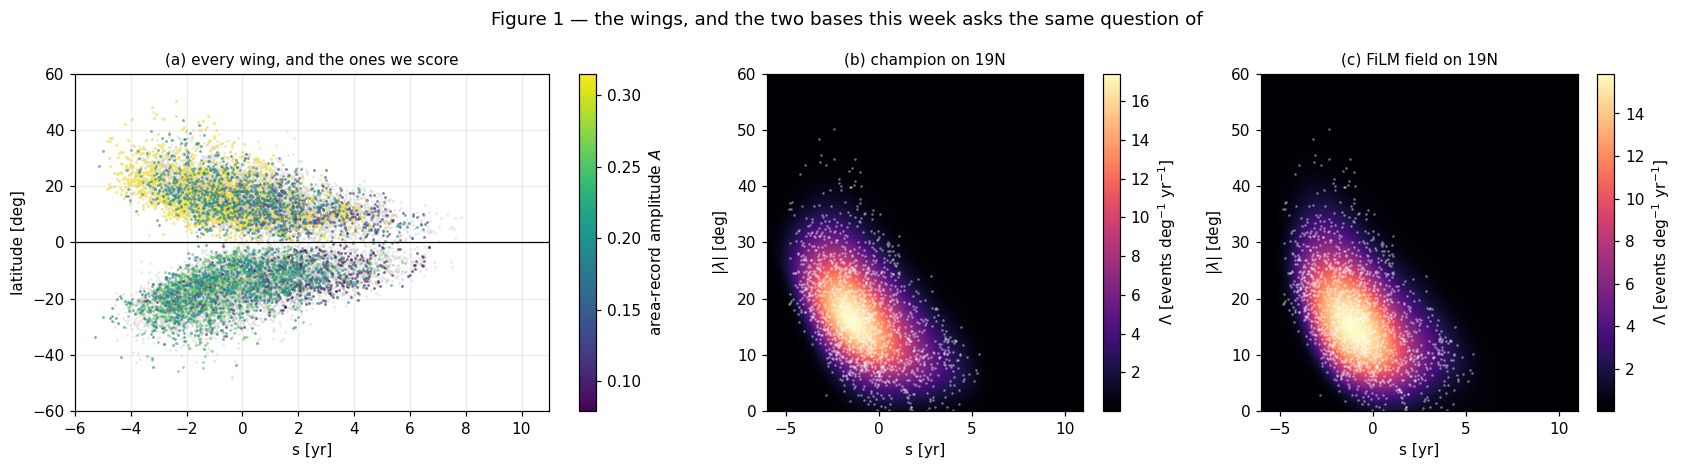

In [111]:
# Given: Figure 1 — the data, and the two bases this week interrogates. Panel (a) is every wing this
# profile fits, with the scored wings in colour; (b) and (c) are the two bases on the same strong wing.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw=dict(width_ratios=[1.5, 1.0, 1.0]))

draw_butterfly(axes[0], {h: EVENTS[h] for h in FIT_WINGS}, "(a) every wing, and the ones we score",
               colour="0.78")
for label in SCORED_WINGS:
    lat, s_here = EVENTS[label]
    sign = 1.0 if label.endswith("N") else -1.0
    axes[0].scatter(s_here, sign * lat, s=3.2, color=amplitude_colour(label), alpha=0.6, linewidths=0)
plt.colorbar(plt.cm.ScalarMappable(norm=AMP_NORM, cmap=AMP_CMAP), ax=axes[0],
             label="area-record amplitude $A$")

for ax, (tag, name, fn) in zip(axes[1:], (("b", "champion", CHAMPION_INTENSITY[STRONGEST]),
                                          ("c", "FiLM field", FILM_INTENSITY[STRONGEST]))):
    drawn = draw_surface(ax, fn, f"({tag}) {name} on {STRONGEST}", events=EVENTS[STRONGEST])
    plt.colorbar(drawn, ax=ax, label=r"$\Lambda$ [events deg$^{-1}$ yr$^{-1}$]")

fig.suptitle("Figure 1 — the wings, and the two bases this week asks the same question of")
plt.tight_layout()
plt.show()

---
## 2 · Two mechanisms, and the instrument both of them need

Every model so far has been a function of *where you are*: `Λ(|λ|, s)`. To let the past matter we need a
**conditional intensity** — the rate at `(|λ|, s)` given everything that has already happened, written
`Λ(|λ|, s | H_s)`, where the **history** `H_s` is the set of events with time strictly less than `s`.

A **Cox process** is the shared-cause story made precise: the rate itself is drawn at random, and events
are Poisson given that rate. A **self-exciting process** is the triggering story: each event raises the
rate nearby for a while. The standard version is the **Hawkes process**, where the raising is additive
and the extra rate decays:

$$ \Lambda(|\lambda|, s \mid H_s) = \Lambda_{\mathrm{base}}(|\lambda|, s) \;+\; \sum_{jk} \beta_{jk}\, h_{jk}(|\lambda|, s), \qquad \beta_{jk} \ge 0 $$

$$ h_{jk}(|\lambda|, s) = \sum_{i\,:\,s_i < s} \exp\!\left(-\frac{s - s_i}{\tau_j}\right)\, \exp\!\left(-\frac{(|\lambda| - |\lambda_i|)^2}{2\ell_k^2}\right) $$

Each `h_jk` is a **triggering kernel** summed over the past: an exponential decay in time with timescale
`τ_j`, a Gaussian in latitude with scale `ℓ_k`. Four timescales by two latitude scales — eight channels,
fixed before anything is fitted. That is **feature engineering**: a designed set of inputs is a
modelling commitment, not a free lunch. Figure 2 draws both mechanisms and the timescale grid.

*Note which way this is additive.* The history is added to the *intensity*, not to the latent field
`B`. Added to `B` it would sit *inside* the emission's `softplus`, where `∫∫ softplus(B + Σβh − 1)`
does not separate into a time integral and a latitude integral — no closed form to have, so it would
go on the frozen mesh, and Figure 2(c) shows that mesh cannot see these kernels. Task 57 measures the
cost: a few percent per channel, worst on the shortest, which is a few tenths of a nat per
hemicycle-year — the size of the effects this week is resolving. Added to the intensity, the integral
is exact.

The honest cost of that, measured in Task 64: with `α = 1` and `B ≈ 10⁴` in the belt core,
`softplus(B − 1) = B − 1`, so the two forms are the *same model* wherever the belt is well above
critical. They differ only where `B < B_crit`, where adding to the field would make a parent nudge a
field that still has to cross threshold instead of supplying the buoyancy itself — the more physical
story. So we print how much of the history term's mass lands down there rather than assuming it is
nothing.

*Two rules about whose events may be summed over, and they are not the same rule.*

- A held-out wing's *own strictly past events are not leakage* — a forecaster standing at time `s` has
  them, and conditioning on them is what a conditional intensity means. That wing's *future* is **data
  leakage**, and so is any other wing's events. Section 6 prices the first one.
- The sum runs over *that wing's own hemisphere*, development wings only. The hemispheres are decoupled
  program-wide; and hemicycle windows span `s ∈ [−6, +11]`, so adjacent cycles overlap in calendar time
  and a 60-day kernel would reach into a withheld cycle unless the sum is restricted.

Two pieces of solar physics make the short channels ambiguous, and the ambiguity travels with every
number we quote. An **active nest** is a patch of the Sun that produces several groups in succession
over days to weeks — the object a triggering model is reaching for. The **solar rotation period** of
about 27 days sets how long a region stays visible, and Figure 2(c) shows it sitting *inside* our grid.
First observation also lags emergence by days, unevenly (median ~65° from central meridian). So a
coefficient at `τ` = 2 days partly measures observing cadence, and one near 27 days partly measures a
region rotating back into view.

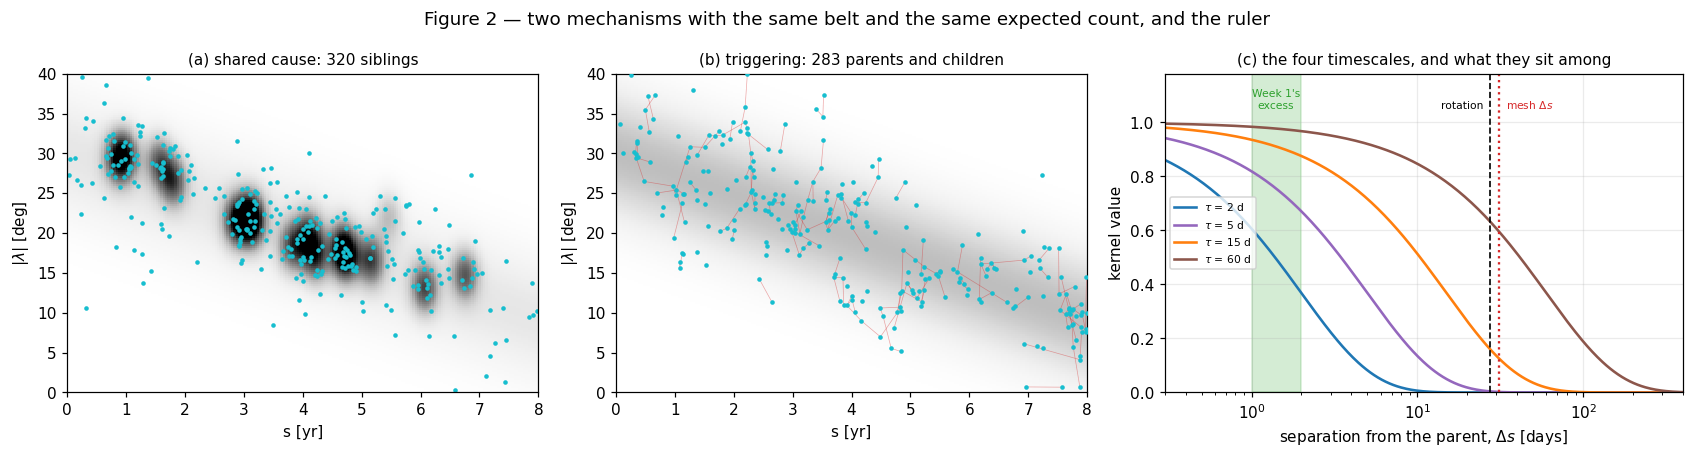

320 events from a bumpy rate against 283 from a smooth one with 0.6 offspring each -- and no count of separations tells them apart.
the sketch's clusters are stretched to 58 days to be visible at all; the real channels are 2-60 days, panel (c).


In [112]:
# Given: Figure 2 — the two mechanisms, drawn before either is fitted. Both panels have the same smooth
# belt and about the same number of events; only the mechanism differs. Panel (b) places children around
# their parents directly — a cluster construction, which is neither Task 56's bank nor Task 61's
# generator, so there is nothing here to copy into either.
SKETCH_MESH = (np.linspace(0.0, 8.0, 201), np.linspace(0.0, 40.0, 161))
SKETCH_N = 320                      # the same expected count in both panels
SKETCH_BRANCH = 0.6                 # offspring per event in panel (b)
SKETCH_SPREAD = (0.16, 2.4)         # the sketch's cluster spread, in (yr, deg) -- stretched, see below


def sketch_belt(abs_lat, s):
    """A toy drifting belt, the backdrop for both mechanisms. Not this program's model."""
    mu = 30.0 - 2.6 * np.asarray(s, dtype=float)
    return np.exp(-(np.asarray(abs_lat, dtype=float) - mu) ** 2 / (2.0 * 5.5 ** 2))


def sketch_patches(rng, n_patch=16):
    """Where the Cox process's rate happens to be high this time. Drawn at random, before any event."""
    patch_s = np.sort(rng.uniform(0.2, 7.8, n_patch))
    return patch_s, 30.0 - 2.6 * patch_s + rng.normal(0.0, 3.2, n_patch)


def sketch_triggered(rng, n_target):
    """Immigrants plus offspring, generation by generation. Terminates because the branching ratio < 1."""
    s_grid, lam_grid = SKETCH_MESH
    belt = sketch_belt(lam_grid[:, None], s_grid[None, :])
    scale = (1.0 - SKETCH_BRANCH) * n_target / integrate_2d(belt, mesh=SKETCH_MESH)
    lat, s, _, _ = simulate_wing(lambda la, ss: scale * sketch_belt(la, ss),
                                 scale * belt.max() * 1.05, rng, mesh=SKETCH_MESH)
    links, generation = [], (lat, s)
    while len(generation[0]):
        parent_lat, parent_s = generation
        births = rng.poisson(SKETCH_BRANCH, size=len(parent_s))
        who = np.repeat(np.arange(len(parent_s)), births)
        child_s = parent_s[who] + rng.exponential(SKETCH_SPREAD[0], size=len(who))
        child_lat = parent_lat[who] + rng.normal(0.0, SKETCH_SPREAD[1], size=len(who))
        inside = (child_s < s_grid[-1]) & (child_lat > lam_grid[0]) & (child_lat < lam_grid[-1])
        links += [((parent_s[i], child_s[k]), (parent_lat[i], child_lat[k]))
                  for k, i in enumerate(who) if inside[k]]
        generation = (child_lat[inside], child_s[inside])
        lat, s = np.concatenate([lat, generation[0]]), np.concatenate([s, generation[1]])
    return lat, s, links


SKETCH_RNG = np.random.default_rng(SEED + 6)
S_SKETCH, LAM_SKETCH = SKETCH_MESH
PATCH_S, PATCH_LAT = sketch_patches(SKETCH_RNG)


def sketch_shared(abs_lat, s):
    """The shared cause: the belt times patches that landed at random. The RATE is bumpy, nothing more."""
    bumps = sum(np.exp(-((s - s0) ** 2 / (2.0 * SKETCH_SPREAD[0] ** 2)
                         + (abs_lat - lat0) ** 2 / (2.0 * SKETCH_SPREAD[1] ** 2)))
                for s0, lat0 in zip(PATCH_S, PATCH_LAT))
    return SKETCH_SCALE * sketch_belt(abs_lat, s) * (1.0 + 3.5 * bumps)


SKETCH_SCALE = 1.0
SKETCH_SCALE = SKETCH_N / integrate_2d(sketch_shared(LAM_SKETCH[:, None], S_SKETCH[None, :]),
                                       mesh=SKETCH_MESH)
SHARED_RATE = sketch_shared(LAM_SKETCH[:, None], S_SKETCH[None, :])
SHARED_LAT, SHARED_S, _, _ = simulate_wing(sketch_shared, SHARED_RATE.max() * 1.05, SKETCH_RNG,
                                           mesh=SKETCH_MESH)
TRIG_LAT, TRIG_S, TRIG_LINKS = sketch_triggered(SKETCH_RNG, SKETCH_N)
SKETCH_BELT = SKETCH_N * sketch_belt(LAM_SKETCH[:, None], S_SKETCH[None, :]) \
    / integrate_2d(sketch_belt(LAM_SKETCH[:, None], S_SKETCH[None, :]), mesh=SKETCH_MESH)
SKETCH_VMAX = 0.62 * SHARED_RATE.max()

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2), gridspec_kw=dict(width_ratios=[1.0, 1.0, 1.1]))

axes[0].pcolormesh(S_SKETCH, LAM_SKETCH, SHARED_RATE, cmap="Greys", shading="auto",
                   vmin=0.0, vmax=SKETCH_VMAX)
axes[0].scatter(SHARED_S, SHARED_LAT, s=9, c="tab:cyan", linewidths=0)
axes[0].set_title(f"(a) shared cause: {len(SHARED_S)} siblings", fontsize=10)

axes[1].pcolormesh(S_SKETCH, LAM_SKETCH, SKETCH_BELT, cmap="Greys", shading="auto",
                   vmin=0.0, vmax=SKETCH_VMAX)
for xs, ys in TRIG_LINKS:
    axes[1].plot(xs, ys, lw=0.45, color="tab:red", alpha=0.40, zorder=2)
axes[1].scatter(TRIG_S, TRIG_LAT, s=9, c="tab:cyan", linewidths=0, zorder=3)
axes[1].set_title(f"(b) triggering: {len(TRIG_S)} parents and children", fontsize=10)

for ax in axes[:2]:
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_xlim(S_SKETCH[0], S_SKETCH[-1])
    ax.set_ylim(LAM_SKETCH[0], LAM_SKETCH[-1])
    ax.grid(False)

MESH_DS_DAYS = (S_B - S_A) / (N_S_2D - 1) * 365.25
GAP_DAYS = np.logspace(np.log10(0.3), np.log10(400.0), 400)
axes[2].axvspan(1.0, 2.0, color="tab:green", alpha=0.20)
axes[2].text(1.4, 1.05, "Week 1's\nexcess", fontsize=7, color="tab:green", ha="center")
for tau, colour in zip(TAU_DAYS, ("tab:blue", "tab:purple", "tab:orange", "tab:brown")):
    axes[2].plot(GAP_DAYS, np.exp(-GAP_DAYS / tau), lw=1.7, color=colour, label=rf"$\tau$ = {tau:.0f} d")
axes[2].axvline(27.2753, color="k", ls="--", lw=1.1)
axes[2].text(27.2753 * 0.92, 1.05, "rotation", fontsize=7, ha="right")
axes[2].axvline(MESH_DS_DAYS, color="tab:red", ls=":", lw=1.5)
axes[2].text(MESH_DS_DAYS * 1.1, 1.05, rf"mesh $\Delta s$", fontsize=7, color="tab:red")
axes[2].set_xscale("log")
axes[2].set_xlim(GAP_DAYS[0], GAP_DAYS[-1])
axes[2].set_ylim(0.0, 1.18)
axes[2].set_xlabel(r"separation from the parent, $\Delta s$ [days]")
axes[2].set_ylabel("kernel value")
axes[2].set_title("(c) the four timescales, and what they sit among", fontsize=10)
axes[2].legend(fontsize=7, loc="center left")

fig.suptitle("Figure 2 — two mechanisms with the same belt and the same expected count, and the ruler")
plt.tight_layout()
plt.show()

print(f"{len(SHARED_S)} events from a bumpy rate against {len(TRIG_S)} from a smooth one with "
      f"{SKETCH_BRANCH} offspring each -- and no count of separations tells them apart.")
print(f"the sketch's clusters are stretched to {SKETCH_SPREAD[0] * 365.25:.0f} days to be visible at "
      f"all; the real channels are {TAU_DAYS[0]:.0f}-{TAU_DAYS[-1]:.0f} days, panel (c).")

In [113]:
### TASK 56: The history bank — eight strictly-past channels, and the field they make
### BEGIN SOLUTION
NU_START = 0.01                    # where every history fit starts: a hundredth of an offspring per event


def history_bank(event_lat, event_s, strictly_past=True, channels=ALL_CHANNELS):
    """Every channel's value at every event of one wing, from that wing's own earlier events.

    Returns `H` with shape (n_events, 8):

        H[i, m] = sum over j with s_j < s_i of exp(-(s_i - s_j)/tau_m) * exp(-(lat_i - lat_j)^2/2 ell_m^2)

    Events must already be sorted in `event_s`. Channels outside `channels` are left at zero, which is
    how the `nohist` and `short` arms are the same code as the full bank.
    """
    lat = np.asarray(event_lat, dtype=float)
    s = np.asarray(event_s, dtype=float)
    H = np.zeros((len(s), N_CHANNELS))
    if len(s) == 0 or not len(channels):
        return H
    ds = s[:, None] - s[None, :]           # row i, column j: how long after event j event i arrived
    dl = lat[:, None] - lat[None, :]
    # Strictly past. A tie is NOT its own parent and not each other's: 16.4% of this catalog's gaps are
    # exactly zero, so `>` against `>=` is the difference Section 6 measures.
    past = ds > 0.0 if strictly_past else ds >= 0.0
    for m in channels:
        j, k = CHANNELS[m]
        # the absolute value keeps exp() from overflowing on the future half, which is masked away anyway
        decay = np.where(past, np.exp(-np.abs(ds) / TAUS[j]), 0.0)
        H[:, m] = (decay * np.exp(-dl ** 2 / (2.0 * ELLS[k] ** 2))).sum(axis=1)
    return H


def history_field(abs_lat, s, lat_par, s_par, beta, block=256):
    """The same sum at *any* (|lat|, s): `sum_jk beta_jk h_jk`, in events per degree per year.

    This is the one function that evaluates the history term off the events, and it takes no mesh: the
    likelihood's history integral is closed form, so this is only ever used for figures, for the time
    marginal and for the thinning majorant.
    """
    abs_lat, s = np.broadcast_arrays(np.asarray(abs_lat, dtype=float), np.asarray(s, dtype=float))
    beta = np.asarray(beta, dtype=float)
    out = np.zeros(abs_lat.shape)
    for m in np.flatnonzero(beta):
        j, k = CHANNELS[int(m)]
        for lo in range(0, len(s_par), block):   # blocked over parents, or one wing eats the memory
            sp, lp = np.asarray(s_par)[lo:lo + block], np.asarray(lat_par)[lo:lo + block]
            ds = s[..., None] - sp
            dl = abs_lat[..., None] - lp
            kernel = np.where(ds > 0.0, np.exp(-np.abs(ds) / TAUS[j]), 0.0) \
                * np.exp(-dl ** 2 / (2.0 * ELLS[k] ** 2))
            out += beta[int(m)] * kernel.sum(axis=-1)
    return out


def draw_history(ax, field, title, events=None, grid=H_MESH, cmap="inferno"):
    """The extra rate the past has left behind, over one wing, with the events that left it on top."""
    s_grid, lam_grid = grid
    drawn = ax.pcolormesh(s_grid, lam_grid, field, cmap=cmap, shading="auto")
    if events is not None:
        ax.scatter(events[1], events[0], s=2.6, c="cyan", alpha=0.5, linewidths=0)
    ax.set_xlim(s_grid[0], s_grid[-1])
    ax.set_ylim(lam_grid[0], lam_grid[-1])
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_title(title, fontsize=10)
    ax.grid(False)
    return drawn
### END SOLUTION
# Reference workflow:
#   1. `history_bank`: sort nothing (the caller already did), build the all-pairs time difference
#      `s_i - s_j` and latitude difference, and mask to the strictly past half. For each channel in
#      `channels`, multiply the exponential time decay by the Gaussian latitude factor and sum over `j`.
#      Keep every channel's column in place, so a four-channel arm and an eight-channel arm return the
#      same shape.
#   2. Guard the exponential: computing `exp(-ds/tau)` on the *future* half gives a huge positive
#      exponent and an overflow warning before the mask throws it away. Take the absolute value first.
#   3. `history_field`: the same sum, but evaluated at arbitrary points rather than at the events, with
#      `beta` already folded in so one pass returns the whole history term. Skip channels whose `beta` is
#      zero, and loop over the parents in blocks — a full mesh times 1,590 parents is a large array.
#   4. `draw_history`: one `pcolormesh` of the field over `grid`, the events scattered on top in a colour
#      that survives a dark colour map, labelled axes, and `return` the mappable so the given cell can
#      put a colour bar on it. No `plt.show()` — this is a primitive, and the next cell composes it.

In [114]:
# Put your code for Task 56 here

history field over 19N (1,590 parents) in 3.2 s


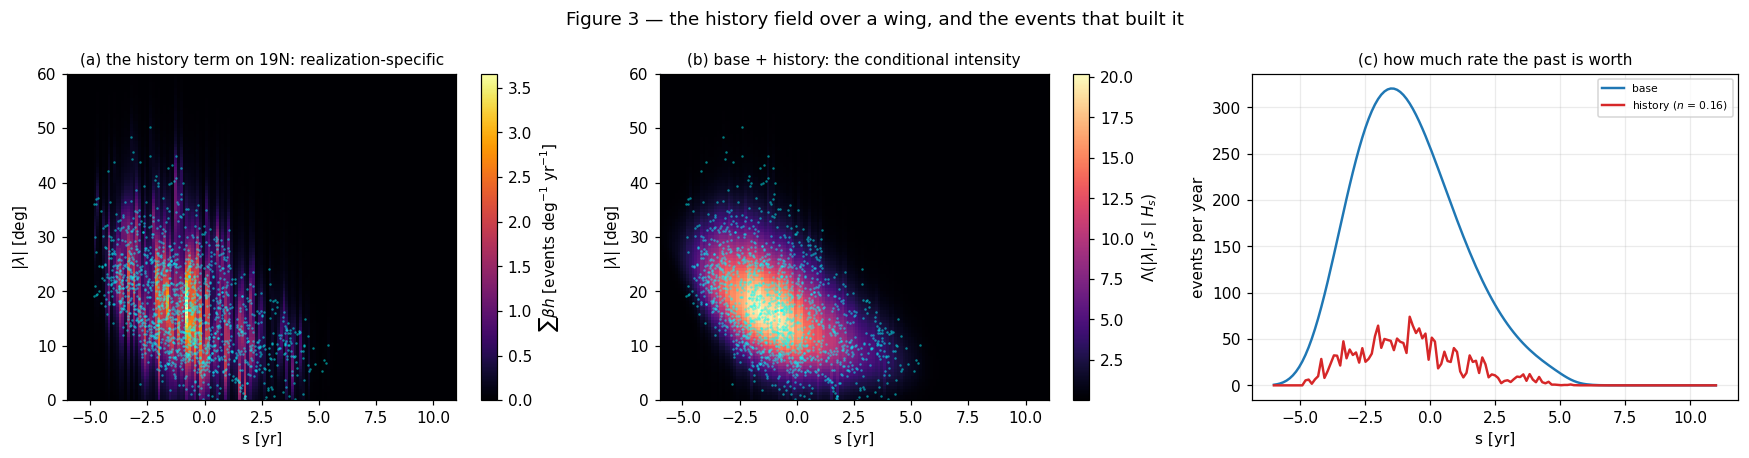

In [115]:
# Given: Figure 3 — the instrument, before anything is fitted. The coefficients are *prescribed*, not
# measured: 0.02 offspring per channel, so n = 0.16 and the structure is visible.
DEMO_NU = np.full(N_CHANNELS, 0.02)
DEMO_BETA = DEMO_NU / CHANNEL_MASS
demo_lat, demo_s = EVENTS[STRONGEST]
H_S, H_LAM = H_MESH

started = time.time()
H_FIELD = history_field(H_LAM[:, None], H_S[None, :], demo_lat, demo_s, DEMO_BETA)
BASE_ON_H = np.asarray(CHAMPION_INTENSITY[STRONGEST](H_LAM[:, None], H_S[None, :]), dtype=float)
print(f"history field over {STRONGEST} ({len(demo_s):,} parents) in {time.time() - started:.1f} s")

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.2))
drawn = draw_history(axes[0], H_FIELD, f"(a) the history term on {STRONGEST}: realization-specific",
                     events=EVENTS[STRONGEST])
plt.colorbar(drawn, ax=axes[0], label=r"$\sum\beta h$ [events deg$^{-1}$ yr$^{-1}$]")

drawn = draw_history(axes[1], BASE_ON_H + H_FIELD, "(b) base + history: the conditional intensity",
                     events=EVENTS[STRONGEST], cmap="magma")
plt.colorbar(drawn, ax=axes[1], label=r"$\Lambda(|\lambda|, s \mid H_s)$")

axes[2].plot(H_S, trapezoid(BASE_ON_H, H_LAM, axis=0), lw=1.6, color="tab:blue", label="base")
axes[2].plot(H_S, trapezoid(H_FIELD, H_LAM, axis=0), lw=1.6, color="tab:red",
             label=f"history ($n$ = {DEMO_NU.sum():.2f})")
axes[2].set_xlabel("s [yr]")
axes[2].set_ylabel("events per year")
axes[2].set_title("(c) how much rate the past is worth", fontsize=10)
axes[2].legend(fontsize=7)

fig.suptitle("Figure 3 — the history field over a wing, and the events that built it")
plt.tight_layout()
plt.show()

# Panel (a) is not smooth, and two wings of equal amplitude do not share it: a history term is
# realization-specific, which is the whole difference from a base model. Said on the figure, not here.

### The integral term, and why it has to be exact

The likelihood has two pieces: a sum over events and `∫∫ Λ dλ ds` over the window. The base's integral
is the trapezoid on the frozen mesh, as in every week since Week 3. The history term's integral we do
*in closed form*, because it factorizes — an exponential in `s` times a Gaussian in `λ`:

$$ \iint \sum_{jk}\beta_{jk} h_{jk}\,\mathrm{d}\lambda\,\mathrm{d}s \;=\; \sum_{jk}\beta_{jk}\sum_i \underbrace{\tau_j\left(1 - e^{-(S_B - s_i)/\tau_j}\right)}_{\text{time, truncated at the window's end}} \cdot \underbrace{\ell_k\sqrt{\tfrac{\pi}{2}}\left[\mathrm{erf}\!\left(\tfrac{\Lambda_{\max} - \lambda_i}{\ell_k\sqrt{2}}\right) + \mathrm{erf}\!\left(\tfrac{\lambda_i}{\ell_k\sqrt{2}}\right)\right]}_{\text{latitude, truncated at } [0^\circ,\,60^\circ]} $$

The `erf` pair is *not a refinement*. Our latitude domain stops at the equator and so does the integral:
a kernel centred on an event at 0° has exactly *half* its mass outside the domain, and at `ℓ` = 10° an
event at 3° keeps only 62% of it. Replace the bracket with the full `√(2π)` and the compensator is
silently inflated, which makes every history model look worse than it is. Unlike the mesh error, this
one does not cancel across parents — it is a one-sided loss at both edges.

This is also where `β` becomes interpretable. One channel's whole untruncated mass is `τ_j ℓ_k √(2π)`,
so `β_jk τ_j ℓ_k √(2π)` is the expected number of offspring that channel contributes per event, and the
sum over channels is the **branching ratio** `n`. A self-exciting process is stable only when `n < 1`;
at `n ≥ 1` each generation is at least as large as the last and the process explodes. We therefore fit
in offspring units: the optimizer sees `ν_jk` ≥ 0 with `n = Σ ν_jk`, and `β = ν / (τ ℓ √(2π))`.

*And we bound `n` below 1 in the fit itself*, because `n ≥ 1` is outside the family. Two conditions
turn out to be one: a channel's whole mass is at most `τ ℓ √(2π)` per event, so the history term's
compensator is at most `n` × (number of events) — and `n < 1` is *exactly* what leaves Task 58's
count-matching identity a positive `c`. Lift the bound and the fit finds `n` just above 1, hands the
whole observed count to the history term, drives `c` to zero, and *improves* the held-out score while
the base quietly vanishes. That is what the first version of this notebook did.

In [116]:
### TASK 57: The compensator in closed form, and what the frozen mesh would have said
### BEGIN SOLUTION
def latitude_mass(event_lat, ell):
    """One latitude kernel integrated over |lat| in [0, LAM_MAX], exactly, for every event.

    The two erf terms are the truncation at the poleward edge and at the equator. Dropping them and
    using ell*sqrt(2*pi) overstates the mass by up to a factor of two near the equator.
    """
    lat = np.asarray(event_lat, dtype=float)
    root2 = np.sqrt(2.0)
    return ell * np.sqrt(0.5 * np.pi) * (erf((LAM_MAX - lat) / (ell * root2))
                                         + erf(lat / (ell * root2)))


def history_compensator(event_lat, event_s, s_hi=S_B, channels=ALL_CHANNELS):
    """A[m] = the double integral of channel m over the window, in closed form. Shape (8,).

    Returned per channel and NOT multiplied by beta, so the fitter can profile `c` against any beta
    without recomputing anything.
    """
    lat = np.asarray(event_lat, dtype=float)
    s = np.asarray(event_s, dtype=float)
    A = np.zeros(N_CHANNELS)
    for m in channels:
        j, k = CHANNELS[m]
        in_time = TAUS[j] * (1.0 - np.exp(-(s_hi - s) / TAUS[j]))
        A[m] = float(np.sum(in_time * latitude_mass(lat, ELLS[k])))
    return A


def branching_ratio(nu):
    """Expected offspring per event. The stability condition is n < 1 and we assert it before simulating."""
    return float(np.sum(np.asarray(nu, dtype=float)))


def draw_mass_error(ax, exact, on_mesh):
    """What the frozen quadrature mesh would have made of each channel's integral."""
    position = np.arange(N_CHANNELS)
    ax.axhline(1.0, color="k", lw=1.0)
    ax.bar(position, on_mesh / exact, color=["tab:red" if abs(r - 1.0) > 0.05 else "tab:blue"
                                             for r in on_mesh / exact])
    ax.set_xticks(position)
    ax.set_xticklabels(CHANNEL_NAMES, rotation=90, fontsize=7)
    ax.set_ylabel("mesh quadrature / exact")
    ax.set_title(r"(a) the frozen mesh on a 31-day grid", fontsize=10)
### END SOLUTION
# Reference workflow:
#   1. `latitude_mass`: the Gaussian integral between 0 and `LAM_MAX`, written with the two `erf` terms
#      so that an event near either edge loses the mass that falls outside the domain. `erf` is already
#      imported from `scipy.special`.
#   2. `history_compensator`: for each requested channel, multiply the per-event time factor
#      `tau*(1 - exp(-(S_B - s_i)/tau))` by that event's latitude mass and sum over events. Return one
#      number per channel, un-weighted by beta.
#   3. `branching_ratio`: with the fit parameterized in offspring units this is just the sum. Write it
#      anyway — it is the function the simulator asserts on.
#   4. `draw_mass_error`: a bar per channel of (mesh quadrature / exact), a line at 1, and the channel
#      names on the x axis. Colour the bars that are more than 5% off, so the eye goes to them.

In [117]:
# Put your code for Task 57 here

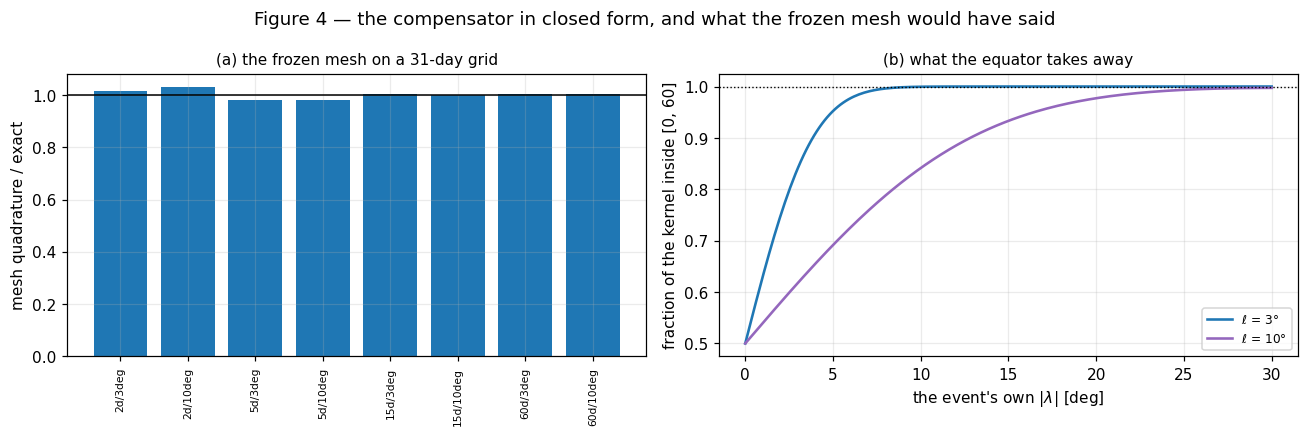

mesh quadrature / exact, per channel: [1.016 1.030 0.980 0.982 1.003 1.002 1.003 1.002]
worst channel: 2d/10deg at 1.030 of the exact value
on 19N's 1,590 events at n = 0.16, that error is about 0.5 events of compensator, or 0.030 nats per hemicycle-year
latitude is fine (3 and 10 deg are 12 and 40 mesh cells); it is the time direction that fails, worst on the channel the week turns on. Hence the closed form.


In [118]:
# Given: Figure 4 — the measurement behind the design. Panel (a) integrates each channel on the frozen
# 201 x 241 mesh and divides by the exact value, on a 150-event subsample. Panel (b) is the latitude
# truncation the erf pair handles.
sub = np.random.default_rng(SEED).choice(len(demo_s), size=min(150, len(demo_s)), replace=False)
sub_lat, sub_s = demo_lat[sub], demo_s[sub]
order = np.argsort(sub_s)
sub_lat, sub_s = sub_lat[order], sub_s[order]

EXACT_A = history_compensator(sub_lat, sub_s)
MESH_A = np.zeros(N_CHANNELS)
for m in range(N_CHANNELS):
    unit = np.zeros(N_CHANNELS)
    unit[m] = 1.0
    MESH_A[m] = integrate_2d(history_field(LAM_2D[:, None], S_2D[None, :], sub_lat, sub_s, unit))

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.0))
draw_mass_error(axes[0], EXACT_A, MESH_A)

lat_grid = np.linspace(0.0, 30.0, 200)
for ell, colour in zip(ELL_DEG, ("tab:blue", "tab:purple")):
    axes[1].plot(lat_grid, latitude_mass(lat_grid, ell) / (ell * np.sqrt(2.0 * np.pi)), lw=1.7,
                 color=colour, label=rf"$\ell$ = {ell:.0f}$\degree$")
axes[1].axhline(1.0, color="k", lw=0.9, ls=":")
axes[1].set_xlabel(r"the event's own $|\lambda|$ [deg]")
axes[1].set_ylabel("fraction of the kernel inside [0, 60]")
axes[1].set_title("(b) what the equator takes away", fontsize=10)
axes[1].legend(fontsize=8)

fig.suptitle("Figure 4 — the compensator in closed form, and what the frozen mesh would have said")
plt.tight_layout()
plt.show()

ratio = MESH_A / EXACT_A
worst = int(np.argmax(np.abs(ratio - 1.0)))
print(f"mesh quadrature / exact, per channel: "
      f"{np.array2string(ratio, precision=3, floatmode='fixed')}")
print(f"worst channel: {CHANNEL_NAMES[worst]} at {ratio[worst]:.3f} of the exact value")

# What a few percent is worth in the units the week scores in. Not order-unity -- errors from scattered
# parents partly cancel -- but the size of the effects we are resolving, and worst on the one channel
# Week 1 found anything in.
demo_cost = abs(float((MESH_A - EXACT_A) @ (DEMO_NU / CHANNEL_MASS))) * (len(demo_s) / len(sub_s))
print(f"on {STRONGEST}'s {len(demo_s):,} events at n = {DEMO_NU.sum():.2f}, that error is about "
      f"{demo_cost:.1f} events of compensator, or {demo_cost / WINDOW_YEARS:.3f} nats per hemicycle-year")
print(f"latitude is fine ({ELL_DEG[0]:.0f} and {ELL_DEG[1]:.0f} deg are 12 and 40 mesh cells); it is "
      f"the time direction that fails, worst on the channel the week turns on. Hence the closed form.")

In [119]:
# Given: the bookkeeping that keeps one wing's events, its H rows and its base values in one order.
# `s_true` is the *unreflected* time and is where the base is always evaluated. That matters in Section 3:
# reflecting the data and the base together leaves the base's contribution to the likelihood bit-for-bit
# identical, which is what makes the asymmetry statistic a measurement of the history term alone.
def history_of(events, labels, strictly_past=True, reflected=False, channels=ALL_CHANNELS):
    """Each wing's bank: its events sorted in the direction being read, its H matrix and its A vector."""
    bank = {}
    for label in labels:
        lat0 = np.asarray(events[label][0], dtype=float)
        s0 = np.asarray(events[label][1], dtype=float)
        s_use = (S_A + S_B - s0) if reflected else s0
        order = np.argsort(s_use, kind="stable")
        lat, s_read, s_true = lat0[order], s_use[order], s0[order]
        bank[label] = dict(label=label, lat=lat, s=s_read, s_true=s_true, reflected=bool(reflected),
                           H=history_bank(lat, s_read, strictly_past, channels),
                           A=history_compensator(lat, s_read, channels=channels))
    return bank


def log_likelihood_history(bank_wing, intensity_fn, beta, mesh=MESH_2D):
    """One wing's log L with an additive history term. The base uses the mesh; the history never does."""
    at = np.asarray(intensity_fn(bank_wing["lat"], bank_wing["s_true"]), dtype=float)
    at = at + bank_wing["H"] @ np.asarray(beta, dtype=float)
    if not np.all(np.isfinite(at)) or np.any(at <= 0.0):
        return -np.inf
    base_integral = integrate_2d(intensity_fn(mesh[1][:, None], mesh[0][None, :]), mesh)
    total = float(np.sum(np.log(at)) - base_integral - float(bank_wing["A"] @ np.asarray(beta, float)))
    return total if np.isfinite(total) else -np.inf


def with_history(intensity_fn, lat_par, s_par, beta):
    """Base + history as one `intensity_fn(abs_lat, s)`.

    For figures, for the time marginal and for the thinning majorant. NEVER for the likelihood's integral
    term: integrating this on the frozen mesh is precisely the error Figure 4 measures.
    """
    def combined(abs_lat, s):
        return (np.asarray(intensity_fn(abs_lat, s), dtype=float)
                + history_field(abs_lat, s, lat_par, s_par, beta))
    return combined


print("bank bookkeeping · history likelihood · the wrapper for everything that is not the likelihood")

bank bookkeeping · history likelihood · the wrapper for everything that is not the likelihood


In [120]:
### TASK 58: Fit the eight coefficients, and the count-matching identity they change
### BEGIN SOLUTION
def beta_of(nu):
    """Offspring units to intensity units. The optimizer sees `nu`; the likelihood needs `beta`."""
    return np.asarray(nu, dtype=float) / CHANNEL_MASS


def solve_c_history(n_total, unit_integral, a_total):
    """`c` is no longer n / int-int-Lambda_1.

    The history term already supplies `a_total` of the expected count, so `c` may only take what is
    left: c = (n - A.beta) / int-int-Lambda_1. Leave this at Week 4's version and the fitted model stops
    reproducing the pooled count, with `c` quietly absorbing the history mass and no error anywhere.
    """
    remaining = n_total - a_total
    if not (remaining > 0.0 and unit_integral > 0.0):
        return np.nan
    return remaining / unit_integral


def nu_from_z(z, free, cap=N_CAP):
    """Non-negative coefficients whose total stays strictly below `cap`.

    `cap * exp(z) / (1 + sum(exp(z)))` is a softmax with one spare slot: every channel is non-negative,
    the branching ratio approaches `cap` without reaching it, and sending every z to minus infinity
    gives exactly nu = 0. That keeps the fit inside the model family — see `N_CAP` above for why n < 1
    is both the stability condition and what makes `c` positive.
    """
    nu = np.zeros(N_CHANNELS)
    if not len(free):
        return nu
    weights = np.exp(np.clip(np.asarray(z, dtype=float), -60.0, 60.0))
    nu[free] = cap * weights / (1.0 + weights.sum())
    return nu


def z_from_nu(nu, free, cap=N_CAP):
    """The inverse, for a warm start. Not unique in general; this is the branch the fit uses."""
    nu = np.maximum(np.asarray(nu, dtype=float)[free], NU_START * 1.0e-3)
    share = np.clip(nu.sum() / cap, 1.0e-9, 1.0 - 1.0e-9)
    return np.log(nu / cap) + np.log(1.0 / (1.0 - share))


def fit_nu(unit_at, unit_int, H, A, n_total, nu_start=None, nu_max=None, channels=ALL_CHANNELS):
    """The history block: eight coefficients, with `c` profiled out by count matching at every step.

    `unit_at` is the base intensity at every event with c = 1, stacked over wings in bank order;
    `unit_int` is the sum of the base mesh integrals at c = 1; `H` and `A` are stacked and summed the
    same way. Because count matching forces c*unit_int + A.beta = n_total exactly, the integral term is
    the constant n_total and the objective is the event sum alone — so this block never touches a mesh.
    """
    free = list(channels)
    if not free:
        return np.zeros(N_CHANNELS), None
    cap = N_CAP if nu_max is None else nu_max
    start = (np.full(N_CHANNELS, NU_START) if nu_start is None
             else np.maximum(np.asarray(nu_start, dtype=float), NU_START))

    def unpack(z):
        return nu_from_z(z, free, cap)

    def objective(z):
        nu = unpack(z)
        beta = beta_of(nu)
        c = solve_c_history(n_total, unit_int, float(A @ beta))
        if not np.isfinite(c) or c <= 0.0:
            return 1.0e12
        at = c * unit_at + H @ beta
        if not np.all(np.isfinite(at)) or np.any(at <= 0.0):
            return 1.0e12
        return -(float(np.sum(np.log(at))) - n_total)

    out = minimize(objective, z_from_nu(start, free, cap), method="L-BFGS-B",
                   options=dict(maxiter=400))
    return unpack(out.x), out
### END SOLUTION
# Reference workflow:
#   1. `beta_of` is one division by `CHANNEL_MASS`, which Section 2's markdown defines. Fitting in
#      offspring units is what makes the branching ratio the sum of the fitted vector.
#   2. `solve_c_history` is the week's highest-probability silent bug. Subtract the history compensator
#      from the observed count *before* dividing, and return something non-finite rather than a negative
#      `c` when the history term would already over-supply the count.
#   3. `nu_from_z`: parameterize the free channels so each `nu` is non-negative *and* their total cannot
#      reach `cap` — a softmax with one spare slot does both. Work out why bounding the total is not a
#      convenience: without it the fit sets the branching ratio just above 1, hands the whole observed
#      count to the history term, drives `c` to zero, and the held-out score goes *up* while the base
#      model quietly disappears.
#   4. `fit_nu`: channels outside `channels` stay at exactly zero, which is how one function serves the
#      no-history arm, the short arm and the full bank.
#   5. The objective: re-solve `c` for the candidate `nu`, add `H @ beta` to `c * unit_at`, return the
#      negative event sum, and hand it to `L-BFGS-B` (returning `nu`, not `z`). Work out why `n_total`
#      is the whole integral term here — it is why this block costs almost nothing per iteration, and
#      why the week fits inside its budget.

In [121]:
# Put your code for Task 58 here

In [122]:
# Given: the parametric arm's fit. This is Week 4's `fit_pooled_v2` with one more block in the same
# block-coordinate sweep — history, then the shared block, then each wing's own amplitude, then `c` —
# and `c` re-solved with Task 58's corrected identity every time anything moves. `Model` is untouched:
# beta is not a stage, which is exactly why Task 59 has to put the arm in the cache key by hand.
def fit_pooled_history(events, labels, model, bank, q_start=None, amp_start=None, wing_start=None,
                       sweeps=3, channels=ALL_CHANNELS, nu_start=None, nu_max=None, mesh=MESH_2D):
    """Fit the base and the eight history coefficients jointly. Returns the fit, including `nu`."""
    labels = list(labels)
    n_total = sum(len(bank[h]["s"]) for h in labels)
    q = model.start_q() if q_start is None else np.array(q_start, dtype=float)
    amps = {h: 2.0e4 for h in labels} if amp_start is None else {h: float(amp_start[h]) for h in labels}
    wing = ({h: model.start_wing() for h in labels} if wing_start is None
            else {h: np.array(wing_start[h], dtype=float) for h in labels})
    nu = np.zeros(N_CHANNELS) if nu_start is None else np.array(nu_start, dtype=float)
    lam_col, s_row = mesh[1][:, None], mesh[0][None, :]
    H_all = np.concatenate([bank[h]["H"] for h in labels]) if labels else np.zeros((0, N_CHANNELS))
    A_all = np.sum([bank[h]["A"] for h in labels], axis=0)

    def geometric_mean(values):
        return float(np.exp(np.mean(np.log(list(values)))))

    def unit_pieces(a_ref):
        """The base at c = 1: its values at every event, stacked in bank order, and its mesh integral."""
        unit = model.unpack(q, 1.0, a_ref)
        at, integral = [], 0.0
        for h in labels:
            fn = model.intensity(h, amps[h], unit, wing[h])
            at.append(np.asarray(fn(bank[h]["lat"], bank[h]["s_true"]), dtype=float))
            integral += integrate_2d(fn(lam_col, s_row), mesh)
        return np.concatenate(at) if at else np.zeros(0), float(integral)

    def shape_nll(q_try, c, a_ref, beta):
        shared = model.unpack(q_try, c, a_ref)
        total = 0.0
        for h in labels:
            value = log_likelihood_history(bank[h], model.intensity(h, amps[h], shared, wing[h]),
                                           beta, mesh)
            if not np.isfinite(value):
                return 1.0e12
            total += value
        return -total

    def wing_nll(h, shared, beta):
        def nll(vector):
            fn = model.intensity(h, float(np.exp(vector[0])), shared, vector[1:])
            value = log_likelihood_history(bank[h], fn, beta, mesh)
            return -value if np.isfinite(value) else 1.0e12
        return nll

    a_ref = geometric_mean(amps.values())
    beta, c = beta_of(nu), np.nan
    for _ in range(sweeps):
        unit_at, unit_int = unit_pieces(a_ref)
        nu, _ = fit_nu(unit_at, unit_int, H_all, A_all, n_total, nu_start=nu, nu_max=nu_max,
                       channels=channels)
        beta = beta_of(nu)
        c = solve_c_history(n_total, unit_int, float(A_all @ beta))
        q = minimize(shape_nll, q, args=(c, a_ref, beta), method="L-BFGS-B",
                     options=dict(maxiter=300)).x
        shared = model.unpack(q, c, a_ref)
        for h in labels:
            if model.wing_idx:
                out = minimize(wing_nll(h, shared, beta),
                               np.concatenate([[np.log(amps[h])], wing[h]]), method="Nelder-Mead",
                               options=dict(maxiter=250, maxfev=250, xatol=1e-4, fatol=1e-4))
                amps[h], wing[h] = float(np.exp(out.x[0])), out.x[1:]
            else:
                out = minimize_scalar(lambda z: wing_nll(h, shared, beta)(np.array([z])),
                                      bounds=AMPLITUDE_BRACKET, method="bounded",
                                      options=dict(xatol=1e-4))
                amps[h] = float(np.exp(out.x))
        a_ref = geometric_mean(amps.values())
        unit_at, unit_int = unit_pieces(a_ref)
        c = solve_c_history(n_total, unit_int, float(A_all @ beta))
    return dict(q=q, shared=model.unpack(q, c, a_ref), amplitudes=amps, wing=wing, labels=labels,
                nu=nu, beta=beta, a_ref=a_ref, c=float(c),
                nll=shape_nll(q, c, a_ref, beta), n_total=n_total)


def fit_nu_only(bank, labels, intensity_of, channels=ALL_CHANNELS, nu_max=None, nu_start=None):
    """Fit the eight coefficients with the base and `c` held exactly as they are.

    Used in two places and nowhere else: Section 3's asymmetry statistic, where the base *cancels*
    between the two directions, and Section 6's leaky refit, where a joint fit would spend three minutes
    letting a runaway coefficient drag the base behind it. Here `c` is fixed, so the integral term does
    not collapse and `A @ beta` stays in the objective.
    """
    free = list(channels)
    if not free:
        return np.zeros(N_CHANNELS), 0.0
    at = np.concatenate([np.asarray(intensity_of(h)(bank[h]["lat"], bank[h]["s_true"]), dtype=float)
                         for h in labels])
    H_all = np.concatenate([bank[h]["H"] for h in labels])
    A_all = np.sum([bank[h]["A"] for h in labels], axis=0)
    base_sum = float(np.sum(np.log(at)))
    cap = N_CAP if nu_max is None else nu_max
    start = (np.full(N_CHANNELS, NU_START) if nu_start is None
             else np.maximum(np.asarray(nu_start, dtype=float), NU_START))

    def unpack(z):
        return nu_from_z(z, free, cap)

    def objective(z):
        beta = beta_of(unpack(z))
        values = at + H_all @ beta
        if not np.all(np.isfinite(values)) or np.any(values <= 0.0):
            return 1.0e12
        return -(float(np.sum(np.log(values))) - float(A_all @ beta))

    out = minimize(objective, z_from_nu(start, free, cap), method="L-BFGS-B",
                   options=dict(maxiter=400))
    nu = unpack(out.x)
    gain = -float(out.fun) - base_sum          # log L with history minus log L without, in nats
    return nu, gain


print("parametric history fit ready · one more block in Week 4's sweep · `c` re-solved every time")

parametric history fit ready · one more block in Week 4's sweep · `c` re-solved every time


In [123]:
# Given: the neural arm. Eight parameters on top of Week 5's module and nothing else moves — the network
# still sees (|lat|, s, conditioning) and nothing about the past, because the history term is additive in
# the intensity and sits outside the field entirely. `BeltNet`, `as_field_fn` and `as_intensity_fn` are
# untouched.
def pack_history(labels, bank, cond_of=None, dtype=TORCH_DTYPE):
    """`pack_wings`, built from the bank so events, H rows and the base can never fall out of order."""
    labels = list(labels)
    events = {h: (bank[h]["lat"], bank[h]["s_true"]) for h in labels}
    pack = pack_wings(labels, events, cond_of, dtype)
    pack["H"] = torch.as_tensor(np.concatenate([bank[h]["H"] for h in labels]), dtype=dtype)
    pack["A"] = torch.as_tensor(np.sum([bank[h]["A"] for h in labels], axis=0), dtype=dtype)
    return pack


def count_matched_log_c_history(net, pack, beta=None):
    """Week 5's initializer with Task 58's identity: `c` takes the count the history term does not."""
    rows = [None] * pack["n_wings"] if pack["cond"] is None else pack["cond"].cpu().numpy()
    unit = sum(integrate_2d(np.logaddexp(0.0, as_field_fn(net, row)(LAM_2D[:, None], S_2D[None, :])
                                         - B_CRIT) ** ALPHA) for row in rows)
    a_total = 0.0 if beta is None else float(pack["A"].cpu().numpy() @ np.asarray(beta, dtype=float))
    return float(np.log(max(pack["n_events"] - a_total, 1.0)) - np.log(unit))


class HistoryLikelihood(BeltLikelihood):
    """Week 5's module plus eight non-negative history coefficients, fitted jointly with the field."""

    def __init__(self, net, train, log_c_start=0.0, lr=3.0e-3, monitor=None, nu_max=None,
                 channels=ALL_CHANNELS):
        super().__init__(net, train, log_c_start=log_c_start, lr=lr, monitor=monitor)
        self.cap = float(N_CAP if nu_max is None else nu_max)
        mask = np.zeros(N_CHANNELS)
        mask[list(channels)] = 1.0
        self.z = nn.Parameter(torch.full((N_CHANNELS,), float(np.log(NU_START / self.cap))))
        self.register_buffer("mask", torch.as_tensor(mask, dtype=TORCH_DTYPE))
        self.register_buffer("mass", torch.as_tensor(CHANNEL_MASS, dtype=TORCH_DTYPE))
        for tag, pack in (("train", train), ("monitor", monitor)):
            if pack is None:
                continue
            self.register_buffer(f"{tag}_H", pack["H"])
            self.register_buffer(f"{tag}_A", pack["A"])

    def nu(self):
        """Task 58's `nu_from_z`, in torch: non-negative, and the total strictly below the cap."""
        weights = torch.exp(self.z.clamp(-60.0, 60.0)) * self.mask
        return self.cap * weights / (1.0 + weights.sum())

    def nll(self, tag):
        lat, when = getattr(self, f"{tag}_lat"), getattr(self, f"{tag}_s")
        index, cond = getattr(self, f"{tag}_index"), getattr(self, f"{tag}_cond")
        bank_h, bank_a = getattr(self, f"{tag}_H"), getattr(self, f"{tag}_A")
        n_wings = self.sizes[tag]
        beta = self.nu() / self.mass
        b_events = self.net.field(lat, when, None if cond is None else cond[index])
        lam_mesh, s_mesh, rows = mesh_batch(n_wings, cond, device=self.device)
        b_mesh = self.net.field(lam_mesh, s_mesh, rows)
        at_events = emission_torch(b_events, self.log_c) + (bank_h * beta).sum(-1)
        on_mesh = emission_torch(b_mesh, self.log_c)
        s_grid = torch.as_tensor(S_2D, dtype=TORCH_DTYPE, device=self.device)
        lam_grid = torch.as_tensor(LAM_2D, dtype=TORCH_DTYPE, device=self.device)
        integral = torch.trapezoid(torch.trapezoid(on_mesh, lam_grid, dim=-2), s_grid, dim=-1).sum()
        integral = integral + (bank_a * beta).sum()
        return -(torch.log(at_events).sum() - integral) / (n_wings * WINDOW_YEARS)


def fit_history_neural(wings, bank, cond_of=None, n_cond=0, net_fn=None, lr=None, epochs=None,
                       seed=SEED, target=None, monitor=None, monitor_bank=None,
                       channels=ALL_CHANNELS, nu_max=None, pre_epochs=None, val_every=None):
    """Warm-start a field, then train the field and the eight coefficients together."""
    torch.manual_seed(seed)
    epochs = EPOCHS if epochs is None else epochs
    net = (net_fn or (lambda: BeltNet(n_cond=n_cond)))()
    cond_rows = None if cond_of is None else np.stack([cond_of[h] for h in wings])
    warm_start(net, wings, cond=cond_rows, epochs=pre_epochs, target=target)
    train = pack_history(wings, bank, cond_of)
    watch = None if monitor is None else pack_history(monitor, monitor_bank, cond_of)
    module = HistoryLikelihood(net, train, log_c_start=count_matched_log_c_history(net, train),
                               lr=BEST_LR if lr is None else lr, monitor=watch, nu_max=nu_max,
                               channels=channels)
    trainer = make_trainer(epochs, val_every=val_every or (0 if monitor is None
                                                           else max(1, epochs // 60)))
    trainer.fit(module, single_batch(), None if monitor is None else single_batch())
    return module


print("neural history arm ready · 8 parameters added to Week 5's module, the field untouched")

neural history arm ready · 8 parameters added to Week 5's module, the field untouched


In [124]:
# Given: the time-rescaling machinery, with the history term's compensator in closed form. Week 2's
# `rescaled_gaps` integrates the marginal rate on `S_MESH`, whose spacing is 1.55 days — still coarser
# than the 2-day channel, so a mesh-only compensator would make the KS column wrong for exactly the
# channel this week cares about. The base keeps the mesh; the history does not need one.
def history_rate(lat_par, s_par, beta, s_at):
    """The latitude-integrated history rate at each time in `s_at`, in events per year."""
    s_at = np.asarray(s_at, dtype=float)
    s_par = np.asarray(s_par, dtype=float)
    beta = np.asarray(beta, dtype=float)
    out = np.zeros(s_at.shape)
    for m in np.flatnonzero(beta):
        j, k = CHANNELS[int(m)]
        mass = latitude_mass(lat_par, ELLS[k])
        ds = s_at[:, None] - s_par[None, :]
        out += beta[int(m)] * (np.where(ds > 0.0, np.exp(-np.abs(ds) / TAUS[j]), 0.0) @ mass)
    return out


def history_cumulative(lat_par, s_par, beta, s_at):
    """The history term's compensator up to each time in `s_at`, exactly.

    Each past parent contributes tau*(1 - exp(-(s - s_i)/tau)) times its own latitude mass.
    """
    s_at = np.asarray(s_at, dtype=float)
    s_par = np.asarray(s_par, dtype=float)
    beta = np.asarray(beta, dtype=float)
    out = np.zeros(s_at.shape)
    for m in np.flatnonzero(beta):
        j, k = CHANNELS[int(m)]
        mass = latitude_mass(lat_par, ELLS[k])
        ds = s_at[:, None] - s_par[None, :]
        grown = np.where(ds > 0.0, TAUS[j] * (1.0 - np.exp(-np.abs(ds) / TAUS[j])), 0.0)
        out += beta[int(m)] * (grown @ mass)
    return out


def rescaled_gaps_history(bank_wing, base_marginal, beta, rng):
    """Week 2's rescaled gaps, with the history compensator added analytically.

    The tie policy is Week 2's and is stated rather than applied silently: each event is jittered inside
    its own day with a declared seed. The jittered times are used as the parents as well, so the
    compensator stays consistent with the events it is being compared against.
    """
    order = np.argsort(bank_wing["s_true"])
    lat, s = bank_wing["lat"][order], bank_wing["s_true"][order]
    jittered = s + rng.uniform(0.0, ONE_DAY, len(s))
    keep = np.argsort(jittered)
    lat, jittered = lat[keep], jittered[keep]
    base_compensator = np.concatenate([[0.0], cumulative_trapezoid(base_marginal, S_MESH)])
    at_events = np.interp(jittered, S_MESH, base_compensator)
    if np.any(np.asarray(beta) > 0.0):
        at_events = at_events + history_cumulative(lat, jittered, beta, jittered)
    return np.diff(np.concatenate([[0.0], at_events]))


print("time rescaling with history · base on S_MESH (1.55 d), history in closed form")

time rescaling with history · base on S_MESH (1.55 d), history in closed form


In [125]:
# Given: the five arms, one question each, named here because the names travel to Weeks 7 and 8.
HISTORY_TAGS = ("nohist", "short", "bank", "bankrev", "bankleak")
ARM_CHANNELS = {"nohist": (), "short": SHORT_CHANNELS, "bank": ALL_CHANNELS,
                "bankrev": ALL_CHANNELS, "bankleak": ALL_CHANNELS}
ARM_QUESTION = {
    "nohist": "the base alone — the row everything else is nested inside",
    "short": "do the two shortest timescales carry it on their own?",
    "bank": "does the whole bank buy anything the base cannot already do?",
    "bankrev": "does the same bank work as well read backwards? (Section 3, not a fold run)",
    "bankleak": "what does writing <= instead of < buy? (Section 6)",
}

In [126]:
### TASK 59: The two-arm runner — its cache key, the digest it checks, and a held-out wing's own past
### BEGIN SOLUTION
def run_tag(base, arm, seed, epochs):
    """A digest over everything a row depends on apart from which folds it scored."""
    recipe = dict(fingerprint=protocol_fingerprint()["recipe"], base=str(base), arm=str(arm),
                  channels=list(ARM_CHANNELS[arm]), seed=int(seed), epochs=epochs, lr=BEST_LR,
                  n_cap=(NU_MAX_LEAK if arm == "bankleak" else N_CAP),
                  strictly_past=(arm != "bankleak"), reflected=(arm == "bankrev"))
    text = json.dumps(recipe, sort_keys=True, default=str)
    return hashlib.sha1(text.encode()).hexdigest()[:10]


def history_key(base, arm, folds):
    """The cache name, generated from the configuration. `arm` is in it because beta is NOT a stage.

    Week 4's `variant_name(spec)` reads the stage dictionary, and the history coefficients are not in
    it — so a history champion and a plain champion produce the *identical* variant name and would
    collide on one JSON, with whichever ran first winning silently.
    """
    return f"{base}__{arm}__cycles{'-'.join(str(c) for c in folds)}"


def check_cached(result, base, arm, seed, epochs):
    """The check Week 5 stored and never performed: assert the digest on a cache HIT, not on the write."""
    expected = run_tag(base, arm, seed, epochs)
    found = result.get("run_tag")
    if found != expected:
        raise RuntimeError(f"stale cache for {result.get('name')}: digest {found} on disk, "
                           f"{expected} for the protocol now in force. Delete it and rerun.")
    return result


def score_held_wing(label, alignment, base_fn, beta, a_hc, strictly_past=True,
                    channels=ALL_CHANNELS):
    """One held-out wing's row: its own clock, its own strictly-past history, both metrics.

    The wing's own earlier events are an input here, and that is not leakage — a conditional intensity
    is *defined* by them, and a forecaster standing at time s has them. Its future never enters, and no
    other wing's events enter at all.
    """
    lat_held, t_held = RAW_EVENTS[label]
    shift = align_one(t_held, lat_held, T0_START[label], alignment["mu_b"])
    s_held = t_held - (T0_START[label] + shift)
    inside = (s_held > S_A) & (s_held < S_B)
    lat_in, s_in = lat_held[inside], s_held[inside]
    bank = history_of({label: (lat_in, s_in)}, [label], strictly_past=strictly_past,
                      channels=channels)[label]
    value = log_likelihood_history(bank, base_fn, beta)
    marginal = time_marginal(base_fn)
    gaps = rescaled_gaps_history(bank, marginal, beta,
                                 np.random.default_rng(SEED + 1000 + FIT_WINGS.index(label)))
    predicted = (integrate_2d(base_fn(LAM_2D[:, None], S_2D[None, :]))
                 + float(bank["A"] @ np.asarray(beta, dtype=float)))
    return dict(hemicycle=label, n=int(inside.sum()), outside=int((~inside).sum()),
                delta=float(shift),
                **{f"a ({HEADLINE})": float(a_hc),
                   f"nll/yr ({HEADLINE})": float(-value / WINDOW_YEARS),
                   f"predicted ({HEADLINE})": float(predicted),
                   f"ks ({HEADLINE})": float(ks_vs_exp1(gaps)),
                   f"ks_p ({HEADLINE})": float(kstest(gaps, "expon").pvalue)})
### END SOLUTION
# Reference workflow:
#   1. `run_tag`: hash the protocol fingerprint together with the base, the arm, its channel list, the
#      seed, the epoch budget, the learning rate and the two booleans that distinguish the arms. Ten hex
#      characters is plenty. Use `sort_keys=True` or the digest will change with dictionary order.
#   2. `history_key`: a readable name with the base, the arm and the fold cycles in it. Work out why the
#      arm *must* be in the name and the Week 4 resolver cannot supply it.
#   3. `check_cached`: compare the stored digest against the one the current protocol produces and raise
#      if they differ. Store-and-never-check is what let a stale cache travel in Week 5.
#   4. `score_held_wing`: align the wing from its own events with the fold's shared drift timescale, drop
#      anything outside the window, then build a bank *from that one wing's surviving events* and score
#      it. Two things to get right: the predicted count has to include the history term's compensator,
#      and the KS column has to use the history-aware rescaling rather than Week 2's.

In [127]:
# Put your code for Task 59 here

In [128]:
# Given: the fold loop that calls Task 59's pieces. One row per held-out hemicycle, exactly as Week 4's
# `loco_v2` and Week 5's `run_neural` produce — the same column names, so `rows_of` and `paired_stats`
# work on these results unchanged.
#
# `frozen_from` is the one place the protocol bends, in two places only: Section 3's reversed reading,
# where the base *cancels* between the directions, and Section 6's leaky refit. Everywhere else the
# coefficients are fitted jointly with the base — a frozen base measures "does history matter given a
# base never allowed to compete", which inflates the neural arm and wrecks Section 4.
BUDGET_WINGS = [h for h in FIT_WINGS if h not in VALID_WINGS]


def run_history(base, arm, folds=None, seed=SEED, epochs=None, frozen_from=None, sweeps=2):
    """Fit and score one (base, arm) pair over the folds. Cached, with the digest checked on lookup."""
    folds = tuple(folds or FOLD_CYCLES)
    key = history_key(base, arm, folds)
    path = HISTORY_CACHE / f"{key}.json"
    if path.exists():
        with open(path) as handle:
            return check_cached(json.load(handle), base, arm, seed, epochs)

    assert not set(folds) & set(WITHHELD_CYCLES), "a withheld cycle reached the history runner"
    channels = ARM_CHANNELS[arm]
    strictly_past = arm != "bankleak"
    reflected = arm == "bankrev"
    nu_max = NU_MAX_LEAK if arm == "bankleak" else None
    started, rows, fold_params, in_nll = time.time(), [], {}, []

    for held_out in folds:
        train = [h for h in FIT_WINGS if int(h[:-1]) != held_out]
        events, alignment = fold_events(train)
        bank = history_of(events, train, strictly_past=strictly_past, reflected=reflected,
                          channels=channels)
        frozen = None if frozen_from is None else fold_base_of(frozen_from, held_out)

        if base == "champion":
            model = Model(CHAMPION_SPEC)
            if frozen is None:
                fit = fit_pooled_history(events, train, model, bank, q_start=CHAMPION_RESULT["q"],
                                         amp_start=CHAMPION_RESULT["amplitudes"], sweeps=sweeps,
                                         channels=channels, nu_max=nu_max)
                q, c, a_ref = fit["q"], fit["shared"]["c"], fit["a_ref"]
                amps, wing, nu = fit["amplitudes"], fit["wing"], fit["nu"]
                in_nll.append(fit["nll"] / (len(train) * WINDOW_YEARS))
            else:
                nu, _ = fit_nu_only(bank, train,
                                    lambda h: frozen["base_of"](h, frozen["amps"][h]),
                                    channels=channels, nu_max=nu_max)
                q, c, a_ref = frozen["q"], frozen["c"], frozen["a_ref"]
                amps, wing = frozen["amps"], frozen["wing"]
                in_nll.append(np.nan)
            shared = model.unpack(np.array(q), c, a_ref)
            intercept, slope = np.polyfit(np.log([AREA_AMPLITUDE[h] for h in train]),
                                          np.log([amps[h] for h in train]), 1)[::-1]
            fold_params[str(held_out)] = dict(train=train, mu_b_clock=float(alignment["mu_b"]),
                                              nu=[float(v) for v in nu],
                                              amp_map=[float(intercept), float(slope)],
                                              q=[float(v) for v in q], c=float(c), a_ref=float(a_ref),
                                              amps={h: float(amps[h]) for h in train},
                                              wing={h: [float(x) for x in wing[h]] for h in train})
            n_params = model.n_params + int(np.count_nonzero(nu))
            def base_for(label, a_hc):
                return model.intensity(label, a_hc, shared, None if not model.wing_idx
                                       else model.start_wing())
        else:
            cond_train, scaler = conditioning_of(train)
            cond = dict(cond_train, **conditioning_of(FOLD_UNITS[held_out], scaler)[0])
            if frozen is None:
                module = fit_history_neural(
                    train, bank, cond_of=cond, n_cond=N_COND,
                    net_fn=lambda: FiLMBeltNet(n_cond=N_COND), epochs=epochs, seed=seed,
                    target=fold_baseline_field(BASELINE_RESULT, held_out, train),
                    channels=channels, nu_max=nu_max)
                nu = module.nu().detach().cpu().numpy()
                log_c = float(module.log_c.detach())
                net = module.net
                in_nll.append(module.history[-1][1])
                n_params = int(sum(p.numel() for p in net.parameters())) + 1 + int(np.count_nonzero(nu))
            else:
                net, log_c, cond = frozen["net"], frozen["log_c"], frozen["cond"]
                nu, _ = fit_nu_only(bank, train,
                                    lambda h: as_intensity_fn(net, cond[h], log_c),
                                    channels=channels, nu_max=nu_max)
                in_nll.append(np.nan)
                n_params = int(sum(p.numel() for p in net.parameters())) + 1 + int(np.count_nonzero(nu))
            torch.save(dict(state=net.state_dict(), log_c=log_c,
                            cond={h: [float(v) for v in row] for h, row in cond.items()}),
                       HISTORY_CACHE / f"{key}__cycle{held_out}.pt")
            fold_params[str(held_out)] = dict(train=train, mu_b_clock=float(alignment["mu_b"]),
                                              nu=[float(v) for v in nu], amp_map=[0.0, 0.0],
                                              log_c=float(log_c))
            def base_for(label, a_hc):
                return as_intensity_fn(net, cond[label], log_c)
            intercept = slope = 0.0

        beta = beta_of(nu)
        for label in FOLD_UNITS[held_out]:
            a_hc = (float(np.exp(intercept + slope * np.log(AREA_AMPLITUDE[label])))
                    if base == "champion" else float(AREA_AMPLITUDE[label]))
            rows.append(dict(cycle=int(held_out),
                             **score_held_wing(label, alignment, base_for(label, a_hc), beta, a_hc,
                                               strictly_past=strictly_past, channels=channels)))

    result = dict(name=key, base=base, arm=arm, kind="history", question=ARM_QUESTION[arm],
                  conditional=False, seed=int(seed), folds=list(folds), epochs=epochs, lr=BEST_LR,
                  channels=list(channels), n_params=int(n_params),
                  in_sample=float(-np.nanmean(in_nll)) if np.any(np.isfinite(in_nll)) else float("nan"),
                  nu=[float(v) for v in np.mean([fold_params[str(c)]["nu"] for c in folds], axis=0)],
                  rows=rows, fold_params=fold_params, seconds=float(time.time() - started),
                  fingerprint=protocol_fingerprint(), run_tag=run_tag(base, arm, seed, epochs))
    with open(path, "w") as handle:
        json.dump(result, handle, indent=1)
    return result


def fold_base_of(result, cycle):
    """Rebuild one fold's fitted base from a cached history result, for a reading that freezes it."""
    fold = result["fold_params"][str(cycle)]
    nu = np.array(fold["nu"], dtype=float)
    out = dict(nu=nu, beta=beta_of(nu), mu_b=float(fold["mu_b_clock"]), train=fold["train"],
               amp_map=fold["amp_map"])
    intercept, slope = fold["amp_map"]
    out["a_of"] = ((lambda label: float(np.exp(intercept + slope * np.log(AREA_AMPLITUDE[label]))))
                   if result["base"] == "champion"
                   else (lambda label: float(AREA_AMPLITUDE[label])))
    if result["base"] == "champion":
        model = Model(CHAMPION_SPEC)
        shared = model.unpack(np.array(fold["q"]), fold["c"], fold["a_ref"])
        out.update(q=fold["q"], c=fold["c"], a_ref=fold["a_ref"],
                   amps={h: float(v) for h, v in fold["amps"].items()},
                   wing={h: np.array(v) for h, v in fold["wing"].items()},
                   base_of=lambda label, a_hc: model.intensity(label, a_hc, shared, None))
    else:
        saved = torch.load(HISTORY_CACHE / f"{result['name']}__cycle{cycle}.pt", weights_only=True)
        net = FiLMBeltNet(n_cond=N_COND)
        net.load_state_dict(saved["state"])
        cond = {h: np.array(row) for h, row in saved["cond"].items()}
        out.update(net=net, log_c=float(saved["log_c"]), cond=cond,
                   base_of=lambda label, a_hc=None: as_intensity_fn(net, cond[label],
                                                                    float(saved["log_c"])))
    return out


print(f"runner ready · arms {HISTORY_TAGS} · cache {HISTORY_CACHE}")

runner ready · arms ('nohist', 'short', 'bank', 'bankrev', 'bankleak') · cache /d0/amunozj/git_repos/butterflai2/data/derived/week06/full/history


In [129]:
# Given: the epoch budget, re-read on cycle 13 for *both* neural arms, because eight more parameters
# move a validation curve and reusing Week 5's number for one arm only would be two knobs moving at
# once. Cycle 13 is never a scored fold. About 40 s against the week's most likely false positive.
BUDGET_BANK = history_of(EVENTS, BUDGET_WINGS)
VALID_BANK = history_of(EVENTS, VALID_WINGS)
COND_FULL = dict(COND)

BUDGETS, BUDGET_RUNS = {}, {}
for arm in NEURAL_ARMS:
    started = time.time()
    BUDGET_RUNS[arm] = fit_history_neural(
        BUDGET_WINGS, BUDGET_BANK, cond_of=COND_FULL, n_cond=N_COND,
        net_fn=lambda: FiLMBeltNet(n_cond=N_COND), epochs=EPOCHS, monitor=VALID_WINGS,
        monitor_bank=VALID_BANK, channels=ARM_CHANNELS[arm])
    best = min(BUDGET_RUNS[arm].monitor_history, key=lambda row: row[1])
    BUDGETS[arm] = best[0] + 1
    flag = " (the cap, not the curve)" if BUDGETS[arm] >= EPOCHS else ""
    print(f"   neural '{arm}': budget {BUDGETS[arm]:4d} epochs, monitored {best[1]:9.4f} "
          f"on cycle {VALID_CYCLE}{flag} · {time.time() - started:4.0f} s")

print(f"\nWeek 5's FiLM budget on the same validation cycle was {FILM_BUDGET_W05} epochs; these are "
      f"re-read because beta moves the curve.")

   neural 'nohist': budget  135 epochs, monitored  -15.9802 on cycle 13 ·   28 s
   neural 'bank': budget  225 epochs, monitored  -16.0640 on cycle 13 ·   28 s

Week 5's FiLM budget on the same validation cycle was 135 epochs; these are re-read because beta moves the curve.


In [130]:
# Given: the resolution floor, declared BEFORE anything is compared, which is the only time declaring it
# means anything. Week 5 measured the spread of a neural score across seeds 42-44: 1.0019 nats per
# hemicycle-year on three folds, 0.2844 on nine. Below the larger of that and the paired standard error
# is NO DETECTION, not a small effect.
SEED_SPREAD = 1.0019 if len(FOLD_CYCLES) <= 3 else 0.2844


def resolution_floor(stats):
    """The larger of a comparison's own paired standard error and the seed spread."""
    return float(max(stats["se"] if np.isfinite(stats["se"]) else 0.0, SEED_SPREAD))


print(f"resolution floor: seed spread {SEED_SPREAD:.4f} nats per hemicycle-year on "
      f"{len(FOLD_CYCLES)} fold cycles, or the paired standard error, whichever is larger")

resolution floor: seed spread 1.0019 nats per hemicycle-year on 3 fold cycles, or the paired standard error, whichever is larger


In [131]:
# Given: the fold runs this week reads three different ways. Sections 3, 4 and 5 are three readings of
# THIS cached set, not three experiments — so it is fitted once, here, and nothing below refits it.
RUNS = {}
for arm in ("nohist", "short", "bank"):
    started = time.time()
    RUNS[("champion", arm)] = run_history("champion", arm)
    print(f"   champion / {arm:8s} {RUNS[('champion', arm)]['seconds']:5.0f} s "
          f"({time.time() - started:4.0f} s this run) · {ARM_QUESTION[arm]}")
for arm in NEURAL_ARMS:
    started = time.time()
    RUNS[("film", arm)] = run_history("film", arm, epochs=BUDGETS[arm])
    print(f"   film     / {arm:8s} {RUNS[('film', arm)]['seconds']:5.0f} s "
          f"({time.time() - started:4.0f} s this run) · {ARM_QUESTION[arm]}")

print()
for (base, arm), result in RUNS.items():
    table = rows_of(result)
    print(f"{base:9s} {arm:9s} {result['n_params']:6,d} fitted · held out "
          f"{table[f'nll/yr ({HEADLINE})'].mean():9.4f} · n = {np.sum(result['nu']):.4f} "
          f"offspring per event")

# The stability condition, checked here rather than discovered in Section 7. A fitted n at or above 1
# is not a bug and not a bigger result: it says the history term is being used as a rate booster, which
# is what happens when the base has too few wings to pin its own amplitude down.
PRESSING = {(b, a): float(np.sum(r["nu"])) for (b, a), r in RUNS.items()
            if np.sum(r["nu"]) > 0.9 * N_CAP}
if PRESSING:
    print(f"\n*** these arms are pressing the stability bound (n cap = {N_CAP}):")
    for (b, a), value in PRESSING.items():
        print(f"      {b} / {a}: n = {value:.4f}")
    print("    A fit against the bound reports the bound, not a measurement: the history term is "
          "supplying rate\n    rather than describing triggering. Expected on `taste`; a warning on `full`.")
else:
    print(f"\nno arm presses the stability bound "
          f"(largest n = {max(np.sum(r['nu']) for r in RUNS.values()):.4f} against a cap of {N_CAP}), "
          f"so every fitted process is stable and Section 7 can generate from any of them")

   champion / nohist      81 s (   0 s this run) · the base alone — the row everything else is nested inside
   champion / short       81 s (   0 s this run) · do the two shortest timescales carry it on their own?
   champion / bank        84 s (   0 s this run) · does the whole bank buy anything the base cannot already do?
   film     / nohist      39 s (   0 s this run) · the base alone — the row everything else is nested inside
   film     / bank        51 s (   0 s this run) · does the whole bank buy anything the base cannot already do?

champion  nohist        29 fitted · held out  -35.9771 · n = 0.0000 offspring per event
champion  short         33 fitted · held out  -36.0050 · n = 0.0081 offspring per event
champion  bank          37 fitted · held out  -38.5666 · n = 0.4829 offspring per event
film      nohist     5,762 fitted · held out  -35.6256 · n = 0.0000 offspring per event
film      bank       5,770 fitted · held out  -36.0006 · n = 0.0730 offspring per event

no arm pres

Nothing is marked for you here. The block below is for your tutor.

```text
TUTOR DIRECTIVE — Section 2, two mechanisms and one instrument.

Material: the student is about to build a strictly-past history bank over their own wing's events,
integrate it in closed form, and add it to a base model's intensity. None of it is written yet.

Destinations, in this order.

1. The two mechanisms as two *claims*, not two formulas. Require from the student a statement of what
   would have to be true of the Sun for each one, and what each predicts that the other does not. Do
   not supply the word that distinguishes them operationally — Section 3 is where it is earned.

2. Which events may be summed over. Require them to separate three cases and say which is which: a
   held-out wing's own earlier events, a held-out wing's later events, another wing's events. The first
   is not leakage and the student should be able to say why in terms of what a forecaster standing at
   time s actually has. This is the week's most likely point of confusion and it is worth a full
   exchange.

3. The hemispheric restriction. The sum runs over one hemisphere only. Ask what that costs and what
   claim it protects; the measured cost of the analogous choice in Week 4 is in the notebook text, so
   they can anchor on a number. If they propose a cross-hemisphere or global-cycle version, name it as
   deferred — like longitude — rather than discussing how to build it.

4. Why the history term is added to the intensity rather than to the latent field. Bridge towards the
   arithmetic rather than stating it: ask them what the quadrature mesh's time spacing is, in days,
   and then what the shortest kernel timescale is. Let them reach "the mesh cannot see it". Then ask
   what that implies about which of the two places the term can be *integrated*.

5. The interpretation of the coefficients. Require them to say what makes a coefficient dimensionless
   and what value of the dimensionless version would be alarming. Do not name the stability threshold;
   ask what it would mean physically for each event to have, on average, more than one offspring.

6. The two solar-physics caveats on the short channels. Require them to predict which of the four
   timescales is most contaminated by how the catalog was made rather than by the Sun, and say what
   measurement would separate the two. The answer is in the notebook; require the reasoning, not the
   recall.

Prefer as anchors the targets least likely to be in play yet: conditional intensity, triggering
kernel, active nest, solar rotation period, feature engineering.
```

### Dialogue for Section 2 — where the conversation should land (instructor only)

*The two mechanisms.* Shared cause: the rate is a property of the place and time, and two events near
each other are near each other because the rate was high there — remove one and the other still
happens. Triggering: remove the parent and the child does not happen. That counterfactual is the whole
distinction, and it is also why the data struggles: both produce excess near-pairs.

*Whose events.* The clean formulation is the information set at time `s`. A conditional intensity is
a statement about `Λ` given `H_s`, and `H_s` is observed by anyone standing at `s`. The held-out wing's
own past is in it. Its future is not, and that is the Section 6 leak. Another wing's events are not,
because the claim is that one hemisphere's wing is describable from its own record.

*Additive in intensity.* `Δs` = 17/200 yr = 31.05 days; the shortest kernel is 2 days, so 0.064 of a
cell. Two separate reasons, and a student who gives only the second has the weaker half. Structurally,
added to the field the term enters *inside* `softplus` and the integral stops separating — there is no
closed form to have at all. Quantitatively, Task 57 measures the mesh error at a few percent per
channel rather than order-unity, because errors from hundreds of scattered parents partly cancel; a few
percent is still a few tenths of a nat, which is the size of the effects being resolved, and it is
worst on the 2-day channel. If a student argues the mesh error is small enough to live with, that is a
*defensible* position and the right reply is the structural reason, not a louder version of the
numerical one. The physics cost of the choice is real but narrow — the two forms differ only below
threshold — and Task 64 measures how much mass is down there.

*The coefficients.* `β` has units of intensity, so `β τ ℓ √(2π)` is a count: expected offspring per
event. Above 1 each generation is larger than the last and the wing never ends. If a student says "the
fit will just tell us", the answer is that an explosive fit is a *result* — Task 61 asserts on it and
stops rather than hanging.

*The contaminated channel.* `τ` = 2 days, because 16.4% of gaps are exactly zero: groups first
recorded in the same observation share a timestamp, which is a property of the catalog. The separating
measurement is to collapse or jitter the ties and refit — which is Section 4's first printed check.

---
## 3 · Does the clustering have an arrow of time?

This is the week's most robust reading, and that is why it comes first.

Suppose the base model is wrong — the belt a bit too narrow, the envelope decaying a bit too fast.
Events pile up where it under-predicts, a history term mops that up and reports a positive
coefficient, and none of it is triggering: it is the base model's error wearing the history term's
clothes. A held-out score cannot tell the difference, and neither can a count of near-pairs.

But a *smooth misspecification has no arrow of time*. Reverse the clock on a deterministic rate
function and it is the same function with the same value. Triggering is not like that: a parent
precedes its children, and reversed, the children would have to predict the parent.

> *Unmodeled smooth rate structure is time-symmetric. Triggering is not. A smooth error in the base
> cannot manufacture an arrow of time.*

That property is **time reversibility**, and its failure is what we measure. The honest qualification:
we still need a fitted base to measure *against*, so this is model-*light*, not model-free. What makes
it robust is that the base *cancels* — we reflect the data and the base together, `s → S_A + S_B − s`,
which leaves the base's contribution to the log-likelihood bit-for-bit identical in both directions.
Whatever is left over is the history term.

Two things have to happen first.

*One, a warning about where the arrow is not.* The obvious test — count pairs closer than `Δ` forward
in time, count them backward, compare — *cannot work, as a matter of arithmetic rather than of data*,
and Task 60 shows why in one line. Any difference there is an edge artifact; reading it as evidence is
the likeliest way this week produces a wrong headline.

*Two, calibration*, from two reference points with different jobs:

- *Week 1's rate-matched null* has the data's rate envelope and no memory, so it says what the
  statistic reads on a pure shared cause and how much it wobbles. It is the *non-circular* one, and
  the one that matters: the two directions have different compensators (one looks forward to `S_B`,
  the other back to `S_A`) and the null absorbs exactly that.
- *A simulated self-exciting wing* at a *prescribed* strength says the statistic can see triggering
  when it is there. It is *partly circular* — the generator is the family we are fitting — so it
  demonstrates sensitivity, never existence. Say which is which whenever either is quoted.

In [132]:
### TASK 60: Pair counts forward and backward, on time-rescaled events
### BEGIN SOLUTION
def pair_counts(times, deltas):
    """Ordered pairs closer than each delta, counted forward and backward along `times`.

    Forward: pairs (i, j) with 0 < t_j - t_i < delta. Backward: pairs with 0 < t_i - t_j < delta.
    Work out what the two sets actually are before you believe any difference between the counts.
    """
    t = np.sort(np.asarray(times, dtype=float))
    dt = t[:, None] - t[None, :]
    deltas = np.asarray(deltas, dtype=float)
    forward = np.array([int(np.sum((dt > 0.0) & (dt < d))) for d in deltas])
    backward = np.array([int(np.sum((-dt > 0.0) & (-dt < d))) for d in deltas])
    return forward, backward


def draw_pair_symmetry(ax, deltas, forward, backward, title):
    """The two counts on one axis, and the difference between them on a twin axis."""
    ax.plot(deltas, forward, lw=2.6, color="tab:blue", alpha=0.65, label="forward pairs")
    ax.plot(deltas, backward, lw=1.2, color="tab:red", ls="--", label="backward pairs")
    ax.set_xlabel(r"$\Delta$ [rescaled time]")
    ax.set_ylabel("ordered pairs closer than $\\Delta$")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, loc="upper left")
    twin = ax.twinx()
    twin.plot(deltas, forward - backward, lw=1.4, color="0.3")
    twin.set_ylabel("forward − backward")
    twin.set_ylim(-1.0, 1.0)
    twin.grid(False)
### END SOLUTION
# Reference workflow:
#   1. Sort the times, build the all-pairs difference matrix, and count the ordered pairs whose
#      separation falls in (0, delta) looking forward, then the same looking backward.
#   2. Before you run it, predict the answer. The two counts are over the same set of ordered pairs with
#      the labels swapped, so they are equal for *any* data whatsoever — this is arithmetic, not a
#      property of the Sun, and the figure exists to make that undeniable.
#   3. `draw_pair_symmetry`: both curves on one axis, and their difference on a twin axis with a fixed
#      symmetric y-limit of about one count, so a reader can see that the difference is flat at zero
#      rather than merely small on the scale of thousands of pairs.
#   4. Draw the conclusion the section then acts on: a second-order statistic cannot carry an arrow of
#      time, so the arrow has to be sought in a *conditional* quantity.

In [133]:
# Put your code for Task 60 here

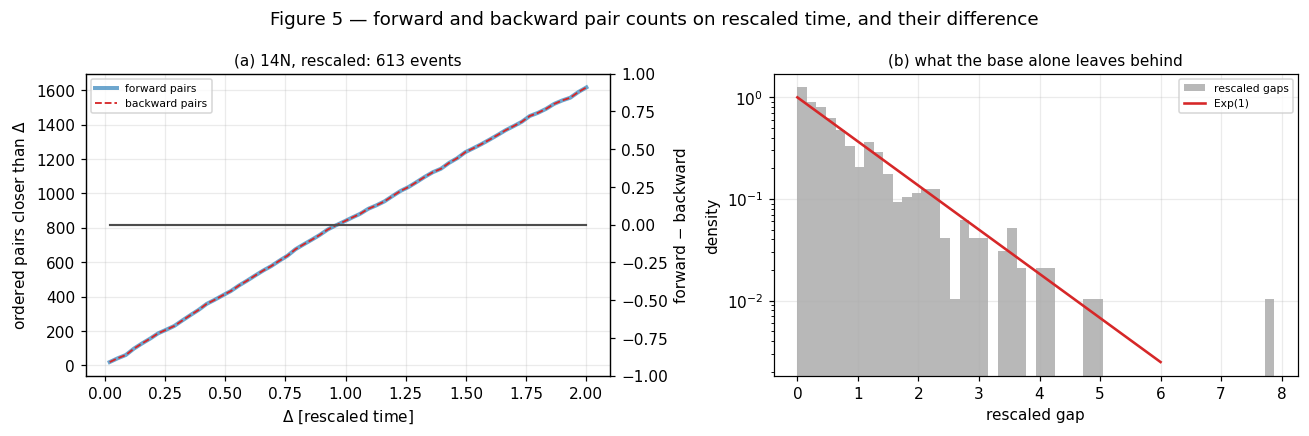

largest |forward - backward| over 60 separations: 0
Exactly zero, for any data: the two counts run over the same ordered pairs with i and j exchanged.


In [134]:
# Given: Figure 5 — the test that cannot work, on the rescaled events of a real wing. Rescaling by the
# base's own marginal rate is what removes the smooth structure, so if anything could show an arrow here
# it would be visible on these times.
rescale_wing = SCORED_WINGS[0]
rescale_bank = history_of(EVENTS, [rescale_wing])[rescale_wing]
rescale_fn = (CHAMPION_INTENSITY[rescale_wing] if rescale_wing in CHAMPION_INTENSITY
              else FILM_INTENSITY[rescale_wing])
RESCALED = np.cumsum(rescaled_gaps_history(rescale_bank, time_marginal(rescale_fn),
                                           np.zeros(N_CHANNELS),
                                           np.random.default_rng(SEED + 7)))
DELTAS = np.linspace(0.02, 2.0, 60)
FORWARD, BACKWARD = pair_counts(RESCALED, DELTAS)

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.0))
draw_pair_symmetry(axes[0], DELTAS, FORWARD, BACKWARD,
                   f"(a) {rescale_wing}, rescaled: {len(RESCALED):,} events")
axes[1].hist(np.diff(np.concatenate([[0.0], RESCALED])), bins=50, density=True, color="0.72",
             label="rescaled gaps")
grid = np.linspace(0.0, 6.0, 200)
axes[1].plot(grid, np.exp(-grid), lw=1.7, color="tab:red", label="Exp(1)")
axes[1].set_yscale("log")
axes[1].set_xlabel("rescaled gap")
axes[1].set_ylabel("density")
axes[1].set_title("(b) what the base alone leaves behind", fontsize=10)
axes[1].legend(fontsize=7)

fig.suptitle("Figure 5 — forward and backward pair counts on rescaled time, and their difference")
plt.tight_layout()
plt.show()

print(f"largest |forward - backward| over {len(DELTAS)} separations: "
      f"{int(np.max(np.abs(FORWARD - BACKWARD)))}")
print("Exactly zero, for any data: the two counts run over the same ordered pairs with i and j "
      "exchanged.")

### A generator, so the statistic can be calibrated

`simulate_wing` — Week 3's thinning, which every week since has used — is *invalid for a conditional
intensity*, and not in a way that can be patched. It draws every proposal at once, in random order,
from a single bound: at the moment a proposal is tested there is no "past" for it to condition on, and
the bound itself would depend on which events happened to be realized.

The right algorithm is *Ogata sequential thinning*: step forward in `s`, keep a running bound valid
over the step ahead, draw a candidate gap from it, accept with probability rate-over-bound, and add an
accepted candidate to the history before drawing the next one. The bound works because the base is
bounded over the step and the history term can only *decay* between one candidate and the next.

This is also the one place an exponential kernel's *recursion* pays off. Integrate latitude out and each
parent contributes a constant times `exp(−(s − sᵢ)/τ)`, so a running total decays by `exp(−Δs/τ)` and
each new parent adds its own latitude mass: `O(1)` per step instead of a sum over every past event. It
works for the latitude-*integrated* rate and *not* for the bank in Task 56, where the latitude factor
couples parent and child and no such recursion exists.

In [135]:
### TASK 61: Ogata sequential thinning for a conditional intensity
### BEGIN SOLUTION
TAU_PER_CHANNEL = np.array([TAUS[j] for j, k in CHANNELS])
ELL_PER_CHANNEL = np.array([ELLS[k] for j, k in CHANNELS])
HIST_CUTOFF = 20.0                 # decay constants beyond which a parent's latitude term is dropped


def channel_mass_of(abs_lat):
    """One new parent's latitude mass in every channel, so the running state can be updated."""
    return np.array([latitude_mass(abs_lat, ELLS[k]) for j, k in CHANNELS], dtype=float).ravel()


def simulate_hawkes_wing(intensity_fn, nu, rng, s_lo=S_A, s_hi=S_B, n_steps=48, max_events=25000):
    """Events of a self-exciting process, by sequential thinning. Returns (latitudes, times).

    `nu` is in offspring units, so the stability condition is a sum. It is asserted BEFORE anything is
    generated: an explosive fit is a result to report, not a run to wait out.
    """
    ratio = branching_ratio(nu)
    assert ratio < 1.0, (
        f"the fitted branching ratio is {ratio:.4f}, which is not below 1. The process these "
        f"parameters describe is explosive: every generation is at least as large as the last, and "
        f"generating from it would not terminate. Report that, do not patch it.")
    beta = beta_of(nu)
    base_marginal = np.asarray(time_marginal(intensity_fn, S_MESH), dtype=float)
    edges = np.linspace(s_lo, s_hi, n_steps + 1)
    lat_out, s_out = [], []
    state = np.zeros(N_CHANNELS)              # per-channel history rate, beta already folded in
    s = s_lo

    for lo, hi in zip(edges[:-1], edges[1:]):
        window = (S_MESH >= lo) & (S_MESH <= hi)
        base_max = float(base_marginal[window].max()) if window.any() else 0.0
        s = max(s, lo)
        while True:
            bound = base_max + float(state.sum())
            if bound <= 0.0:
                s = hi
                break
            step = float(rng.exponential(1.0 / bound))
            if s + step >= hi:                 # nothing more in this step: decay to its edge
                state *= np.exp(-(hi - s) / TAU_PER_CHANNEL)
                s = hi
                break
            state *= np.exp(-step / TAU_PER_CHANNEL)
            s += step
            rate = float(np.interp(s, S_MESH, base_marginal) + state.sum())
            if rng.uniform() * bound >= rate:  # rejected: the bound still holds, keep going
                continue

            # accepted. Draw its latitude from the conditional density at this instant, by inverse CDF
            # on the 241-node latitude mesh, then let it join the history.
            density = np.asarray(intensity_fn(LAM_2D, np.full_like(LAM_2D, s)), dtype=float)
            if s_out:
                past_lat, past_s = np.asarray(lat_out), np.asarray(s_out)
                for m in np.flatnonzero(beta):
                    j, k = CHANNELS[int(m)]
                    age = s - past_s
                    near = age < HIST_CUTOFF * TAUS[j]
                    if not near.any():
                        continue
                    weight = beta[int(m)] * np.exp(-age[near] / TAUS[j])
                    density += (weight * np.exp(-(LAM_2D[:, None] - past_lat[near]) ** 2
                                                / (2.0 * ELLS[k] ** 2))).sum(axis=1)
            density = np.maximum(density, 0.0)
            cdf = np.concatenate([[0.0], cumulative_trapezoid(density, LAM_2D)])
            new_lat = (float(np.interp(rng.uniform(0.0, cdf[-1]), cdf, LAM_2D)) if cdf[-1] > 0.0
                       else float(rng.uniform(0.0, LAM_MAX)))
            lat_out.append(new_lat)
            s_out.append(s)
            state += beta * channel_mass_of(new_lat)
            if len(s_out) >= max_events:
                print(f"   sequential thinning stopped at {max_events:,} events (n = {ratio:.3f})")
                return np.array(lat_out), np.array(s_out)
    return np.array(lat_out), np.array(s_out)
### END SOLUTION
# Reference workflow:
#   1. Assert the branching ratio is below 1 before doing anything, with a message that says why. This
#      guard is the difference between reporting an explosive fit and watching a cell never finish.
#   2. Split the window into steps. On each step, the majorant is the base's largest marginal rate over
#      that step plus the history's rate *at the step's start* — which bounds it over the whole step
#      because the history can only decay while no new event is added.
#   3. Draw a candidate gap from the majorant, decay the running history state to the candidate time,
#      and accept with probability (true rate / majorant). A rejection costs nothing and the bound still
#      holds, so continue from where you are.
#   4. On acceptance, the latitude is drawn from the conditional density at that instant — the base's
#      latitude profile plus every recent parent's kernel — by inverse CDF on `LAM_2D`. Then the new
#      event joins the running state at full strength, which is the only line that makes this
#      self-exciting rather than Poisson.
#   5. Keep the state per channel and decay each channel by its own timescale. Dropping parents older
#      than about twenty decay constants is a stated approximation in the latitude draw and nowhere else.

In [136]:
# Put your code for Task 61 here

### The statistic, and the one way it could fool us

The obvious construction is to fit the bank forwards and backwards on each wing and difference the two
gains. *Do not do that.* The history term is *realization-specific*: it knows exactly where this wing's
events were. Fitted on the same wing it is then scored on, it reproduces them almost perfectly in
either direction, the two gains come out in the hundreds of nats, and what you are left calibrating is
an overfitting artifact with a correspondingly enormous noise floor.

So the coefficients are fitted on the fold's *training* wings, read in one direction, and applied to a
wing the fit never saw. Two coefficient vectors — `ν⁺` from the training wings read forwards, `ν⁻` from
the same wings read backwards, the `bankrev` arm — and the statistic is

> `𝒜 = (gain from ν⁺, read forwards) − (gain from ν⁻, read backwards)`, in nats per hemicycle-year,

both evaluated on the held-out wing with its base matched to its own count. The base appears in both
terms and cancels exactly. Positive means the past predicts this wing's future better than its future
predicts its past.

In [137]:
### TASK 62: The asymmetry statistic, and the two generators that calibrate it
### BEGIN SOLUTION
def count_matched(intensity_fn, n_events):
    """`intensity_fn` rescaled by one scalar so its integral over the window is `n_events`.

    Applied identically in both directions, so it cannot create an asymmetry. Without it the gains are
    dominated by correcting a count the fold's `c` got wrong for this particular wing, which has nothing
    to do with the order its events arrived in.
    """
    total = integrate_2d(np.asarray(intensity_fn(LAM_2D[:, None], S_2D[None, :]), dtype=float))
    scale = (n_events / total) if total > 0.0 else 1.0
    return lambda abs_lat, s: scale * np.asarray(intensity_fn(abs_lat, s), dtype=float)


def directional_nu(bank_run, cycle, reflected, channels=ALL_CHANNELS):
    """Fit the bank on one fold's TRAINING wings, read in one direction, with that fold's base frozen.

    This is Task 58's block verbatim, which is the point: `fit_nu` profiles `c` out by count matching at
    every candidate, so the coefficients cannot buy anything by simply adding rate. Forwards this
    reproduces the `bank` arm's coefficients; reflected, it is the `bankrev` arm.
    """
    fold = fold_base_of(bank_run, cycle)
    events, _ = fold_events(fold["train"])
    bank = history_of(events, fold["train"], reflected=reflected, channels=channels)
    amp_of = (lambda h: fold["amps"][h]) if "amps" in fold else fold["a_of"]
    at, integral = [], 0.0
    for h in fold["train"]:
        fn = fold["base_of"](h, amp_of(h))
        at.append(np.asarray(fn(bank[h]["lat"], bank[h]["s_true"]), dtype=float))
        integral += integrate_2d(np.asarray(fn(LAM_2D[:, None], S_2D[None, :]), dtype=float))
    n_total = sum(len(bank[h]["s"]) for h in fold["train"])
    nu, _ = fit_nu(np.concatenate(at), float(integral),
                   np.concatenate([bank[h]["H"] for h in fold["train"]]),
                   np.sum([bank[h]["A"] for h in fold["train"]], axis=0), n_total,
                   channels=channels)
    return nu


def asymmetry_of(abs_lat, event_s, base_fn, nu_forward, nu_backward, channels=ALL_CHANNELS):
    """The held-out asymmetry on one event set, using coefficients fitted on other wings.

    Both directions are evaluated at MATCHED COUNT: the base is scaled so that base plus history
    integrates to this event set's own size, by Task 58's identity. That is the only reason it is
    admissible to use the wing's own count here — the statistic is a difference of two readings at the
    same count, so the count contributes identically to both and cancels. It is not a held-out score and
    must never be quoted as one.

    The base also cancels: reflecting the data while evaluating the base at the original times is the
    same thing as reflecting the base too, so the no-history term is identical in the two directions.
    """
    abs_lat = np.asarray(abs_lat, dtype=float)
    event_s = np.asarray(event_s, dtype=float)
    one = {"wing": (abs_lat, event_s)}
    forward = history_of(one, ["wing"], channels=channels)["wing"]
    backward = history_of(one, ["wing"], reflected=True, channels=channels)["wing"]
    n_obs = len(event_s)
    unit_int = integrate_2d(np.asarray(base_fn(LAM_2D[:, None], S_2D[None, :]), dtype=float))

    def log_l(bank, nu):
        beta = beta_of(nu)
        unit_at = np.asarray(base_fn(bank["lat"], bank["s_true"]), dtype=float)
        c = solve_c_history(n_obs, unit_int, float(bank["A"] @ beta))
        if not np.isfinite(c) or c <= 0.0:
            return -np.inf
        at = c * unit_at + bank["H"] @ beta
        if np.any(at <= 0.0):
            return -np.inf
        # c * unit_int + A.beta is exactly n_obs, so the integral term is the constant n_obs
        return float(np.sum(np.log(at)) - n_obs)

    bare = log_l(forward, np.zeros(N_CHANNELS))
    gain_f = log_l(forward, nu_forward) - bare
    gain_b = log_l(backward, nu_backward) - bare
    return dict(statistic=float((gain_f - gain_b) / WINDOW_YEARS),
                forward=float(gain_f / WINDOW_YEARS), backward=float(gain_b / WINDOW_YEARS))


def null_latitudes(new_s, lat_obs, s_obs, rng, window=0.75):
    """Give memoryless simulated times the observed latitude distribution *local to each time*.

    Each simulated event draws independently from the latitudes observed within `window` years of it, so
    a wing's shape in the (latitude, time) plane survives while its memory does not. The independence
    across events is the whole point.
    """
    lat_obs, s_obs = np.asarray(lat_obs, dtype=float), np.asarray(s_obs, dtype=float)
    out = np.empty(len(new_s))
    for i, when in enumerate(np.asarray(new_s, dtype=float)):
        near = np.flatnonzero(np.abs(s_obs - when) <= window)
        pool = lat_obs if not len(near) else lat_obs[near]
        out[i] = pool[rng.integers(len(pool))]
    return out


def draw_asymmetry(ax, measured, null_values, hawkes_values, seed=SEED):
    """The measured statistic per wing, against a process with no memory and one with known memory."""
    ax.axhline(0.0, color="k", lw=1.0)
    spread = float(np.std(null_values, ddof=1)) if len(null_values) > 1 else 0.0
    centre = float(np.mean(null_values)) if len(null_values) else 0.0
    ax.axhspan(centre - 2.0 * spread, centre + 2.0 * spread, color="0.86", zorder=0,
               label="±2 sd of the memoryless null")
    rng = np.random.default_rng(seed)
    for column, values, style, colour, name in (
            (0.0, null_values, "o", "0.45", "no memory"),
            (1.0, hawkes_values, "s", "tab:orange", "simulated triggering")):
        if len(values):
            ax.plot(column + rng.normal(0.0, 0.06, len(values)), values, style, ms=4.0,
                    color=colour, alpha=0.75, label=name)
    labels = list(measured)
    ax.plot(np.full(len(labels), 2.0), [measured[h]["statistic"] for h in labels], "D", ms=6.5,
            color="tab:red", label="the real wings")
    ax.set_xticks([0.0, 1.0, 2.0])
    ax.set_xticklabels(["no memory", "known memory", "the Sun"])
    ax.set_xlim(-0.5, 2.5)
    ax.set_ylabel("forward gain − backward gain\n[nats per hemicycle-yr]")
    ax.set_title("(a) does the clustering have an arrow of time?", fontsize=10)
    ax.legend(fontsize=7)
### END SOLUTION
# Reference workflow:
#   1. `count_matched`: one scalar, so the base integrates to the event count of whatever it is about to
#      be compared against. Identical in both directions by construction.
#   2. `directional_nu`: rebuild the fold's base from the cached run, re-derive its training events,
#      build the bank in the requested direction, and hand the pieces to Task 58's `fit_nu` — which
#      profiles `c` out by count matching, so the coefficients cannot buy anything by merely adding
#      rate. Forwards this reproduces the `bank` arm's coefficients; reflected, it is the `bankrev` arm.
#   3. `asymmetry_of`: build the held-out wing's bank both ways and score it three times — no history,
#      the forward coefficients on the forward bank, the backward coefficients on the backward bank —
#      re-solving `c` each time against this wing's own count. Convince yourself of two things before you
#      subtract: that the no-history term is identical in the two directions, and that the integral term
#      collapses to the event count.
#   4. `null_latitudes`: Week 1's null gives times only. Give each simulated time a latitude drawn
#      independently from the latitudes observed near that time.
#   5. `draw_asymmetry`: three columns — null draws, simulated-triggering draws, the real wings — with a
#      band at twice the null's standard deviation around the null's own mean, not around zero. Jitter
#      the two cloud columns horizontally. Think about why the band is not centred on zero.

In [138]:
# Put your code for Task 62 here

asymmetry on 6 wings, 48 memoryless draws and 6 simulated self-exciting wings · 28 s


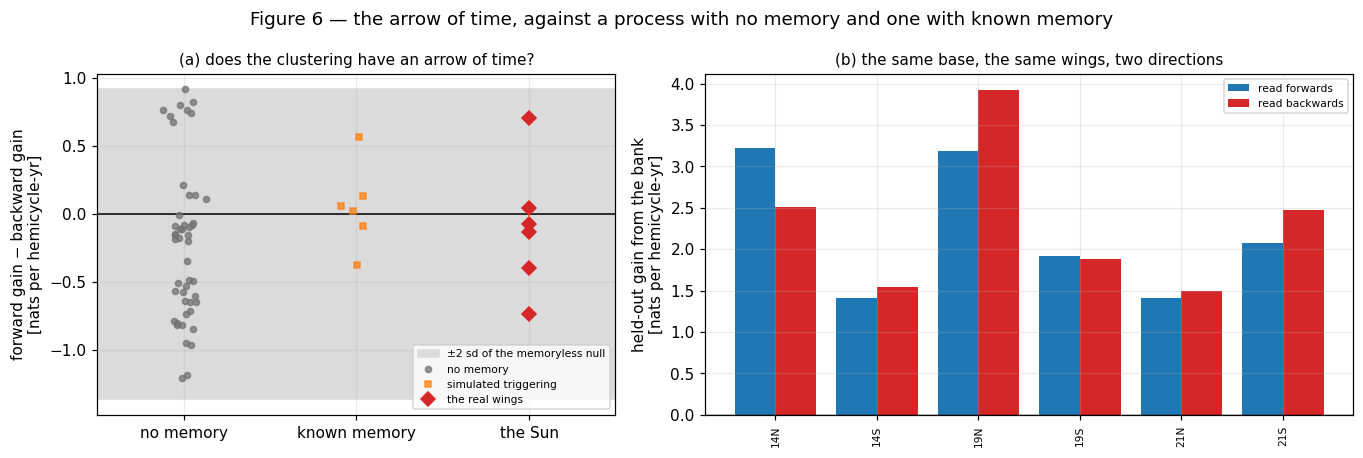

     statistic  forward  backward
14N     0.7061   3.2208    2.5147
14S    -0.1323   1.4135    1.5459
19N    -0.7389   3.1856    3.9244
19S     0.0452   1.9237    1.8785
21N    -0.0783   1.4151    1.4934
21S    -0.4017   2.0732    2.4750

forward coefficients per fold (n): {14: 0.4575, 19: 0.4529, 21: 0.4626}
backward coefficients per fold (n): {14: 0.4265, 19: 0.4275, 21: 0.4396}

memoryless null (non-circular): mean -0.2255, sd 0.5698 (48 draws) -- the noise floor and the edge offset together, so the mean is not zero and is not assumed to be
simulated triggering at n = 0.15 (circular): mean +0.0512 (6 wings) -- sensitivity only, never existence
the real wings: mean -0.1000, 0 of 6 more than two null standard deviations from the null's mean


In [139]:
# Given: Figure 6 — the statistic, read on three kinds of process. Every wing is measured with the
# coefficients of the fold that held IT out, so nothing here is in-sample. The calibration at `CAL_NU`
# puts all 0.15 offspring on the two shortest timescales, which is where Week 1's one surviving result
# lives.
N_NULL_DRAWS = 8
CAL_NU = np.zeros(N_CHANNELS)
CAL_NU[list(SHORT_CHANNELS)] = 0.15 / len(SHORT_CHANNELS)

# The base held fixed here is the NO-HISTORY one. That matters: the `bank` arm's base was fitted with a
# dominant history term beside it, so it only ever had to supply a few percent of the rate and its shape
# is barely constrained. Reading an asymmetry against *that* base would measure how bad it is on its own.
ARROW_RUN = RUNS[("champion", "nohist")]
started = time.time()
DIRECTIONAL = {cycle: dict(forward=directional_nu(ARROW_RUN, cycle, False),
                           backward=directional_nu(ARROW_RUN, cycle, True))
               for cycle in ARROW_RUN["folds"]}
MEASURED, NULL_STATS, HAWKES_STATS = {}, [], []
for cycle, nus in DIRECTIONAL.items():
    fold = fold_base_of(ARROW_RUN, cycle)
    for label in FOLD_UNITS[cycle]:
        lat_held, t_held = RAW_EVENTS[label]
        shift = align_one(t_held, lat_held, T0_START[label], fold["mu_b"])
        s_held = t_held - (T0_START[label] + shift)
        inside = (s_held > S_A) & (s_held < S_B)
        lat_in, s_in = lat_held[inside], s_held[inside]
        base_fn = fold["base_of"](label, fold["a_of"](label))
        MEASURED[label] = asymmetry_of(lat_in, s_in, base_fn, nus["forward"], nus["backward"])

        rng = np.random.default_rng(SEED + 2000 + FIT_WINGS.index(label))
        for _ in range(N_NULL_DRAWS):
            null_s = simulate_rate_matched_null(s_in, smooth_days=90.0, rng=rng)
            if len(null_s) < 20:
                continue
            null_lat = null_latitudes(null_s, lat_in, s_in, rng)
            NULL_STATS.append(asymmetry_of(null_lat, null_s, base_fn,
                                           nus["forward"], nus["backward"])["statistic"])

        hawkes_lat, hawkes_s = simulate_hawkes_wing(count_matched(base_fn, len(s_in)), CAL_NU, rng)
        if len(hawkes_s) >= 20:
            HAWKES_STATS.append(asymmetry_of(hawkes_lat, hawkes_s, base_fn,
                                             nus["forward"], nus["backward"])["statistic"])

NULL_STATS, HAWKES_STATS = np.array(NULL_STATS), np.array(HAWKES_STATS)
NULL_SD = float(np.std(NULL_STATS, ddof=1)) if len(NULL_STATS) > 1 else np.nan
NULL_MEAN = float(np.mean(NULL_STATS)) if len(NULL_STATS) else np.nan
print(f"asymmetry on {len(MEASURED)} wings, {len(NULL_STATS)} memoryless draws and "
      f"{len(HAWKES_STATS)} simulated self-exciting wings · {time.time() - started:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw=dict(width_ratios=[1.0, 1.25]))
draw_asymmetry(axes[0], MEASURED, NULL_STATS, HAWKES_STATS)

labels = list(MEASURED)
position = np.arange(len(labels))
axes[1].bar(position - 0.2, [MEASURED[h]["forward"] for h in labels], width=0.4, color="tab:blue",
            label="read forwards")
axes[1].bar(position + 0.2, [MEASURED[h]["backward"] for h in labels], width=0.4, color="tab:red",
            label="read backwards")
axes[1].axhline(0.0, color="k", lw=0.9)
axes[1].set_xticks(position)
axes[1].set_xticklabels(labels, rotation=90, fontsize=7)
axes[1].set_ylabel("held-out gain from the bank\n[nats per hemicycle-yr]")
axes[1].set_title("(b) the same base, the same wings, two directions", fontsize=10)
axes[1].legend(fontsize=7)

fig.suptitle("Figure 6 — the arrow of time, against a process with no memory and one with known memory")
plt.tight_layout()
plt.show()

ASYMMETRY = pd.DataFrame(MEASURED).T[["statistic", "forward", "backward"]].astype(float)
print(ASYMMETRY.round(4).to_string())
print(f"\nforward coefficients per fold (n): "
      f"{ {c: round(branching_ratio(v['forward']), 4) for c, v in DIRECTIONAL.items()} }")
print(f"backward coefficients per fold (n): "
      f"{ {c: round(branching_ratio(v['backward']), 4) for c, v in DIRECTIONAL.items()} }")
print(f"\nmemoryless null (non-circular): mean {NULL_MEAN:+.4f}, sd {NULL_SD:.4f} "
      f"({len(NULL_STATS)} draws) -- the noise floor and the edge offset together, so the mean is not "
      f"zero and is not assumed to be")
print(f"simulated triggering at n = {CAL_NU.sum():.2f} (circular): mean {np.mean(HAWKES_STATS):+.4f} "
      f"({len(HAWKES_STATS)} wings) -- sensitivity only, never existence")
beyond = int(np.sum(np.abs(ASYMMETRY["statistic"] - NULL_MEAN) > 2.0 * NULL_SD))
print(f"the real wings: mean {ASYMMETRY['statistic'].mean():+.4f}, {beyond} of {len(ASYMMETRY)} more "
      f"than two null standard deviations from the null's mean")

Nothing is marked for you here. The block below is for your tutor.

```text
TUTOR DIRECTIVE — Section 3, where an arrow of time can and cannot live.

Material: the student is about to count near-pairs in both directions on time-rescaled events, write a
sequential generator for a process with memory, and build a statistic that compares a history term
fitted forwards against the same term fitted on the reversed sequence. None of it is written yet.

This section carries the FIRST of the session's four required written predictions.

PREDICTION 1, required before any of the destinations below. Ask the student to commit, in writing, to
whether counting pairs closer than some separation forward in time can differ from counting them
backward, and why. Whichever way they answer, require them to justify it by writing down the two sets
of pairs and comparing them, rather than by reasoning about what the Sun does. Do not tell them the
answer and do not indicate whether they have it: this is settleable on paper in under a minute, and
the figure in this section is what confirms it. If their reasoning appeals to the physics rather than
to the two sets, that is the thing to push on, in either direction.

Destinations.

1. Why this reading is more robust than a held-out score. Require from the student a statement of what
   a smooth error in the base model does to each of the two readings. Bridge towards the asymmetry
   rather than stating it: ask what a deterministic rate function looks like when the clock is
   reversed, and then what a parent-and-child relationship looks like.

2. "Model-light, not model-free." Require them to name what the base is still needed FOR, and then the
   sharper version: not that the base is absent but that it CANCELS. Ask what has to be done to the
   base, as well as to the data, for the cancellation to be exact. A student who says "we just freeze
   the base" has half of it.

3. The two calibrations and their different jobs. One has the data's rate envelope and no memory; one
   has memory of a strength we chose. Require them to say which of the two could establish that
   triggering EXISTS, and which could only establish that the statistic can SEE it. The circularity in
   the second one is the thing to name. Also ask what the first one is absorbing that a simple noise
   estimate would not — the two directions do not have the same compensator, and that edge asymmetry
   is real.

4. Why fixed-bound thinning is the wrong algorithm here rather than a bug to patch. Ask them what a
   proposal drawn in random order would condition on. Then ask what the bound in a sequential version
   can safely be, and why the history term's decay is what makes any bound possible at all.

Prefer as anchors the targets least likely to be in play yet: time reversibility, self-exciting
process, Hawkes process, Cox process, branching ratio.
```

### Dialogue for Section 3 — where the conversation should land (instructor only)

*Prediction 1.* The counts are *identically equal*, for any data. Forward pairs are
`{(i, j) : 0 < t_j − t_i < Δ}`; backward pairs are `{(i, j) : 0 < t_i − t_j < Δ}`. Swap the labels and
the second set is the first. No data can break it. The usual wrong answer — "triggering should make
forward pairs more common" — confuses the *pair* with the *ordered* pair, and getting a student to see
that is worth more than the figure.

*Why the arrow has to be conditional.* A second-order statistic sees only separations. An arrow of
time is a statement about prediction: given the past, the future is elevated; given the future, the
past is not. That is a property of `Λ(· | H_s)` and it is invisible to any count of separations.

*The cancellation.* Reflect `s → S_A + S_B − s` in the data *and* evaluate the base at the original
times — which is the same thing as reflecting the base too. Then the base's event sum and its mesh
integral are unchanged, so the difference of the two gains contains no base term at all. Freezing the
base without reflecting it would not cancel: the base is strongly asymmetric in `s` (a wing rises and
decays differently) and the reversed data would simply fit it badly.

*What does not cancel, and why the null is required.* The compensators differ. Forwards, a parent at
`sᵢ` has until `S_B` to produce children; backwards, it has back to `S_A`. Events are not uniform in
the window, so the two integrals are genuinely different and the statistic has a non-zero expectation
even with no memory at all. The memoryless null measures that offset and its spread together, which is
precisely why it cannot be replaced by "assume the mean is zero".

*The two calibrations.* The rate-matched null is non-circular: it is built from the observed times
and contains no model. The simulated Hawkes wing is circular, because it is generated from the family
being fitted — it bounds *sensitivity*, not existence. If a student proposes using the Hawkes
calibration as evidence, the reply is that a detector tested only on its own signal has not been tested.

*Thinning.* Fixed-bound thinning draws all proposals first; at test time there is no past, and the
bound depends on the realized events, so it is not a bound. Sequential thinning works because between
two candidates nothing is added and the history only decays — so the rate at the start of a step,
plus the base's maximum over the step, bounds the rate throughout it.

---
## 4 · The same question asked of two different bases

This is the week's result, and it rests on one observation that is easy to miss.

"Does history matter" is not a question about the Sun on its own. It is "does history matter *given
what the base model already explains*". The history model *contains* the base — set every coefficient
to zero and the base comes back exactly — so this is a **nested model** comparison living entirely
*inside* one base. `Δ_NLL(history | champion)` and `Δ_NLL(history | neural field)` are *different
quantities*. They can legitimately disagree, and if they do, neither is wrong.

Why would they disagree? Both bases are smooth in `(|λ|, s)` and set by two numbers per wing, so
neither can represent a burst at one spot in one wing unless that burst is systematic across wings.
The history features are *realization-specific* — they know where *this* wing's events were. So the
two only ever compete for the *systematic* part of the clustering, and a 5,762-parameter conditioned
field absorbs far more of it than 29 parameters of fitted physics. That asymmetry is the experiment:

> *The difference between the two arms is the measurement.* It is the share of the clustering that
> the two explanations can trade for each other — the **degeneracy** between them, as a number.

### The four-way reading, and you commit to a cell before seeing any coefficient

| `Δ` on the champion | `Δ` on the neural field | reading |
|---|---|---|
| > 0 | ≈ 0 | the "memory" was *champion misspecification*, not memory |
| > 0 | > 0, about the same | *triggering survives the harder bar* — a real result |
| ≈ 0 | ≈ 0 | *no memory* at these timescales, in this data |
| > 0 | *larger* than on the champion | *suspect the fit* — epoch budget, seed, or the `β`–`c` trade |

"≈ 0" means *below the resolution floor declared in Section 2*, printed beside every difference below
and drawn as the grey cross in Figure 7. Below the floor is *no detection*, not a small effect.

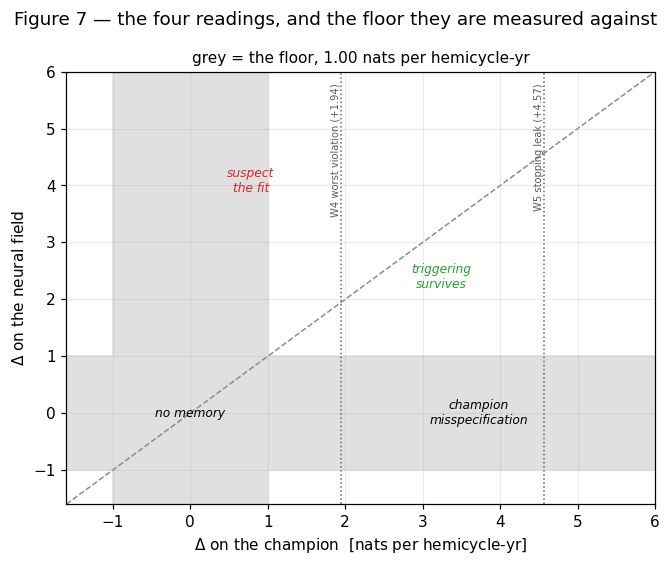

the grey cross is the floor: 1.0019 nats per hemicycle-year on 3 fold cycles. Inside it is no detection, on either base.


In [140]:
# Given: Figure 7 — the same four readings as the table, drawn, with the floor they are measured against
# and two of the program's measured effects for scale. Write your predicted number on it before Task 63
# computes one. `draw_four_way` is reused in Figure 8 with the measured point on it.
LEAK_ANCHORS = ((1.94, "W4 worst violation"), (4.5716, "W5 stopping leak"))


def draw_four_way(ax, floor, point=None, anchors=LEAK_ANCHORS):
    """The four-way reading as a plane: a gain on each base, against the floor below which neither is."""
    lo, hi = -1.6, max(6.0, 3.0 * floor)
    ax.axhspan(-floor, floor, color="0.88", zorder=0)
    ax.axvspan(-floor, floor, color="0.88", zorder=0)
    ax.plot([lo, hi], [lo, hi], ls="--", lw=1.0, color="0.55", zorder=1)
    ax.text(0.0, 0.0, "no memory", fontsize=8, ha="center", va="center", style="italic")
    ax.text(0.62 * hi, 0.0, "champion\nmisspecification", fontsize=8, ha="center", va="center",
            style="italic")
    ax.text(0.54 * hi, 0.40 * hi, "triggering\nsurvives", fontsize=8, ha="center", va="center",
            style="italic", color="tab:green")
    ax.text(0.13 * hi, 0.68 * hi, "suspect\nthe fit", fontsize=8, ha="center", va="center",
            style="italic", color="tab:red")
    for value, name in anchors:
        ax.axvline(value, ls=":", lw=1.0, color="0.4")
        ax.text(value, hi - 0.15, f"{name} ({value:+.2f}) ", fontsize=6.5, rotation=90,
                va="top", ha="right", color="0.35")
    if point is not None:
        (x, xe), (y, ye) = point
        ax.errorbar([x], [y], xerr=[xe], yerr=[ye], fmt="D", ms=8.0, color="tab:orange",
                    capsize=4.0, lw=1.8, zorder=5, label="measured")
        ax.legend(fontsize=7, loc="upper left")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel(r"$\Delta$ on the champion  [nats per hemicycle-yr]")
    ax.set_ylabel(r"$\Delta$ on the neural field")
    ax.set_title(f"grey = the floor, {floor:.2f} nats per hemicycle-yr", fontsize=10)


fig, ax = plt.subplots(figsize=(6.2, 5.2))
draw_four_way(ax, SEED_SPREAD)
fig.suptitle("Figure 7 — the four readings, and the floor they are measured against")
plt.tight_layout()
plt.show()

print(f"the grey cross is the floor: {SEED_SPREAD:.4f} nats per hemicycle-year on {len(FOLD_CYCLES)} "
      f"fold cycles. Inside it is no detection, on either base.")

In [141]:
### TASK 63: Eight coefficients on two bases, paired wing by wing
### BEGIN SOLUTION
def history_board(runs, reference_arm="nohist", source=HEADLINE):
    """Every (base, arm) row, each paired against its OWN base's no-history row.

    Pairing within a base is the whole point: a history gain is only defined relative to the base it was
    measured against, so there is no column here that compares a champion row with a neural row.
    """
    rows, stats = [], {}
    for (base, arm), result in runs.items():
        table = rows_of(result)
        reference = runs.get((base, reference_arm))
        paired = (paired_stats(result, reference, source) if reference is not None
                  and arm != reference_arm else None)
        stats[(base, arm)] = paired
        rows.append(dict(base=base, arm=arm, fitted=result["n_params"],
                         n=float(np.sum(result["nu"])),
                         held_nll=float(table[f"nll/yr ({source})"].mean()),
                         spread=float(table[f"nll/yr ({source})"].std(ddof=1)),
                         delta=np.nan if paired is None else -paired["mean"],
                         se=np.nan if paired is None else paired["se"],
                         floor=np.nan if paired is None else resolution_floor(paired),
                         better=("—" if paired is None
                                 else f"{paired['better']}/{paired['n']}"),
                         ks=float(table[f"ks ({source})"].median()),
                         ks_ok=f"{int((table[f'ks_p ({source})'] > 0.05).sum())}/{len(table)}"))
    return pd.DataFrame(rows).set_index(["base", "arm"]), stats


def draw_beta_bank(ax, runs, arm="bank"):
    """Each base's fitted coefficients, channel by channel, in offspring units."""
    position = np.arange(N_CHANNELS)
    width = 0.38
    for offset, (base, colour) in zip((-width / 2, width / 2),
                                      (("champion", "tab:blue"), ("film", "tab:purple"))):
        if (base, arm) not in runs:
            continue
        ax.bar(position + offset, np.asarray(runs[(base, arm)]["nu"]), width=width, color=colour,
               label=base)
    ax.set_xticks(position)
    ax.set_xticklabels(CHANNEL_NAMES, rotation=90, fontsize=7)
    ax.set_ylabel(r"$\nu$ [offspring per event per channel]")
    ax.set_title("(a) the same eight channels, on two bases", fontsize=10)
    ax.legend(fontsize=7)


def draw_two_arm(ax, stats, arm="bank"):
    """Each base's history gain, paired wing by wing, with its own resolution floor drawn on."""
    entries = [(base, stats[(base, arm)]) for base in ("champion", "film")
               if (base, arm) in stats and stats[(base, arm)] is not None]
    ax.axvline(0.0, color="k", lw=1.0)
    for row, (base, paired) in enumerate(entries):
        floor = resolution_floor(paired)
        ax.axhspan(row - 0.42, row + 0.42, xmin=0.0, xmax=1.0, color="none")
        ax.errorbar([-paired["mean"]], [row], xerr=[paired["se"]], fmt="D", ms=7.0,
                    color="tab:blue" if base == "champion" else "tab:purple", capsize=4.0, lw=1.6)
        ax.plot(-paired["differences"].to_numpy(), np.full(paired["n"], row), "o", ms=3.6,
                color="0.5", alpha=0.6)
        ax.plot([-floor, floor], [row - 0.3, row - 0.3], lw=3.0, color="0.8",
                solid_capstyle="butt", label="resolution floor" if row == 0 else None)
    ax.set_yticks(np.arange(len(entries)))
    ax.set_yticklabels([base for base, _ in entries])
    ax.set_xlabel("history gain, held out  [nats per hemicycle-yr]\n(positive = history helps)")
    ax.set_title("(b) the same question, two bases", fontsize=10)
    ax.legend(fontsize=7, loc="lower right")
### END SOLUTION
# Reference workflow:
#   1. `history_board`: one row per (base, arm). Pair each arm against the **no-history row of its own
#      base** using Week 4's `paired_stats`, and carry the sign so that a positive `delta` means history
#      helped. Put the resolution floor in its own column beside the standard error — a reader must not
#      have to go and look it up.
#   2. There is deliberately no column comparing a champion row with a neural row. Work out why before
#      you add one: the nesting does not cross between bases.
#   3. `draw_beta_bank`: paired bars, one group per channel, one colour per base, in offspring units so
#      the heights are comparable across channels with very different timescales.
#   4. `draw_two_arm`: one row per base, the per-wing differences as points, the mean with its standard
#      error as a marker with error bars, and the resolution floor drawn as a bar beneath each row so
#      that "inside the floor" is something you can see rather than something you have to compute.

In [142]:
# Put your code for Task 63 here

In [143]:
# Given: the first check, before any interpretation. 16.4% of this catalog's inter-arrival times are
# exactly zero -- groups first recorded in the same observation share a timestamp -- so a coefficient at
# tau = 2 days is partly a measurement of the catalog. We refit with the ties broken (each event
# jittered inside its own day, stated seed) and report how much of the shortest channel survives.
TIE_FRACTION = {}
for label in SCORED_WINGS:
    gaps = np.diff(np.sort(EVENTS[label][1]))
    TIE_FRACTION[label] = float(np.mean(gaps <= 0.5 * ONE_DAY))

jitter_rng = np.random.default_rng(SEED + 909)
JITTERED = {h: (EVENTS[h][0], EVENTS[h][1] + jitter_rng.uniform(0.0, ONE_DAY, len(EVENTS[h][1])))
            for h in FIT_WINGS}
tie_fold = fold_base_of(RUNS[("champion", "nohist")], FOLD_CYCLES[0])
tie_train = tie_fold["train"]
TIE_NU = {}
for name, source in (("as recorded", EVENTS), ("ties jittered", JITTERED)):
    bank = history_of(source, tie_train)
    at, integral = [], 0.0
    for h in tie_train:
        fn = tie_fold["base_of"](h, tie_fold["amps"][h])
        at.append(np.asarray(fn(bank[h]["lat"], bank[h]["s_true"]), dtype=float))
        integral += integrate_2d(np.asarray(fn(LAM_2D[:, None], S_2D[None, :]), dtype=float))
    TIE_NU[name], _ = fit_nu(np.concatenate(at), float(integral),
                             np.concatenate([bank[h]["H"] for h in tie_train]),
                             np.sum([bank[h]["A"] for h in tie_train], axis=0),
                             sum(len(bank[h]["s"]) for h in tie_train))

print(f"gaps of half a day or less, per scored wing: "
      f"{ {h: f'{v:.1%}' for h, v in TIE_FRACTION.items()} }")
print(f"\nrefitted on cycle {FOLD_CYCLES[0]}'s training wings, coefficients in offspring units:")
print(f"   {'channel':12s} {'as recorded':>12s} {'ties jittered':>14s} {'survives':>10s}")
for m in range(N_CHANNELS):
    a, b = TIE_NU["as recorded"][m], TIE_NU["ties jittered"][m]
    share = f"{b / a:7.1%}" if a > 1.0e-6 else "      —"
    print(f"   {CHANNEL_NAMES[m]:12s} {a:12.5f} {b:14.5f} {share:>10s}")
print(f"   {'TOTAL n':12s} {TIE_NU['as recorded'].sum():12.5f} "
      f"{TIE_NU['ties jittered'].sum():14.5f} "
      f"{TIE_NU['ties jittered'].sum() / max(TIE_NU['as recorded'].sum(), 1e-9):9.1%}")
short_share = {name: (nu[list(SHORT_CHANNELS)].sum() / max(nu.sum(), 1.0e-9))
               for name, nu in TIE_NU.items()}
print(f"\nshare of the total on the two shortest timescales: "
      f"{ {k: f'{v:.1%}' for k, v in short_share.items()} }")
print("\nShort weight that does not survive the jitter was measuring the observing cadence; weight that\n"
      "sits on the long channels is a slow rate correction, not triggering. Either way it travels with\n"
      "every coefficient this week reports.")

gaps of half a day or less, per scored wing: {'14N': '11.4%', '14S': '13.6%', '19N': '25.3%', '19S': '21.7%', '21N': '18.5%', '21S': '16.1%'}

refitted on cycle 14's training wings, coefficients in offspring units:
   channel       as recorded  ties jittered   survives
   2d/3deg           0.00000        0.00000          —
   2d/10deg          0.00000        0.00000          —
   5d/3deg           0.00000        0.00000          —
   5d/10deg          0.00000        0.00000          —
   15d/3deg          0.00000        0.00000          —
   15d/10deg         0.00000        0.00000          —
   60d/3deg          0.45508        0.50597     111.2%
   60d/10deg         0.00252        0.00276     109.5%
   TOTAL n           0.45760        0.50872    111.2%

share of the total on the two shortest timescales: {'as recorded': '0.0%', 'ties jittered': '0.0%'}

Short weight that does not survive the jitter was measuring the observing cadence; weight that
sits on the long channels is a slow rat

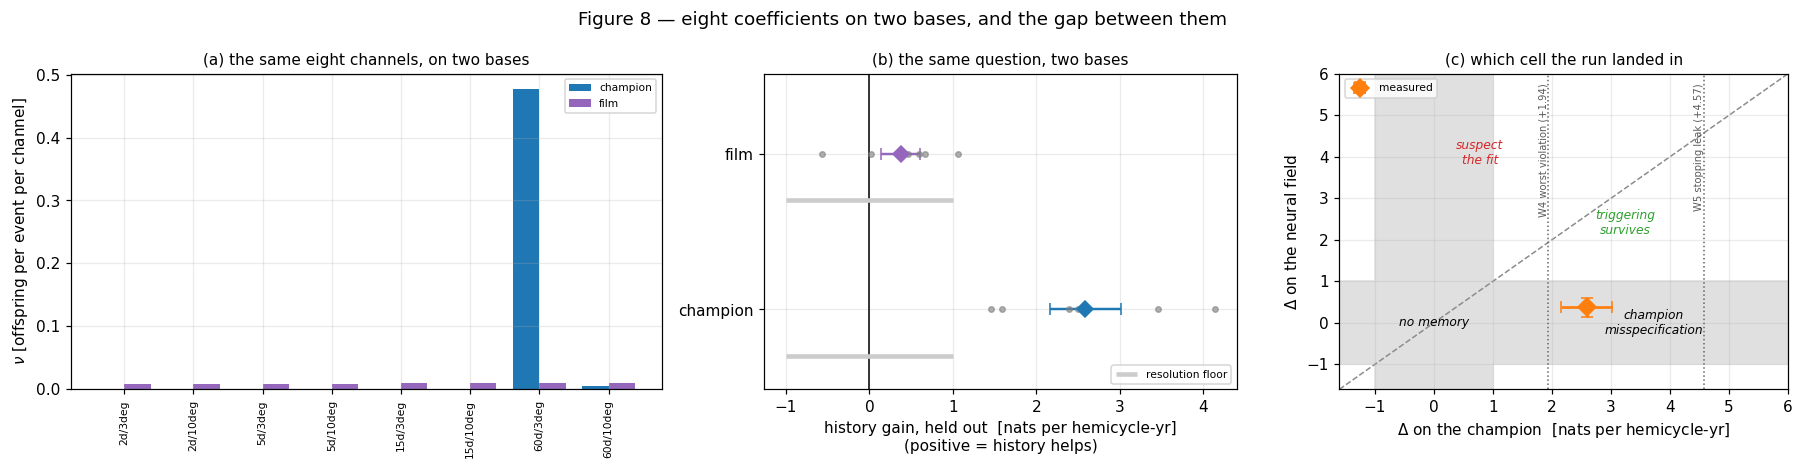

                 fitted       n  held_nll   spread   delta      se   floor better      ks ks_ok
base     arm                                                                                   
champion nohist      29  0.0000  -35.9771  27.7841     NaN     NaN     NaN      —  0.0449   3/6
         short       33  0.0081  -36.0050  27.7818  0.0279  0.0157  1.0019    5/6  0.0444   4/6
         bank        37  0.4829  -38.5666  28.3287  2.5895  0.4286  1.0019    6/6  0.0290   4/6
film     nohist    5762  0.0000  -35.6256  27.5717     NaN     NaN     NaN      —  0.0433   4/6
         bank      5770  0.0730  -36.0006  27.7648  0.3750  0.2328  1.0019    5/6  0.0344   4/6

the four-way reading, with the floor applied:
   champion  gain +2.5895 +/- 0.4286 nats per hemicycle-year, floor 1.0019 -> above the floor
   film      gain +0.3750 +/- 0.2328 nats per hemicycle-year, floor 1.0019 -> below the floor -- NO DETECTION

   the degenerate fraction -- how much of the clustering the two explanation

In [144]:
# Given: Figure 8 — the week's result. (a) the fitted coefficients on both bases; (b) the held-out
# history gain on each base, paired wing by wing, over its own resolution floor; (c) the same two
# numbers as one point on Figure 7's plane.
BOARD, BOARD_STATS = history_board(RUNS)

MEASURED_POINT = None
if BOARD_STATS.get(("champion", "bank")) is not None and BOARD_STATS.get(("film", "bank")) is not None:
    champ, film = BOARD_STATS[("champion", "bank")], BOARD_STATS[("film", "bank")]
    MEASURED_POINT = ((-champ["mean"], champ["se"]), (-film["mean"], film["se"]))

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.3), gridspec_kw=dict(width_ratios=[1.25, 1.0, 0.95]))
draw_beta_bank(axes[0], RUNS)
draw_two_arm(axes[1], BOARD_STATS)
CHAMP_BANK_STATS = BOARD_STATS.get(("champion", "bank"))
draw_four_way(axes[2], SEED_SPREAD if CHAMP_BANK_STATS is None
              else resolution_floor(CHAMP_BANK_STATS), point=MEASURED_POINT)
axes[2].set_title("(c) which cell the run landed in", fontsize=10)
fig.suptitle("Figure 8 — eight coefficients on two bases, and the gap between them")
plt.tight_layout()
plt.show()

print(BOARD.round(4).to_string())

CHAMP_STATS = BOARD_STATS.get(("champion", "bank"))
FILM_STATS = BOARD_STATS.get(("film", "bank"))
print("\nthe four-way reading, with the floor applied:")
for name, paired in (("champion", CHAMP_STATS), ("film", FILM_STATS)):
    if paired is None:
        print(f"   {name:9s} not run at breadth '{BREADTH}'")
        continue
    gain, floor = -paired["mean"], resolution_floor(paired)
    verdict = ("above the floor" if gain > floor else
               "below the floor -- NO DETECTION" if abs(gain) <= floor else
               "below the floor, and negative")
    print(f"   {name:9s} gain {gain:+.4f} +/- {paired['se']:.4f} nats per hemicycle-year, "
          f"floor {floor:.4f} -> {verdict}")
if CHAMP_STATS is not None and FILM_STATS is not None:
    gap = (-CHAMP_STATS["mean"]) - (-FILM_STATS["mean"])
    shared = CHAMP_STATS["differences"].index.intersection(FILM_STATS["differences"].index)
    paired_gap = (FILM_STATS["differences"].loc[shared] - CHAMP_STATS["differences"].loc[shared])
    gap_se = float(paired_gap.std(ddof=1) / np.sqrt(len(shared))) if len(shared) > 1 else np.nan
    print(f"\n   the degenerate fraction -- how much of the clustering the two explanations can trade\n"
          f"   for each other -- is the gap between the two arms: {gap:+.4f} +/- {gap_se:.4f} nats per\n"
          f"   hemicycle-year over {len(shared)} wings.")
else:
    print(f"\n   breadth '{BREADTH}' does not run a neural history arm, so Section 4 degrades to a\n"
          f"   single-base reading and the degenerate fraction is not measured. Set\n"
          f"   BUTTERFLAI_NEURAL_BREADTH=two to get it.")

In [145]:
### TASK 64: Where each base is wrong, and where the history term lives
### BEGIN SOLUTION
RES_S = np.linspace(S_A, S_B, 35)
RES_LAM = np.linspace(0.0, LAM_MAX, 21)


def binned_counts(abs_lat, event_s, edges_s=RES_S, edges_lam=RES_LAM):
    """Observed events per coarse cell, laid out (latitude, time) like every other field here."""
    counts, _, _ = np.histogram2d(np.asarray(abs_lat, dtype=float), np.asarray(event_s, dtype=float),
                                  bins=[edges_lam, edges_s])
    return counts


def binned_expected(intensity_fn, edges_s=RES_S, edges_lam=RES_LAM, refine=5):
    """What a model expects per coarse cell: its intensity integrated over each cell."""
    out = np.zeros((len(edges_lam) - 1, len(edges_s) - 1))
    for i in range(len(edges_lam) - 1):
        lam_fine = np.linspace(edges_lam[i], edges_lam[i + 1], refine)
        for j in range(len(edges_s) - 1):
            s_fine = np.linspace(edges_s[j], edges_s[j + 1], refine)
            surface = np.asarray(intensity_fn(lam_fine[:, None], s_fine[None, :]), dtype=float)
            out[i, j] = trapezoid(trapezoid(surface, s_fine, axis=1), lam_fine)
    return out


def mass_below_critical(base_fn, c, history_values, grid=H_MESH):
    """The share of the history term's integrated mass that lands where the latent field is subcritical.

    Below `B_crit` the two forms of this model genuinely differ: added to the field, a parent only nudges
    something that must still cross threshold; added to the intensity, as here, the parent supplies the
    buoyancy itself. `B < B_crit` is the same as `Lambda < c * log 2`, because softplus(0) = log 2.
    """
    s_grid, lam_grid = grid
    base = np.asarray(base_fn(lam_grid[:, None], s_grid[None, :]), dtype=float)
    subcritical = base < c * np.log(2.0)
    total = integrate_2d(history_values, (s_grid, lam_grid))
    below = integrate_2d(np.where(subcritical, history_values, 0.0), (s_grid, lam_grid))
    return (below / total if total > 0.0 else 0.0), float(subcritical.mean())


def draw_residual_field(ax, observed, expected, title, limit=None, edges_s=RES_S, edges_lam=RES_LAM):
    """Where a model is wrong, in standard deviations: (observed - expected) / sqrt(expected)."""
    residual = (observed - expected) / np.sqrt(np.maximum(expected, 1.0))
    limit = limit or float(np.nanmax(np.abs(residual)))
    drawn = ax.pcolormesh(edges_s, edges_lam, residual, cmap="RdBu_r", vmin=-limit, vmax=limit,
                          shading="flat")
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_title(title, fontsize=10)
    ax.grid(False)
    return drawn
### END SOLUTION
# Reference workflow:
#   1. `binned_counts` and `binned_expected`: the observed events and the model's expectation on the
#      same coarse grid. The expectation is an integral over each cell, not the intensity at its centre —
#      a few sub-nodes per side is enough and the difference matters where the field is steep.
#   2. `mass_below_critical`: the measurement Section 2 promised rather than assumed. Work out why
#      `B < B_crit` is the same condition as `Lambda < c log 2` before you code it.
#   3. `draw_residual_field`: a signed `pcolormesh` of the Pearson residual, symmetric about zero, with a
#      diverging colour map. Return the mappable. Use `shading="flat"` since you are handing it edges.
#   4. Predict, before you draw: where should the champion be wrong, and where should the history term
#      live? If the two maps look the same, what does that say about the comparison in Figure 8?

In [146]:
# Put your code for Task 64 here

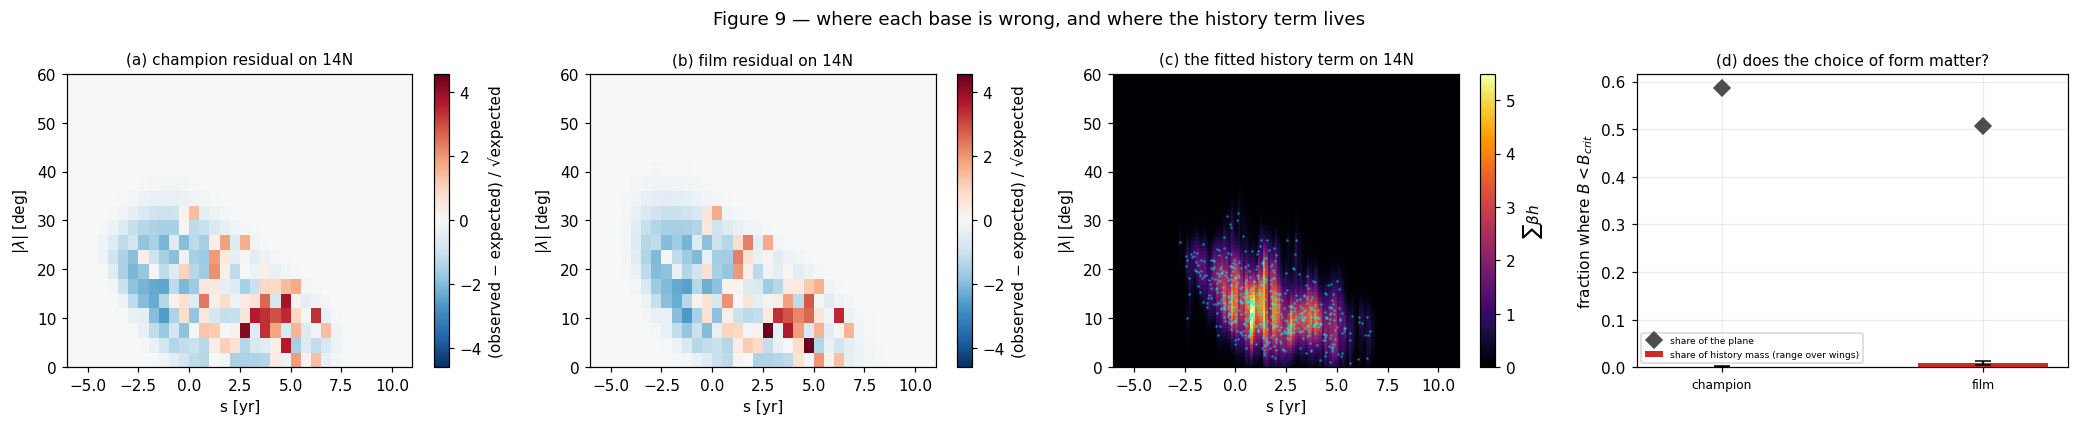

champion : 0.08% of the history term's mass lands where B < B_crit (range 0.02% to 0.24% over 6 wings), on 58.7% of the plane
film     : 0.86% of the history term's mass lands where B < B_crit (range 0.46% to 1.30% over 6 wings), on 50.7% of the plane

Small means additive-in-field and additive-in-intensity are the same model here, so the choice
was computational. Read the RANGE too: a wide one is the base telling you its B = B_crit contour
is not pinned, not noise in this measurement.


In [147]:
# Given: Figure 9 — the two bases' errors, and where the history term puts its mass, all on the same
# held-out wing. Panels (a) and (b) are the two bases' residuals with no history; (c) is the fitted
# history term; (d) is how much of its mass lands where the latent field is subcritical, which is the one
# place the additive-in-intensity choice is a real physical commitment rather than a convention.
RES_CYCLE = FOLD_CYCLES[0]
RES_WING = FOLD_UNITS[RES_CYCLE][0]
res_fold = {base: fold_base_of(RUNS[(base, "nohist")], RES_CYCLE)
            for base in ("champion", "film") if (base, "nohist") in RUNS}
res_bank_fold = {base: fold_base_of(RUNS[(base, "bank")], RES_CYCLE)
                 for base in ("champion", "film") if (base, "bank") in RUNS}

lat_held, t_held = RAW_EVENTS[RES_WING]
shift = align_one(t_held, lat_held, T0_START[RES_WING], res_fold["champion"]["mu_b"])
s_held = t_held - (T0_START[RES_WING] + shift)
inside = (s_held > S_A) & (s_held < S_B)
RES_LAT, RES_SS = lat_held[inside], s_held[inside]
OBSERVED = binned_counts(RES_LAT, RES_SS)

panels = [(base, res_fold[base]["base_of"](RES_WING, res_fold[base]["a_of"](RES_WING)))
          for base in res_fold]
EXPECTED = {base: binned_expected(fn) for base, fn in panels}
RES_LIMIT = max(float(np.nanmax(np.abs((OBSERVED - e) / np.sqrt(np.maximum(e, 1.0)))))
                for e in EXPECTED.values())

hist_fold = res_bank_fold.get("champion", res_bank_fold.get("film"))
HIST_VALUES = history_field(H_LAM[:, None], H_S[None, :], RES_LAT, RES_SS, hist_fold["beta"])

fig, axes = plt.subplots(1, 4, figsize=(19.0, 3.9))
for ax, (tag, (base, fn)) in zip(axes, zip("ab", panels)):
    drawn = draw_residual_field(ax, OBSERVED, EXPECTED[base],
                                f"({tag}) {base} residual on {RES_WING}", limit=RES_LIMIT)
    plt.colorbar(drawn, ax=ax, label="(observed − expected) / √expected")
if len(panels) == 1:
    axes[1].axis("off")

drawn = draw_history(axes[2], HIST_VALUES, f"(c) the fitted history term on {RES_WING}",
                     events=(RES_LAT, RES_SS))
plt.colorbar(drawn, ax=axes[2], label=r"$\sum\beta h$")

# Measured on EVERY scored wing of every fold, not on one, because the number turns out to be
# unstable: on the `bank` arm the history term supplies about half the rate, so the base's own shape is
# only weakly pinned down, and two optimizer paths that agree on the held-out score to four decimals can
# disagree about where the field crosses threshold. That instability is itself a finding and is reported
# as a spread rather than hidden behind one wing.
SUBCRITICAL = {}
for base in res_bank_fold:
    shares, areas = [], []
    for cycle in RUNS[(base, "bank")]["folds"]:
        fold_here = fold_base_of(RUNS[(base, "bank")], cycle)
        params = RUNS[(base, "bank")]["fold_params"][str(cycle)]
        c_here = params.get("c")
        if c_here is None:
            c_here = float(np.exp(params["log_c"]))
        for label in FOLD_UNITS[cycle]:
            lat_w, t_w = RAW_EVENTS[label]
            off = align_one(t_w, lat_w, T0_START[label], fold_here["mu_b"])
            s_w = t_w - (T0_START[label] + off)
            keep = (s_w > S_A) & (s_w < S_B)
            fn_w = fold_here["base_of"](label, fold_here["a_of"](label))
            values_w = history_field(H_LAM[:, None], H_S[None, :], lat_w[keep], s_w[keep],
                                     fold_here["beta"])
            share, area = mass_below_critical(fn_w, float(c_here), values_w)
            shares.append(share)
            areas.append(area)
    SUBCRITICAL[base] = (float(np.mean(shares)), float(np.mean(areas)),
                         float(np.min(shares)), float(np.max(shares)))

position = np.arange(len(SUBCRITICAL))
axes[3].bar(position, [v[0] for v in SUBCRITICAL.values()], color="tab:red", width=0.5,
            yerr=[[v[0] - v[2] for v in SUBCRITICAL.values()],
                  [v[3] - v[0] for v in SUBCRITICAL.values()]], capsize=5.0,
            label="share of history mass (range over wings)")
axes[3].plot(position, [v[1] for v in SUBCRITICAL.values()], "D", ms=7.0, color="0.3",
             label="share of the plane")
axes[3].set_xticks(position)
axes[3].set_xticklabels(list(SUBCRITICAL), fontsize=8)
axes[3].set_ylabel("fraction where $B < B_{crit}$")
axes[3].set_title("(d) does the choice of form matter?", fontsize=10)
axes[3].legend(fontsize=6)

fig.suptitle("Figure 9 — where each base is wrong, and where the history term lives")
plt.tight_layout()
plt.show()

for base, (share, area, lo, hi) in SUBCRITICAL.items():
    print(f"{base:9s}: {share:.2%} of the history term's mass lands where B < B_crit "
          f"(range {lo:.2%} to {hi:.2%} over {len(FOLD_CYCLES) * 2} wings), on {area:.1%} of the plane")
print("\nSmall means additive-in-field and additive-in-intensity are the same model here, so the choice\n"
      "was computational. Read the RANGE too: a wide one is the base telling you its B = B_crit contour\n"
      "is not pinned, not noise in this measurement.")

Nothing is marked for you here. The block below is for your tutor.

```text
TUTOR DIRECTIVE — Section 4, the same question asked of two bases.

Material: the student is about to fit the same eight history coefficients on top of two different base
models and compare what each buys, held out, against a resolution floor they declare first. None of it
is written yet.

This section carries PREDICTIONS 2 and 3 of the session's four.

PREDICTION 2, required before anything else here. The notebook contains a four-way table of possible
outcomes. Require the student to pick one cell, in writing, and give the mechanism they expect to
produce it. "I don't know" is not available; an argued wrong guess is the point. Do not evaluate their
choice and do not hint at which cell the notebook lands in.

PREDICTION 3. Require a number: the history gain on the champion, in nats per hemicycle-year, written
down before they see it, together with the resolution floor they would compare it against. The floor is
computable from quantities the notebook states, so make them compute it rather than guess it. Week 5's
largest honest effect and its largest leak are both in the notebook text as anchors.

Destinations.

1. Why a nested comparison does not travel between bases. Require them to state what "nested" means
   here in terms of the coefficients, and then why two nested comparisons with different outer models
   are two different quantities. Then push: so what *is* the difference between the two numbers? Bridge
   towards it being a measurement of something rather than a nuisance. Do not name it.

2. What each base can and cannot absorb. Require them to say what the two bases have in common — both
   smooth, both set by two numbers per wing — and what the history features have that neither has. The
   word to require is realization-specific, or their own equivalent of it. Then ask which base should
   absorb more of the systematic part, and why having far more parameters is the relevant fact.

3. The floor, and what it is for. Require them to say what makes a difference unresolvable, and the
   difference between "small effect" and "no detection". If they report a number smaller than the
   floor as a small effect, name it.

4. The tie check. The notebook refits the coefficients with the catalog's identical timestamps broken.
   Require them to predict, before seeing it, what fraction of the shortest channel survives, and to
   say what each possible outcome would mean for the headline. This is the most consequential single
   number in the week and they should know that before they see it.

5. The trade between the coefficients and the global scale. Both add expected count; they separate only
   by shape. Ask what would happen if the coefficients were not bounded, and let them reach that the
   model would stop being self-exciting at all. The notebook bounds them; ask what it costs to bound
   them, and what pressing the bound would mean.

Prefer as anchors the targets least likely to be in play yet: nested model, degeneracy, data leakage,
feature engineering.
```

### Dialogue for Section 4 — where the conversation should land (instructor only)

*Nesting.* The history model reduces to the base exactly at `ν = 0`, so the comparison is a
likelihood-ratio question with the base as the null. Change the base and you change the null: the same
alternative tested against two different nulls gives two different answers, and both are correct
answers to different questions. The thing a student should reach is that the *gap* between the two
answers measures how much of the clustering either explanation could claim — the degenerate share.

*What the bases share.* Both are smooth in `(|λ|, s)` and determined by two numbers per wing: the
champion through its amplitude map, the network through its two conditioning inputs. So neither can
put a bump at one place in one wing unless the bump is systematic. A history term can, because it reads
that wing's own events. The honest expectation is therefore `Δ(champion) ≥ Δ(neural)`, and the "larger
on neural" cell is the one that should prompt a check of the epoch budget rather than a claim.

*The floor.* `max(paired standard error, seed spread)`. On three fold cycles the seed spread is
1.0019 nats, which is larger than most effects in this program — so on the shipped profile almost
nothing is resolvable, and saying that plainly is the correct result. A student who treats 0.3 nats as
a small positive effect has mistaken a measurement for a number.

*The tie check.* 16.4% of inter-arrival times are exactly zero, by construction of the catalog. If
the shortest channel's coefficient collapses when the ties are jittered, that channel was measuring the
observing cadence. If it survives, the 1–2 day excess Week 1 found is doing real work. Either way the
answer travels with the coefficient everywhere it is quoted.

*The `β`–`c` trade.* Both add expected count and separate only by shape — and `ℓ` = 10° spans a sixth
of the latitude domain while 60 days is under 1% of the window, so that channel is nearly flat on the
scale of a wing and trades almost freely against `c`. Unbounded, the fit hands the whole count to the
history term and drives `c` to zero: formally a better likelihood, and not a self-exciting process at
all. The bound at `n < 1` is the model family's own boundary, so bounding costs nothing we are entitled
to; but a fit that presses it is reporting the bound, not a measurement.

---
## 5 · And the weakest reading: the ablation on one base

No history, the two shortest timescales only, the full bank — held out on one base, scored both ways.
This is where a week like this would normally *start*, and it is where this notebook ends up, for the
reason Sections 3 and 4 have now made concrete: a single-base held-out score cannot separate
"the history term found memory" from "the history term mopped up the base model's error", and it is the
reading a wrong base corrupts most easily. Everything it says, Section 4 has already said better.

It is still worth having. It is the reading everyone else will quote; it carries the time-rescaling
statistic, which sees the times through the marginal rate alone and can therefore disagree with the
likelihood; and the short-`τ` row answers what the full bank cannot — whether the two shortest
channels carry whatever is there on their own.

In [148]:
### TASK 65: The three-way board, against the floor
### BEGIN SOLUTION
def draw_board(ax, board, base="champion", source=HEADLINE):
    """Held-out score per arm, with each arm's resolution floor as an error bar around the no-history row."""
    rows = board.loc[base] if base in board.index.get_level_values(0) else board.iloc[0:0]
    arms = [a for a in ("nohist", "short", "bank") if a in rows.index]
    position = np.arange(len(arms))
    values = [rows.loc[a, "held_nll"] for a in arms]
    ax.bar(position, values, width=0.55, color=["0.6", "tab:blue", "tab:purple"][:len(arms)])
    reference = rows.loc["nohist", "held_nll"] if "nohist" in rows.index else np.nan
    if np.isfinite(reference):
        ax.axhline(reference, color="k", lw=1.0, ls=":")
        floor = float(np.nanmax(rows["floor"].to_numpy())) if "floor" in rows else np.nan
        if np.isfinite(floor):
            ax.axhspan(reference - floor, reference + floor, color="0.88", zorder=0,
                       label="±1 resolution floor")
    ax.set_xticks(position)
    ax.set_xticklabels(arms)
    ax.set_ylabel("held-out NLL [nats per hemicycle-yr]\n(lower is better)")
    ax.set_title(f"(a) {base}: none · short τ · full bank", fontsize=10)
    ax.legend(fontsize=7)


def draw_ks(ax, runs, source=HEADLINE):
    """The other metric. It sees the times through the marginal rate only, so it may disagree."""
    names = list(runs)
    for position, key in enumerate(names):
        table = rows_of(runs[key])
        values = table[f"ks ({source})"].to_numpy()
        ax.plot(np.full(len(values), position), values, "o", ms=4.5, alpha=0.7, color="0.45")
        ax.plot([position], [np.median(values)], "D", ms=7.0, color="tab:red")
    ax.set_xticks(np.arange(len(names)))
    ax.set_xticklabels([f"{b}\n{a}" for b, a in names], fontsize=7)
    ax.set_ylabel("KS statistic against Exp(1)")
    ax.set_title("(b) time rescaling: the metric that sees only the times", fontsize=10)


def draw_readings(ax, readings):
    """The week's three readings on one axis, each against the band below which it says nothing."""
    for row, item in enumerate(readings):
        resolved = abs(item["value"] - item["centre"]) > item["band"]
        ax.barh([row], [item["band"] * 2.0], left=item["centre"] - item["band"], height=0.52,
                color="0.88", zorder=0)
        ax.plot([item["centre"]], [row], "|", ms=14.0, color="0.45", zorder=2)
        ax.plot([item["value"]], [row], "D", ms=9.0, zorder=3,
                color="tab:green" if resolved else "tab:red")
        ax.text(item["value"], row + 0.30, f"{item['value']:+.3f}", fontsize=7.5, ha="center",
                color="tab:green" if resolved else "tab:red")
    ax.set_yticks(np.arange(len(readings)))
    ax.set_yticklabels([item["name"] for item in readings], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("nats per hemicycle-yr\n(grey = the band inside which a reading says nothing)")
    ax.set_title("most robust at the top; green = resolved, red = no detection", fontsize=10)
### END SOLUTION
# Reference workflow:
#   1. `draw_board`: one bar per arm of one base, the no-history level as a dotted line, and a shaded
#      band of one resolution floor either side of it. A bar inside the band has not been shown to be
#      different from the no-history row.
#   2. `draw_ks`: every arm's per-wing KS statistic as a cloud with its median marked. Do not average it
#      with the likelihood column — the two answer different questions and have different units.
#   3. Say which arm wins on each metric, and whether the two agree. If they disagree, that is a result
#      about the model and not a problem with the board.
#   4. `draw_readings`: one horizontal row per reading, in the order Sections 3, 4 and 5 produced them.
#      Each row gets a grey band of ±`band` around `centre`, the measured `value` as a marker, and a
#      colour that says whether the value escaped the band. Do not rescale the three rows onto one
#      common unit — say what the axis is and let two of them share it.

In [149]:
# Put your code for Task 65 here

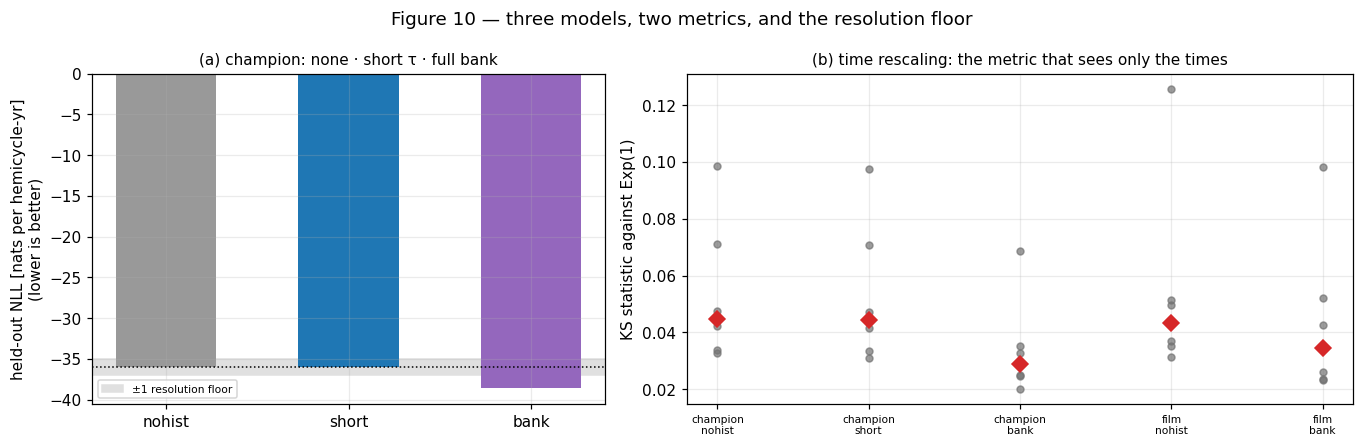

        fitted       n  held_nll   spread   delta      se   floor better      ks ks_ok
arm                                                                                   
nohist      29  0.0000  -35.9771  27.7841     NaN     NaN     NaN      —  0.0449   3/6
short       33  0.0081  -36.0050  27.7818  0.0279  0.0157  1.0019    5/6  0.0444   4/6
bank        37  0.4829  -38.5666  28.3287  2.5895  0.4286  1.0019    6/6  0.0290   4/6

best held-out likelihood: ('champion', 'bank') · best median KS: ('champion', 'bank') -- the two metrics agree


In [150]:
# Given: Figure 10 — the weakest reading, reported anyway and reported with its floor.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1), gridspec_kw=dict(width_ratios=[1.0, 1.3]))
draw_board(axes[0], BOARD)
draw_ks(axes[1], RUNS)
fig.suptitle("Figure 10 — three models, two metrics, and the resolution floor")
plt.tight_layout()
plt.show()

print(BOARD.loc["champion"].round(4).to_string())
best_nll = BOARD["held_nll"].idxmin()
best_ks = BOARD["ks"].idxmin()
print(f"\nbest held-out likelihood: {best_nll} · best median KS: {best_ks}"
      f"{' -- and the two metrics disagree' if best_nll != best_ks else ' -- the two metrics agree'}")

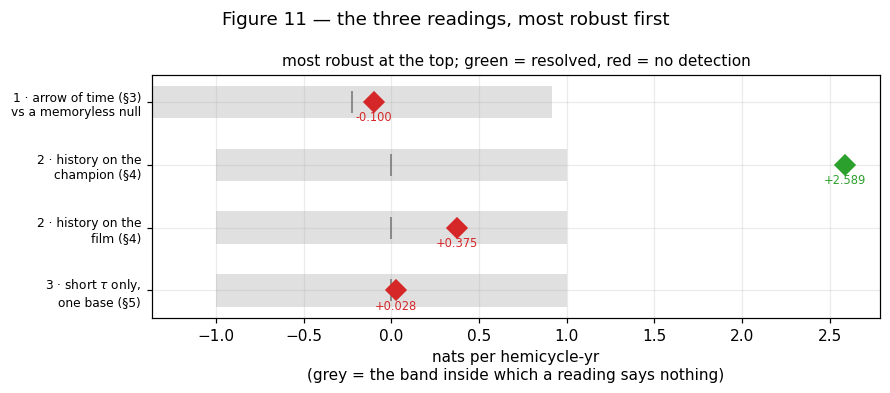

1 · arrow of time: -0.1000 against a null at -0.2255 +/- 0.5698 -> no arrow, on 0 of 6 wings beyond two null standard deviations.
2 · champion  +2.5895 +/- 0.4286 against a floor of 1.0019 -> resolved
2 · film      +0.3750 +/- 0.2328 against a floor of 1.0019 -> NO DETECTION
    -> cell 1: what the history term bought on the champion, the flexible base already had -- BASE MISSPECIFICATION, not memory
3 · share of the fitted coefficients on the two shortest timescales: 0.0% -- Week 1's one surviving result was at 1-2 days, so whatever the bank is doing, it is not that.


In [151]:
# Given: Figure 11 — the week's three readings on one axis, assembled from the cached runs rather than
# written in by hand, so the figure cannot drift away from what this run produced.
arrow = float(ASYMMETRY["statistic"].mean())
READINGS = [dict(name="1 · arrow of time (§3)\nvs a memoryless null", value=arrow,
                 centre=NULL_MEAN, band=2.0 * NULL_SD)]
for base, paired in (("champion", CHAMP_STATS), ("film", FILM_STATS)):
    if paired is not None:
        READINGS.append(dict(name=f"2 · history on the\n{base} (§4)", value=-paired["mean"],
                             centre=0.0, band=resolution_floor(paired)))
if ("champion", "short") in BOARD.index:      # the one reading Section 5 adds: four channels, not eight
    row = BOARD.loc[("champion", "short")]
    READINGS.append(dict(name="3 · short $\\tau$ only,\none base (§5)", value=float(row["delta"]),
                         centre=0.0, band=float(row["floor"])))

fig, ax = plt.subplots(figsize=(8.2, 3.6))
draw_readings(ax, READINGS)
fig.suptitle("Figure 11 — the three readings, most robust first")
plt.tight_layout()
plt.show()

detected = int(np.sum(np.abs(ASYMMETRY["statistic"] - NULL_MEAN) > 2.0 * NULL_SD))
print(f"1 · arrow of time: {arrow:+.4f} against a null at {NULL_MEAN:+.4f} +/- {NULL_SD:.4f} -> "
      f"{'AN ARROW IS DETECTED' if abs(arrow - NULL_MEAN) > 2.0 * NULL_SD else 'no arrow'}, on "
      f"{detected} of {len(ASYMMETRY)} wings beyond two null standard deviations.")

verdicts = {}
for base, paired in (("champion", CHAMP_STATS), ("film", FILM_STATS)):
    if paired is None:
        print(f"2 · {base:9s} not run at breadth '{BREADTH}'")
        continue
    gain, floor = -paired["mean"], resolution_floor(paired)
    verdicts[base] = gain > floor
    print(f"2 · {base:9s} {gain:+.4f} +/- {paired['se']:.4f} against a floor of {floor:.4f} -> "
          f"{'resolved' if verdicts[base] else 'NO DETECTION'}")
if set(verdicts) == {"champion", "film"}:
    cell = {(True, False): "cell 1: what the history term bought on the champion, the flexible base "
                           "already had -- BASE MISSPECIFICATION, not memory",
            (True, True): "cell 2: triggering survives the harder bar. Check the gap between the arms "
                          "before calling it a result",
            (False, False): "cell 3: no memory at these timescales, in this data",
            (False, True): "cell 4: the gain is larger on the flexible base, the one outcome to "
                           "distrust. Check the epoch budget and the seed first"}
    print(f"    -> {cell[(verdicts['champion'], verdicts['film'])]}")

short_share_fit = (np.asarray(RUNS[("champion", "bank")]["nu"])[list(SHORT_CHANNELS)].sum()
                   / max(np.sum(RUNS[("champion", "bank")]["nu"]), 1.0e-9))
print(f"3 · share of the fitted coefficients on the two shortest timescales: {short_share_fit:.1%} -- "
      f"Week 1's one surviving result was at 1-2 days, so "
      f"{'the fit puts weight there too.' if short_share_fit > 0.25 else 'whatever the bank is doing, it is not that.'}")

### Dialogue for Section 5 — reading the board (instructor only)

No student-facing directive here: Section 4 holds the prediction and Section 8 the interpretation. This
cell exists to say how to read what the board shows.

*If the bank's bar sits inside the floor band*, the week's single-base answer is "no detection", and
that is the sentence to use — not "a small improvement". It is also the expected outcome on three fold
cycles, where the seed spread alone is 1.0 nats.

*If the two metrics disagree*, that is worth a full exchange rather than a tie-break. The likelihood
sees counts, times and latitudes together; the KS statistic sees only the times, and only through the
latitude-integrated rate. A history term concentrated at short separations changes the *gaps* strongly
and the two-dimensional shape barely, so the KS column is the more sensitive of the two to exactly the
channel this week cares about. If KS improves while the likelihood does not, the honest statement is
that the short-gap structure is real and the two-dimensional fit does not pay for it.

*The short-`τ` row against the full bank* is the only genuine ablation on this board: one knob,
four channels instead of eight. If `short` recovers most of `bank`'s gain, the long channels are
decoration and Week 7 should know that. If it does not, the 60-day channel is doing something — and the
first thing to suspect is that it has traded against `c`, which is why Figure 8(a) shows the
coefficients channel by channel rather than only their sum.

---
## 6 · Anti-gaming: what one inequality sign buys

Every bank in this notebook sums over events with `sᵢ < s`. Change it to `sᵢ ≤ s` and each event
becomes its own parent. That is *data leakage* of the most compact kind available — one character —
and with *16.4% of this catalog's inter-arrival times exactly zero* it should be the largest leak the
program has measured. For scale: Week 5's worst was *+4.5716* nats per hemicycle-year (stopping the
training on the wing being scored) and Week 4's worst protocol violation was *+1.94*.

Work out the mechanism before the number. Under `sᵢ ≤ s` an event's own kernel contributes its full
value — `Σβ` — to its own intensity, while the compensator is *completely unchanged*: it integrates
`h` over the window, and `h` at the single point `s = sᵢ` is a measure-zero change to it. Same cost,
strictly larger event sum: the leaky model dominates the honest one at every `β`, so the fit moves
outwards.

*It does not run away, though.* That unchanged compensator is not zero — it grows linearly in `β`
while the event sum grows only logarithmically, so there is still an interior optimum and the leak is
finite. Figure 12(c) is that argument, computed. We cap the coefficients anyway, absurdly high, and
then report whether the cap was needed: "the leak is limited by the bound we imposed" and "the leak is
what the data supports" are different sentences and the output has to say which one it is.

In [152]:
### TASK 66: The leaky feature, and the nats it buys
### BEGIN SOLUTION
def draw_leak(ax, honest, leaky, references=()):
    """Per-wing held-out score with the strict bank and with the leaky one, and what else leaks."""
    labels = list(honest.index)
    position = np.arange(len(labels))
    ax.plot(position, honest.to_numpy(), "o-", ms=5.5, lw=1.3, color="tab:blue",
            label="strictly past ($s_i < s$)")
    ax.plot(position, leaky.to_numpy(), "s-", ms=5.5, lw=1.3, color="tab:red",
            label="leaky ($s_i \\leq s$)")
    for name, value, colour in references:
        ax.axhline(value, ls="--", lw=1.0, color=colour, label=name)
    ax.set_xticks(position)
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_ylabel("held-out NLL [nats per hemicycle-yr]")
    ax.set_title("(a) one character, every wing", fontsize=10)
    ax.legend(fontsize=7)


def draw_leak_scale(ax, measured, program=()):
    """This leak against every other leak the program has measured, on one axis."""
    names = [name for name, _ in program] + ["this week: $s_i \\leq s$"]
    values = [value for _, value in program] + [measured]
    colours = ["0.6"] * len(program) + ["tab:red"]
    ax.barh(np.arange(len(names)), values, color=colours, height=0.55)
    ax.set_yticks(np.arange(len(names)))
    ax.set_yticklabels(names, fontsize=8)
    ax.set_xlabel("what the shortcut buys [nats per hemicycle-yr]")
    ax.set_title("(b) the leaderboard nobody wants to top", fontsize=10)


def draw_leak_objective(ax, curves):
    """Why the leak is finite: one compensator, two event sums, and where each total turns over."""
    ax.axhline(0.0, color="k", lw=0.9)
    ax.plot(curves["n"], -curves["compensator"], lw=1.4, color="0.45", ls="-",
            label="$-$compensator (identical for both)")
    for arm, colour, mark in (("strict", "tab:blue", "o"), ("leaky", "tab:red", "s")):
        ax.plot(curves["n"], curves[f"{arm}_sum"], lw=1.0, ls=":", color=colour,
                label=f"event sum, {arm}")
        ax.plot(curves["n"], curves[f"{arm}_total"], lw=2.0, color=colour, label=f"total, {arm}")
        best = int(np.argmax(curves[f"{arm}_total"]))
        ax.plot([curves["n"][best]], [curves[f"{arm}_total"][best]], mark, ms=8.0, color=colour)
    top = max(float(np.max(curves[f"{arm}_total"])) for arm in ("strict", "leaky"))
    ax.set_ylim(top - 30.0, top + 12.0)                # the turnover, not the tail
    ax.set_xscale("log")
    ax.set_xlabel("branching ratio $n$ along the fitted direction")
    ax.set_ylabel("change in log L [nats per hemicycle-yr]")
    ax.set_title("(c) why it is finite: linear cost, logarithmic gain", fontsize=10)
    ax.legend(fontsize=6.5, loc="lower left")
### END SOLUTION
# Reference workflow:
#   1. `draw_leak`: the per-wing held-out score under the strict bank and under the leaky one, as two
#      connected series on the same axis, with horizontal lines for the earlier weeks' leaks so the scale
#      is visible rather than asserted.
#   2. `draw_leak_scale`: a horizontal bar per measured leak in the program with this week's last, so a
#      reader can see at a glance whether one character beat an epoch budget.
#   3. `draw_leak_objective`: the three curves the given cell hands you, against `n` on a log axis —
#      the shared compensator, each version's event sum, and each version's total, with a marker where
#      each total turns over. The two totals must be visibly the same shape, displaced.
#   4. Predict the number before you run it. Then check whether the fitted coefficients ended at the
#      bound; if they did, say what the figure is really showing.

In [153]:
# Put your code for Task 66 here

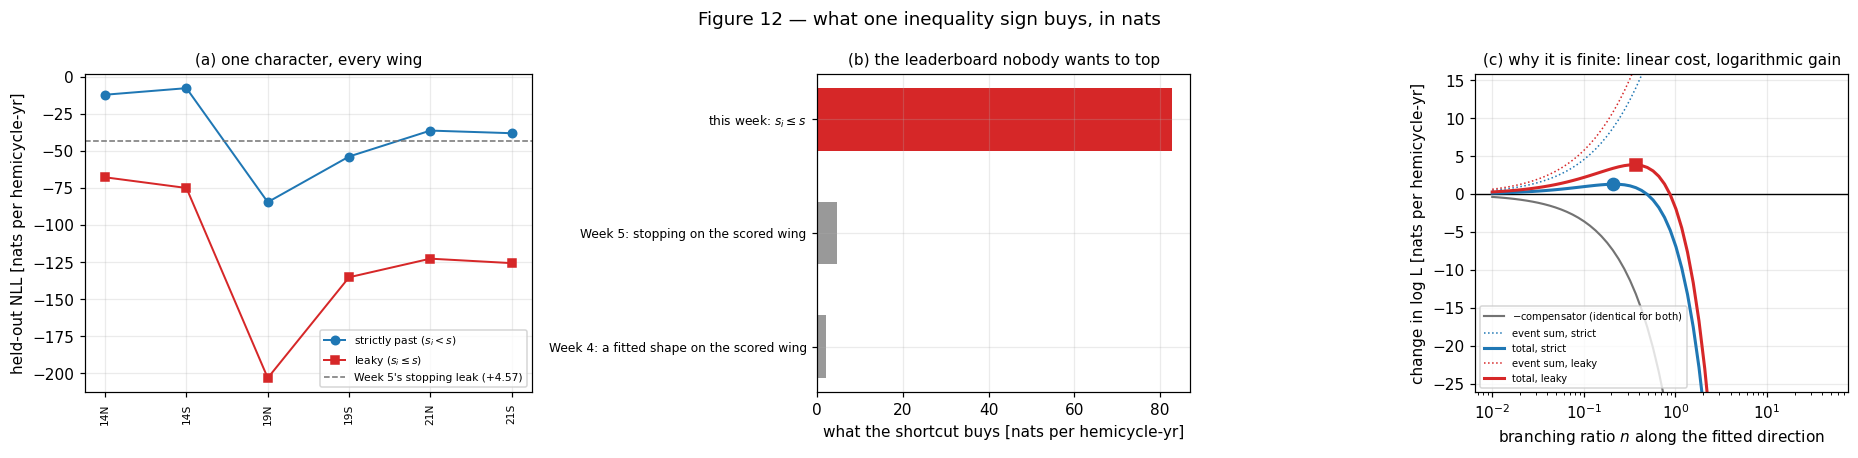

strictly past   :  -38.5666 nats per hemicycle-year
leaky (<=)      : -121.4779
the leak        :  +82.9113 nats per hemicycle-year, against Week 5's +4.5716 and Week 4's +1.94
fitted n        : 0.9121 against a cap of 50.0
an interior optimum at n = 0.37, so this is the leak the data supports -- panel (c) is why it is finite
one character, and it is 18x Week 5's stopping leak and 43x Week 4's worst protocol violation.


In [154]:
# Given: the leaky refit, and Figure 12. The base is held at the `bank` arm's fitted base — the second
# and last place this notebook freezes one. A joint refit would make the leak *larger*, so freezing
# gives a LOWER bound on it; the number is a bound either way, because the coefficients are capped.
RUNS[("champion", "bankleak")] = run_history("champion", "bankleak",
                                             frozen_from=RUNS[("champion", "bank")])
LEAK_RUN = RUNS[("champion", "bankleak")]
honest = rows_of(RUNS[("champion", "bank")])[f"nll/yr ({HEADLINE})"]
leaky = rows_of(LEAK_RUN)[f"nll/yr ({HEADLINE})"]
LEAK_GAIN = float((honest - leaky).mean())
LEAK_NU = np.asarray(LEAK_RUN["nu"])
at_bound = LEAK_NU.sum() > 0.9 * NU_MAX_LEAK

# The objective itself, on one held-out wing, along the fitted direction. This is the whole mechanism:
# the compensator is an integral of `h` over the window and `h`'s value at the single point s = s_i is
# measure zero in it, so BOTH versions pay the same cost, while the leaky event sum is strictly larger.
# The base is frozen here, which is how the leaky arm above was fitted.
LEAK_CYCLE = FOLD_CYCLES[0]
LEAK_LABEL = FOLD_UNITS[LEAK_CYCLE][0]
leak_base = fold_base_of(RUNS[("champion", "bank")], LEAK_CYCLE)
leak_intensity = count_matched(leak_base["base_of"](LEAK_LABEL, leak_base["a_of"](LEAK_LABEL)),
                               len(EVENTS[LEAK_LABEL][1]))
LEAK_DIRECTION = np.asarray(RUNS[("champion", "bank")]["nu"], dtype=float)
LEAK_DIRECTION = (LEAK_DIRECTION / LEAK_DIRECTION.sum() if LEAK_DIRECTION.sum() > 0
                  else np.full(N_CHANNELS, 1.0 / N_CHANNELS))
LEAK_CURVES = dict(n=np.logspace(-2.0, np.log10(NU_MAX_LEAK), 60), compensator=[],
                   strict_sum=[], leaky_sum=[], strict_total=[], leaky_total=[])
leak_wings = {arm: history_of(EVENTS, [LEAK_LABEL], strictly_past=strict)[LEAK_LABEL]
              for arm, strict in (("strict", True), ("leaky", False))}
leak_at0 = np.asarray(leak_intensity(leak_wings["strict"]["lat"], leak_wings["strict"]["s_true"]),
                      dtype=float)
leak_zero = float(np.sum(np.log(leak_at0)))
for value in LEAK_CURVES["n"]:
    beta = beta_of(value * LEAK_DIRECTION)
    LEAK_CURVES["compensator"].append(float(leak_wings["strict"]["A"] @ beta) / WINDOW_YEARS)
    for arm in ("strict", "leaky"):
        gained = (float(np.sum(np.log(leak_at0 + leak_wings[arm]["H"] @ beta))) - leak_zero)
        LEAK_CURVES[f"{arm}_sum"].append(gained / WINDOW_YEARS)
        LEAK_CURVES[f"{arm}_total"].append(gained / WINDOW_YEARS
                                           - LEAK_CURVES["compensator"][-1])
LEAK_CURVES = {key: np.asarray(value) for key, value in LEAK_CURVES.items()}

fig, axes = plt.subplots(1, 3, figsize=(17.0, 4.2), gridspec_kw=dict(width_ratios=[1.2, 1.0, 1.0]))
draw_leak(axes[0], honest, leaky,
          references=[("Week 5's stopping leak (+4.57)", float(honest.mean()) - 4.5716, "0.45")])
draw_leak_scale(axes[1], LEAK_GAIN,
                program=[("Week 4: a fitted shape on the scored wing", 1.94),
                         ("Week 5: stopping on the scored wing", 4.5716)])
draw_leak_objective(axes[2], LEAK_CURVES)
fig.suptitle("Figure 12 — what one inequality sign buys, in nats")
plt.tight_layout()
plt.show()

print(f"strictly past   : {float(honest.mean()):9.4f} nats per hemicycle-year")
print(f"leaky (<=)      : {float(leaky.mean()):9.4f}")
print(f"the leak        : {LEAK_GAIN:+9.4f} nats per hemicycle-year, against Week 5's +4.5716 and "
      f"Week 4's +1.94")
print(f"fitted n        : {LEAK_NU.sum():.4f} against a cap of {NU_MAX_LEAK}"
      f"{'  <-- AT THE BOUND' if at_bound else ''}")
print("at the cap, so the number is a statement about our bound, not about the data"
      if at_bound else
      f"an interior optimum at n = {LEAK_CURVES['n'][int(np.argmax(LEAK_CURVES['leaky_total']))]:.2f}, "
      f"so this is the leak the data supports -- panel (c) is why it is finite")
print(f"one character, and it is {LEAK_GAIN / 4.5716:.0f}x Week 5's stopping leak and "
      f"{LEAK_GAIN / 1.94:.0f}x Week 4's worst protocol violation.")

Nothing is marked for you here. The block below is for your tutor.

```text
TUTOR DIRECTIVE — Section 6, what one character buys.

Material: the student is about to refit the history coefficients with `<=` in place of `<`, so that
every event becomes its own parent, and measure what that buys on a held-out wing. It is not written
yet.

This section carries PREDICTION 4, the last of the four.

PREDICTION 4. Require a number in nats per hemicycle-year, written down before the cell is run, with
the two anchors the notebook gives: Week 5's stopping leak at +4.5716 and Week 4's worst protocol
violation at +1.94. Then require a reason for the number. A student who says "bigger than both" without
a mechanism has not made the prediction; push until they say what the extra term does to the event sum
and what it does to the integral. Those two answers are not symmetric and that asymmetry is the whole
mechanism. Do not supply it.

Then one follow-up, which is the harder half: ask whether the fitted coefficients would run away
without a bound. Both answers are reachable by argument and only one is right, so make them argue it
from the shape of the objective rather than from intuition.

Destinations.

1. Why this leak is different in kind from Week 5's. Stopping on the scored wing used the scored wing's
   own likelihood to pick a hyperparameter; this uses the scored wing's own events inside its own
   intensity at the same instant. Require them to say which quantity is being used before it exists.

2. The boundary case that makes it enormous. Require them to work out what a tie — two events with
   identical timestamps — does under `<=`, and connect it to the fraction of this catalog's gaps that
   are exactly zero. The fraction is in the notebook.

3. Why the notebook caps the coefficients, and what that means for how the number should be quoted.
   Require them to state what a capped leak measures. If they quote the number without the cap, name
   it.

4. The separation they must be able to make by the end of the week: a held-out wing's own earlier
   events are a legitimate input, its own simultaneous or later events are not, and no other wing's
   events are. Three cases, one sentence each. This is the destination Section 2 opened and it closes
   here.

Prefer as anchors the targets least likely to be in play yet: data leakage, conditional intensity,
history.
```

### Dialogue for Section 6 — where the conversation should land (instructor only)

*The mechanism, which is the point.* Under `sᵢ ≤ s` the event sum gains `log(Λ_base + Σβ + …)` instead
of `log(Λ_base + …)` at every event, while the compensator `∫∫` is identical: `h`'s value at the single
point `s = sᵢ` is measure zero inside an integral. Same cost, strictly larger event sum — the leaky
model dominates the honest one at every `β`, so the optimum moves outwards.

*It still has an interior optimum*, which is the half students and first drafts both get wrong
(including this notebook's BRIEF). "No cost" means no *extra* cost relative to the strict version, not
zero cost: the compensator is linear in `β` and the event sum only logarithmic, so `β` is bounded by
the likelihood itself. A student who concludes the fit must run away has the dominance argument right
and the boundedness argument missing — ask them to differentiate the objective. The notebook caps the
coefficients anyway and reports whether the cap mattered, because a capped leak and a measured leak are
different claims.

*The ties.* Two events with the same timestamp each become the other's parent at zero separation, so
both get the full `Σβ`, and 16.4% of consecutive gaps in this catalog are exactly zero. The leak is
therefore not a small edge case; it is concentrated in a sixth of the data.

*The three cases, which is the destination.* A held-out wing's own strictly earlier events: a
legitimate input, and what a conditional intensity means. Its simultaneous or later events: leakage,
and this section measures it. Any other wing's events: also leakage, and ruled out by the decoupling
convention rather than by this measurement.

*If a student asks whether the strict version is "really" leak-free*, the honest answer is that it is
leak-free *given the timestamps*, and the timestamps are the problem: first observation lags emergence
by a median ~65° of central-meridian distance, so a "parent" recorded before a "child" was not
necessarily born first. That is a caveat on the physics, not a leak in the protocol, and Section 8 is
where it goes.

---
## 7 · Physical plausibility: generating a self-exciting wing

Every week in this program has ended by asking its model to *produce* a wing rather than only to score
one, because a model can have an excellent likelihood and still generate something that looks nothing
like the Sun. Task 61's sequential generator is what makes that possible here, and the contrast with
`simulate_wing` is the point: the two base models can still use fixed-bound thinning, exactly as in
Week 5, and the history model cannot.

In [155]:
### TASK 67: A simulated self-exciting wing against the one the Sun made
### BEGIN SOLUTION
def hawkes_plausible(result, cycle, seed_offset=400):
    """Generate each wing of one held-out cycle from that fold's fitted conditional intensity."""
    fold = fold_base_of(result, cycle)
    ratio = branching_ratio(fold["nu"])
    rng = np.random.default_rng(SEED + seed_offset)
    rows, synthetic = [], {}
    for label in FOLD_UNITS[cycle]:
        lat_obs, s_obs = EVENTS[label]
        base_fn = fold["base_of"](label, fold["a_of"](label))
        lat_sim, s_sim = simulate_hawkes_wing(base_fn, fold["nu"], rng)
        synthetic[label] = (lat_sim, s_sim)
        predicted = (integrate_2d(np.asarray(base_fn(LAM_2D[:, None], S_2D[None, :]), dtype=float))
                     + float(history_compensator(lat_sim, s_sim) @ fold["beta"]))
        rows.append(dict(hemicycle=label, observed=len(lat_obs), predicted=predicted,
                         simulated=len(lat_sim), n=ratio,
                         centroid_obs=float(np.mean(lat_obs)),
                         centroid_sim=float(np.mean(lat_sim)) if len(lat_sim) else np.nan,
                         spread_obs=float(np.std(lat_obs, ddof=1)),
                         spread_sim=float(np.std(lat_sim, ddof=1)) if len(lat_sim) > 1 else np.nan,
                         gap_obs=float(np.median(np.diff(np.sort(s_obs))) / ONE_DAY),
                         gap_sim=(float(np.median(np.diff(np.sort(s_sim))) / ONE_DAY)
                                  if len(s_sim) > 1 else np.nan)))
    return pd.DataFrame(rows).set_index("hemicycle"), synthetic


def draw_hawkes_butterfly(ax, sources, cycle, title):
    """One cycle's wings, observed and generated, on one butterfly panel."""
    for (name, source), colour, size in zip(sources.items(), ("0.35", "tab:red"), (3.4, 3.4)):
        for label in FOLD_UNITS[cycle]:
            if label not in source:
                continue
            sign = 1.0 if label.endswith("N") else -1.0
            lat_here, s_here = source[label]
            ax.scatter(s_here, sign * np.asarray(lat_here), s=size, c=colour, alpha=0.45,
                       linewidths=0, label=name if label == FOLD_UNITS[cycle][0] else None)
    ax.axhline(0.0, color="k", lw=0.8)
    ax.set_xlim(S_A, S_B)
    ax.set_ylim(-LAM_MAX, LAM_MAX)
    ax.set_xlabel("s [yr]")
    ax.set_ylabel("latitude [deg]")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, markerscale=2.5, loc="upper right")


def draw_gap_distribution(ax, sources, cycle, bins=None):
    """The distribution of inter-event gaps in days — where a self-exciting process shows itself."""
    bins = np.logspace(-0.5, 2.2, 40) if bins is None else bins
    for (name, source), colour in zip(sources.items(), ("0.35", "tab:red")):
        gaps = np.concatenate([np.diff(np.sort(source[label][1])) / ONE_DAY
                               for label in FOLD_UNITS[cycle] if label in source
                               and len(source[label][1]) > 1])
        ax.hist(gaps[gaps > 0], bins=bins, density=True, histtype="step", lw=1.8, color=colour,
                label=name)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("gap between consecutive events [days]")
    ax.set_ylabel("density")
    ax.set_title("(c) where memory would show itself", fontsize=10)
    ax.legend(fontsize=7)
### END SOLUTION
# Reference workflow:
#   1. `hawkes_plausible`: rebuild the fold's base and coefficients, generate each held-out wing with
#      Task 61's generator, and tabulate the comparisons that make a physical claim — count, latitude
#      centroid, latitude spread, and the median gap in days. The predicted count has to include the
#      history term's compensator *of the generated events*, which is a different quantity from the
#      observed wing's.
#   2. `draw_hawkes_butterfly`: observed and generated on one butterfly panel, north up and south down,
#      with one legend entry per source rather than one per wing.
#   3. `draw_gap_distribution`: the inter-event gaps on log-log axes. This is the one view in which a
#      self-exciting process is visibly different from a Poisson one, so predict the shape first.
#   4. If the generator raises because the branching ratio is at or above 1, that is the result: report
#      it and move on rather than working around it.

In [156]:
# Put your code for Task 67 here

sequential thinning of the history model: 2 s


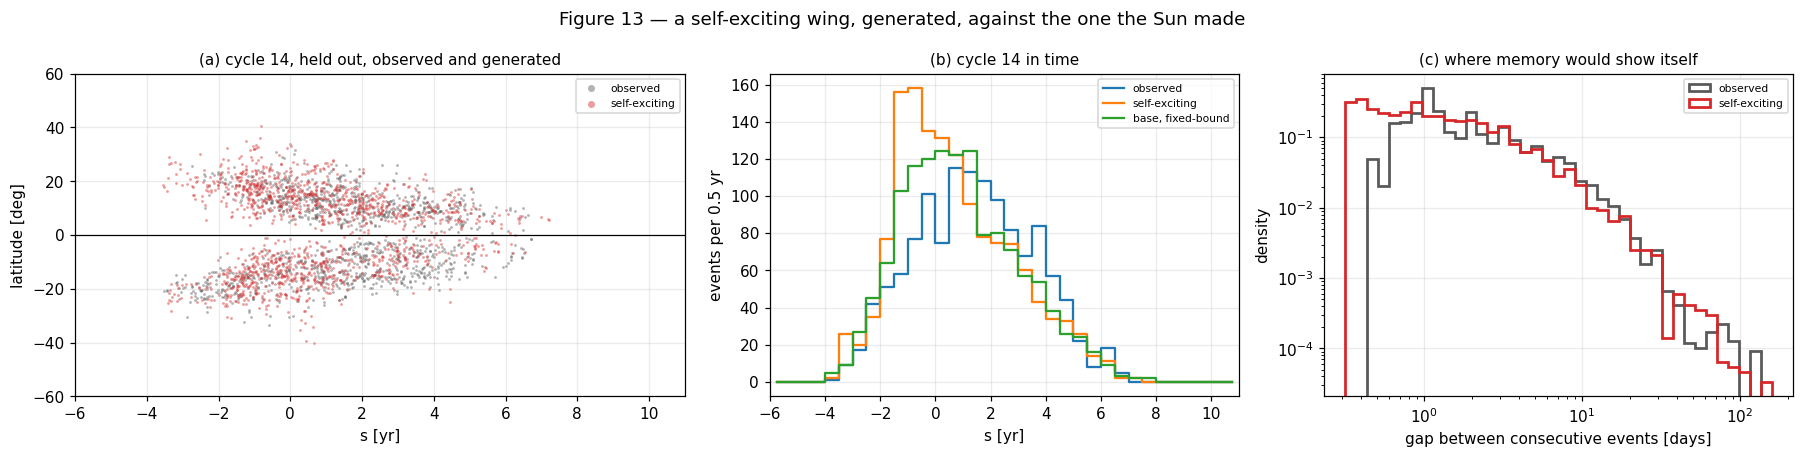


history:
           observed  predicted  simulated      n  centroid_obs  centroid_sim  spread_obs  spread_sim  gap_obs  gap_sim
hemicycle                                                                                                             
14N             613    748.782        775  0.485        12.683        14.445       5.640       6.735    2.956    2.510
14S             640    611.850        635  0.485        13.524        13.758       6.137       6.854    3.181    2.585

champion base:
           observed  predicted  simulated  centroid_obs  centroid_model  spread_obs  spread_model  accepted
hemicycle                                                                                                  
14N             613    726.419        749        12.683          14.172       5.640         6.678     0.081
14S             640    597.367        571        13.524          13.469       6.137         6.385     0.072

The no-history rows use `simulate_wing`; the history row cannot, 

In [157]:
# Given: Figure 13 — the held-out cycle, observed, and generated three ways. Two of the three use Week
# 5's fixed-bound thinning, which is still correct for a model with no history; the third cannot, and
# that is the contrast.
PLAUS_CYCLE = FOLD_CYCLES[0]
started = time.time()
SOURCES = {"observed": {h: EVENTS[h] for h in FOLD_UNITS[PLAUS_CYCLE]}}
PLAUS = {}
try:
    PLAUS["history"], SOURCES["self-exciting"] = hawkes_plausible(RUNS[("champion", "bank")],
                                                                  PLAUS_CYCLE)
    print(f"sequential thinning of the history model: {time.time() - started:.0f} s")
except AssertionError as problem:
    print(f"the history model could not be generated from:\n   {problem}")

# Week 5's fixed-bound thinning, on the base model, unchanged. `plausible` reads a `run_variant`
# result -- the one Section 1 refitted -- rather than a history result, because it needs the spec the
# Week 4 resolver parses, and a history arm has no spec for the eight coefficients.
PLAUS["champion base"], SOURCES["base, fixed-bound"] = plausible(CHAMPION_RESULT, PLAUS_CYCLE)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1.0, 1.0]))
draw_hawkes_butterfly(axes[0], SOURCES, PLAUS_CYCLE,
                      f"(a) cycle {PLAUS_CYCLE}, held out, observed and generated")
draw_marginals(axes[1], SOURCES, PLAUS_CYCLE)
axes[1].set_title(f"(b) cycle {PLAUS_CYCLE} in time", fontsize=10)
draw_gap_distribution(axes[2], SOURCES, PLAUS_CYCLE)
fig.suptitle("Figure 13 — a self-exciting wing, generated, against the one the Sun made")
plt.tight_layout()
plt.show()

for name, table in PLAUS.items():
    print(f"\n{name}:")
    print(table.round(3).to_string())
print("\nThe no-history rows use `simulate_wing`; the history row cannot, because a fixed-bound draw has\n"
      "no past to condition on. Section 3 has the argument.")

### Dialogue for Section 7 — reading the generated wing (instructor only)

No student-facing directive: Section 6 holds the last prediction and Section 8 the interpretation.

*The gap distribution in panel (c) is the panel that matters.* A Poisson process with a smooth rate
gives a gap distribution that is close to exponential over the range where the rate is roughly
constant; a self-exciting process puts excess weight at the short end. Observed, this catalog has a
spike at zero days that *neither* model can produce, because no model here puts an atom at zero
separation — and that spike is the catalog's timestamp resolution, not the Sun. If a student reads the
missing spike as a failure of the model, that is the conversation to have.

*If the branching ratio pressed the bound in Section 4*, the generated wing will be dominated by
self-excitation and will look wrong — too clumped, often too many events in bursts. Say so plainly:
the generator is faithful to the fitted parameters, and the parameters are what is wrong.

*The count column has a subtlety worth naming if a student asks.* The predicted count for a history
model depends on the events it generates, because the history term's compensator is a function of them.
So "predicted" and "simulated" are not two estimates of one number here, the way they were in Week 5 —
the first is conditional on the second.

---
## 8 · Where this leaves us

Figure 11 has the three readings on one axis, in order of how much each depends on the base model
being right:

- *The arrow of time (§3)* is the reading a wrong base cannot fake. It needed a fitted base to measure
  against, but the base *cancels*, and the memoryless null absorbed the one thing that does not — the
  two directions' different compensators at the window's edges.
- *The two-arm comparison (§4)* turned the identifiability problem into a number. "Does history
  matter" is a nested comparison inside a base, so it has two answers, and the gap between them is the
  share of the clustering that a shared cause and a triggering mechanism can trade for each other.
  That gap is the closest thing to a measurement of the Cox-versus-Hawkes question this data produces.
- *The single-base ablation (§5)* is the reading everyone quotes and the weakest one: it cannot
  separate memory from base-model error, which is what the other two were built to do.

### What this data cannot decide, and why

Four limits, and none of them is a shortcoming of the fitting:

- *There is no longitude.* An *active nest* is compact in longitude — that is what makes it a nest —
  and we have integrated longitude away. Figure 14 is what that does: two configurations that are
  obviously different in longitude project onto *the same* picture in `(|λ|, s)`. This is the single
  biggest reason the week may not be able to decide, and longitude is *deferred* in this program: say
  so, and do not work around it.
- *The ~27-day solar rotation period sits inside the timescale grid*, between the 15-day and 60-day
  channels (Figure 2c). A region that rotates out of view and back produces a "child" at its own
  longitude's period, so a coefficient there is partly measuring visibility.
- *First observation is not emergence.* The median distance from central meridian at first observation
  is ~65°, so event times lag emergence by up to several days, unevenly, and a recorded parent need
  not have been born before its recorded child. The protocol is clean; the timestamps are not.
- *The shortest channel partly measures the catalog.* 16.4% of inter-arrival times are exactly zero
  because groups first recorded in the same observation share a timestamp. Section 4's first printed
  check quantifies this, and whatever it said travels with every coefficient above.

*Deferred rather than unsolved.* The global cycle, like longitude: a wing's history sum runs over its
own hemisphere for the whole of this program. A stochastic (Cox) latent field is out of scope too —
"Cox-like" named a *mechanism being argued about*, never a model being fitted.

*What would decide it.* Longitudes, which the composite catalog has and this program has deferred; or
a magnetogram-derived emergence time, which would remove the central-meridian lag; or a catalog whose
timestamps resolve better than a day, which would remove the ties. The order matters: the first of the
three is the one that would change the answer rather than sharpen it.

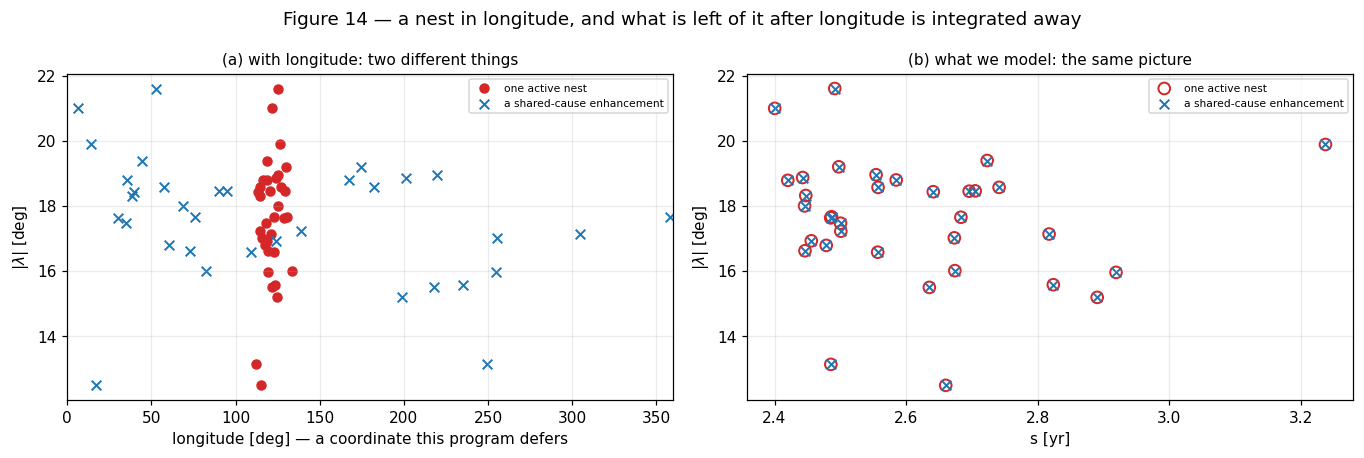

34 events, two longitude configurations, one projection -- and every statistic in this notebook reads panel (b).


In [158]:
# Given: Figure 14 — the deferred coordinate, drawn. Panel (a) uses a longitude this program does not
# model; that is the point of the figure. The two configurations share one cloud of (|lat|, s) positions
# by construction, so their projections are not merely similar — they are the same array.
NEST_RNG = np.random.default_rng(SEED + 8)
NEST_N = 34
NEST_LAT = 18.0 + NEST_RNG.normal(0.0, 1.8, NEST_N)
NEST_S = 2.4 + NEST_RNG.exponential(0.22, NEST_N)
NEST_LON = 120.0 + NEST_RNG.normal(0.0, 6.0, NEST_N)      # one nest: compact in longitude
DIFFUSE_LON = NEST_RNG.uniform(0.0, 360.0, NEST_N)        # a transient rate enhancement: not compact

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

axes[0].scatter(NEST_LON, NEST_LAT, s=34, marker="o", color="tab:red", label="one active nest")
axes[0].scatter(DIFFUSE_LON, NEST_LAT, s=40, marker="x", color="tab:blue", linewidths=1.3,
                label="a shared-cause enhancement")
axes[0].set_xlim(0.0, 360.0)
axes[0].set_xlabel("longitude [deg] — a coordinate this program defers")
axes[0].set_ylabel(r"$|\lambda|$ [deg]")
axes[0].set_title("(a) with longitude: two different things", fontsize=10)
axes[0].legend(fontsize=7, loc="upper right")

axes[1].scatter(NEST_S, NEST_LAT, s=58, marker="o", facecolor="none", edgecolor="tab:red", lw=1.3,
                label="one active nest")
axes[1].scatter(NEST_S, NEST_LAT, s=40, marker="x", color="tab:blue", linewidths=1.3,
                label="a shared-cause enhancement")
axes[1].set_xlabel("s [yr]")
axes[1].set_ylabel(r"$|\lambda|$ [deg]")
axes[1].set_title("(b) what we model: the same picture", fontsize=10)
axes[1].legend(fontsize=7, loc="upper right")

fig.suptitle("Figure 14 — a nest in longitude, and what is left of it after longitude is integrated away")
plt.tight_layout()
plt.show()

print(f"{NEST_N} events, two longitude configurations, one projection -- and every statistic in this "
      f"notebook reads panel (b).")

Nothing is marked for you here. The block below is for your tutor.

```text
TUTOR DIRECTIVE — Section 8, what this cannot decide.

Material: nothing is built in this section. The student has the three readings and is being asked what
they support.

This is where the four predictions get settled. Before anything else, go back through them with the
student — the pair-count question, the cell of the four-way table, the history gain in nats against
the floor, and the leak — and for each one require them to say not just whether they were right but
what mechanism they had in mind and whether that mechanism survived. A prediction that was wrong for
an interesting reason is the most valuable thing in the session and should be the one you spend
longest on.

Destinations.

1. The ordering of the week, stated back as an argument. Require them to say why the sections run in
   the order they do, in terms of what a wrong base model does to each reading. If they can only say
   "most robust first", push for the mechanism in each case.

2. The honest summary. Require one or two sentences stating what the evidence supports, with the
   resolution floor in them. If they state a conclusion that the floor does not license, name it. If
   the honest summary is "this data cannot decide", require them to say WHY in terms of a specific
   missing coordinate rather than in terms of sample size.

3. Longitude. Require them to explain why integrating it away is what makes the two mechanisms hard to
   separate, using the notion of a compact nest. Then require them to name it as deferred rather than
   proposing a workaround — the same move as every earlier week.

4. The three data caveats, ranked. Require them to put the rotation period, the central-meridian lag
   and the timestamp ties in order of how much each one threatens the week's headline, and to justify
   the ordering. There is no single right answer; there is a right kind of argument.

5. Finally, ask what single additional measurement would change the answer rather than sharpen it.
   Require a reason. Do not supply the answer; the notebook names three candidates and ranks them, so
   require the ranking to be argued rather than recalled.

Prefer as anchors the targets least likely to have been deployed by this point: Cox process,
degeneracy, time reversibility, active nest, solar rotation period.
```

### Dialogue for Section 8 — where the conversation should land (instructor only)

*The ordering, as an argument.* A smooth error in the base inflates a single-base held-out gain
directly; it inflates the two-arm comparison only through the *difference* between two bases, which is
why the difference is the measurement; and it cannot produce an arrow of time at all. So the three
readings are ordered by how much of the base's error leaks into them, and the order is a claim about
robustness rather than a presentation choice.

*The honest summary.* On the shipped profile the seed spread alone is 1.0019 nats, so almost nothing
in Section 5 is resolvable and the correct sentence names the floor. The defensible claim is about the
*structure* of the answer: that the question has two answers, that their gap is measurable, and that
the arrow-of-time reading is the one that would survive the base being wrong.

*Longitude.* A nest is a patch of the Sun a few degrees across in both coordinates. Project it onto
latitude and time and it becomes indistinguishable from a transient rate enhancement at that latitude —
which is exactly the shared-cause story. With longitude, a nest's events share a longitude and a
shared-cause enhancement need not; without it, the two mechanisms make the same prediction. That is why
this is a deferred coordinate and not a missing covariate.

*Ranking the caveats.* A defensible ranking: the ties first, because they are concentrated in a sixth
of the data and sit exactly on the channel Week 1 found; the central-meridian lag second, because it
scrambles parent-child order at the one-to-several-day scale, which is the same scale; the rotation
period third, because it falls between two channels rather than on one, and because its signature
would be periodic rather than monotone and so is at least in principle separable. A student who ranks
them differently and argues it has done the exercise.

*What would change the answer.* Longitude. The other two sharpen a measurement that is already being
made; longitude adds the coordinate in which the two mechanisms stop making the same prediction.

---
## Before you push: save the conversation

Type `wrap up` in your tutor session. It runs a closure and prints a `HANDOFF` block. Copy that block
and save it as `vocal_handoff.md` in your week 06 submission folder, then push it together with your
completed notebook. The HANDOFF is part of this week's deliverable: the figures show what you computed,
and the HANDOFF is the record of the argument you built around them. It is also what you paste at the
start of next week's session, so that your tutor picks up where you left off instead of starting cold.

If a number came out differently from what you predicted in the session — and at least one of them will —
go back to the tutor, paste the numbers, and take a second HANDOFF. The latest one supersedes the earlier.